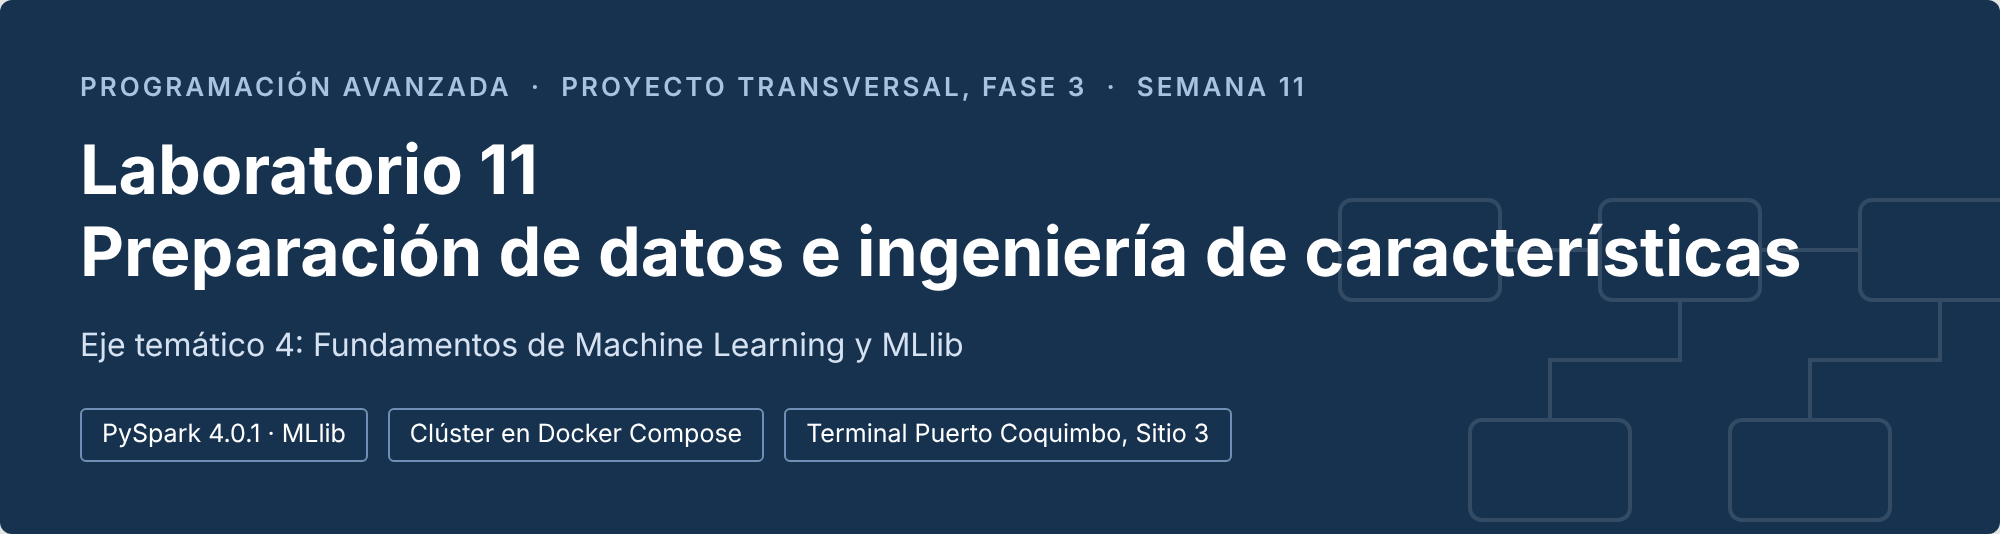

### Qué vamos a hacer hoy

Un modelo de Machine Learning no entiende texto, ni valores nulos, ni lecturas sueltas: solo entiende
**filas de números**. En este laboratorio construimos ese puente a partir de la capa limpia de la Fase 2.

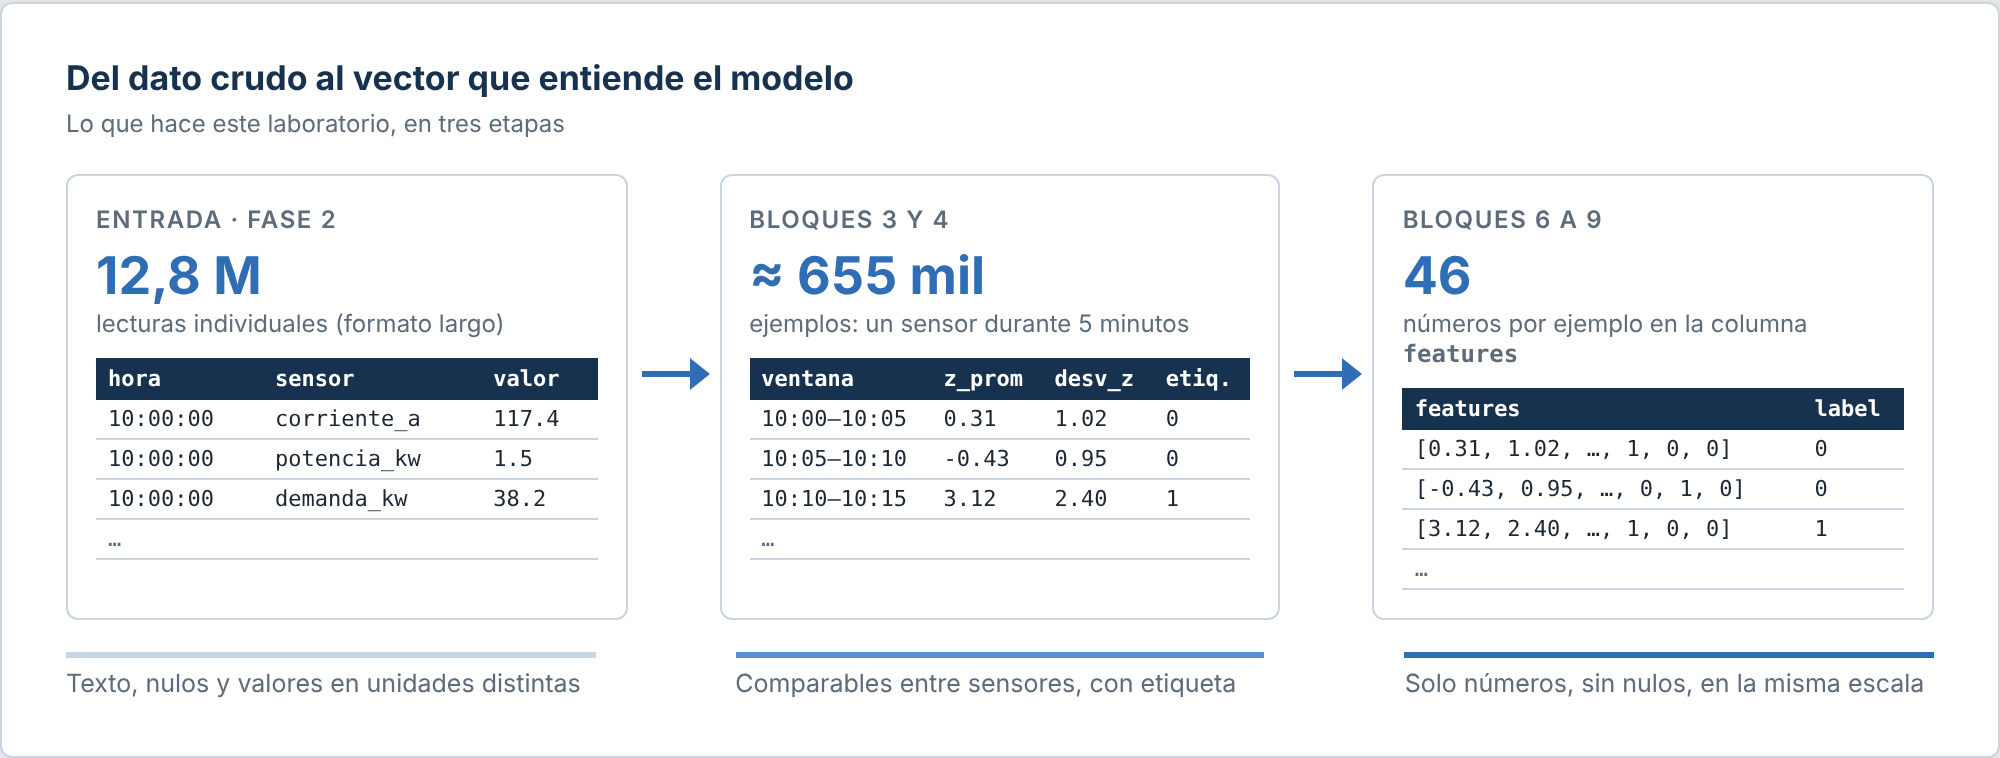

> **Alcance de esta semana.** Hoy no se entrena ningún modelo; eso corresponde a la semana 12. Hoy dejamos
> los datos listos, que en un proyecto real suele ser cerca del 80 % del trabajo.

### Palabras que vas a escuchar hoy

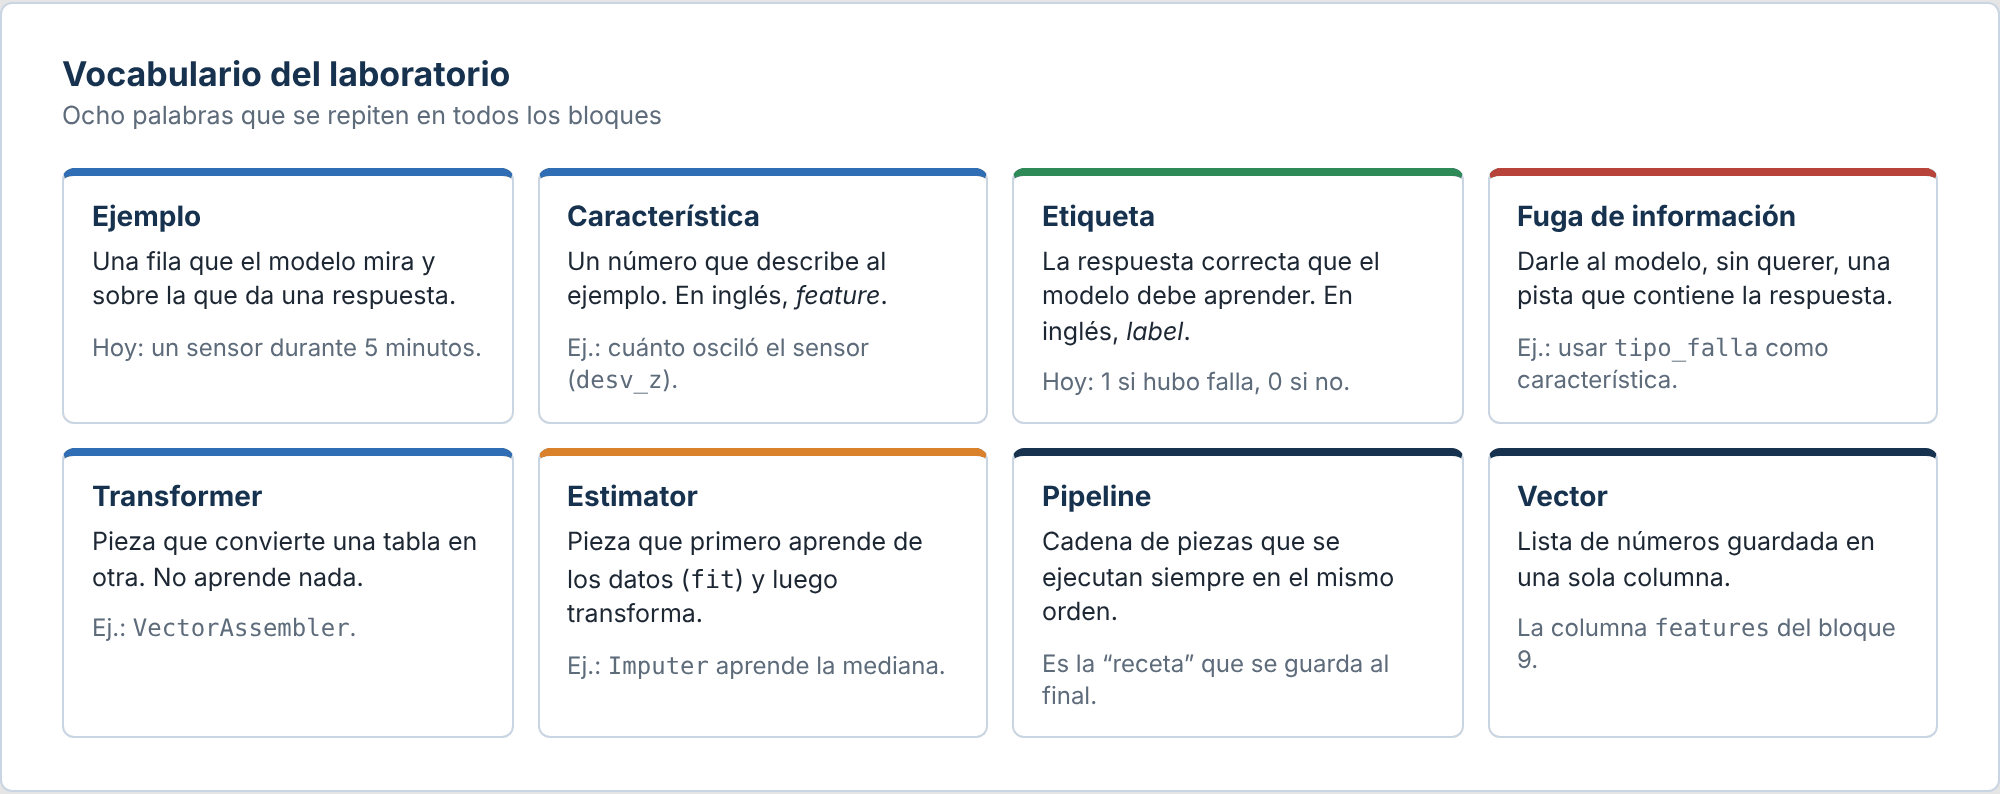

### Mapa del laboratorio

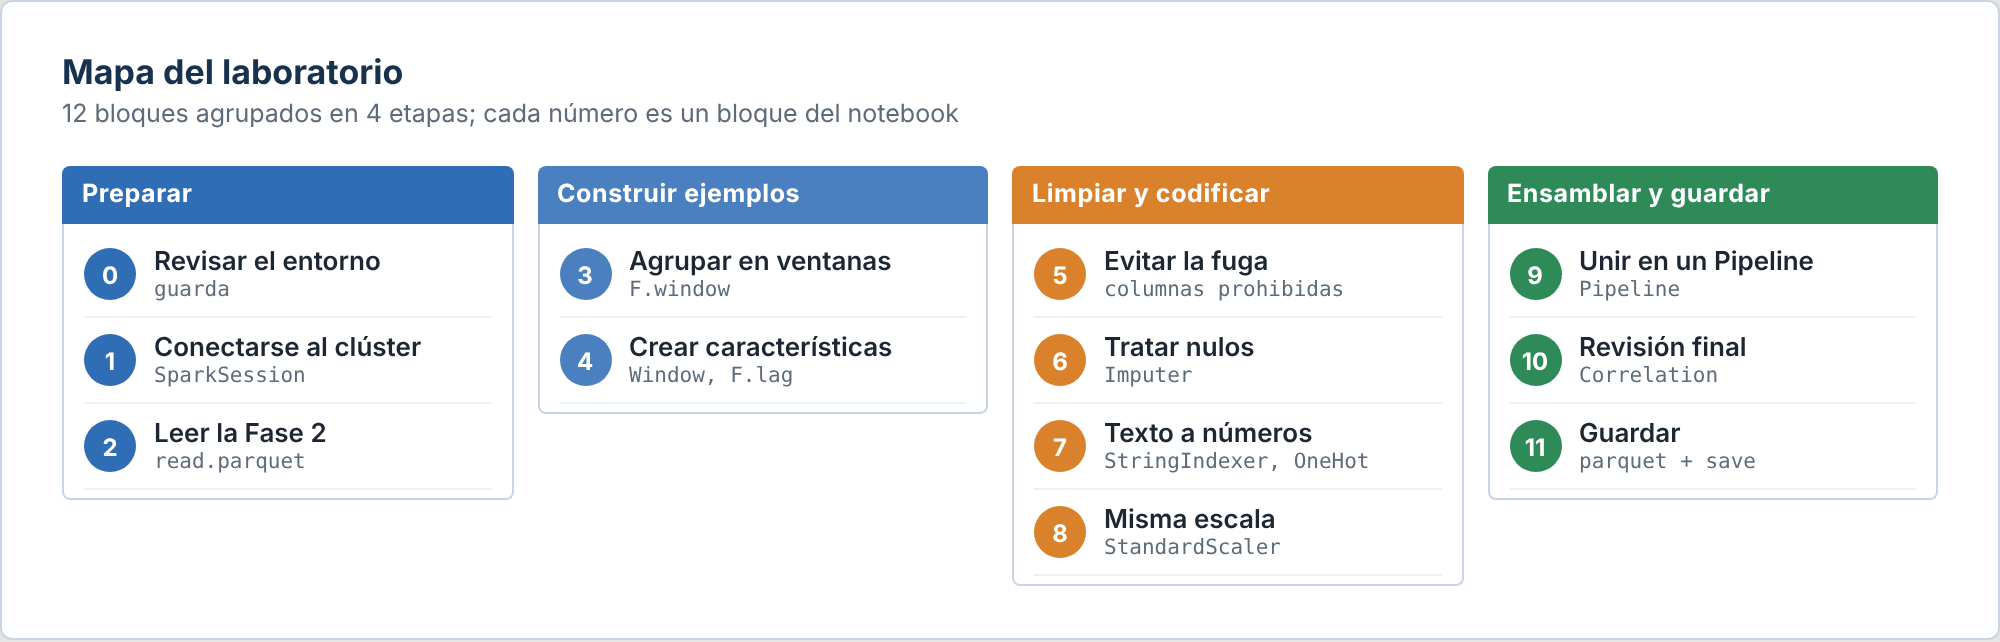

**Cómo leer este notebook.** Cada bloque sigue la misma estructura: **Objetivo** (qué se logra),
**Concepto clave** (la idea que hay que entender), **Resultado esperado** (cómo saber que vas bien) y una
**Pregunta de repaso** cuya respuesta se despliega con un clic.

Antes de cada celda de código hay un diagrama titulado **Cómo funciona esta celda**: el código aparece
dividido en partes numeradas y, a la derecha, cada número explica qué hace esa parte. Léelo primero y
después ejecuta la celda.

---
## Bloque 0 · Revisar el entorno

> **Objetivo.** Comprobar que estás en el Jupyter **del clúster** (puerto **8889**) y que tienes todo lo necesario.

Ejecuta la celda con **Shift + Enter**.

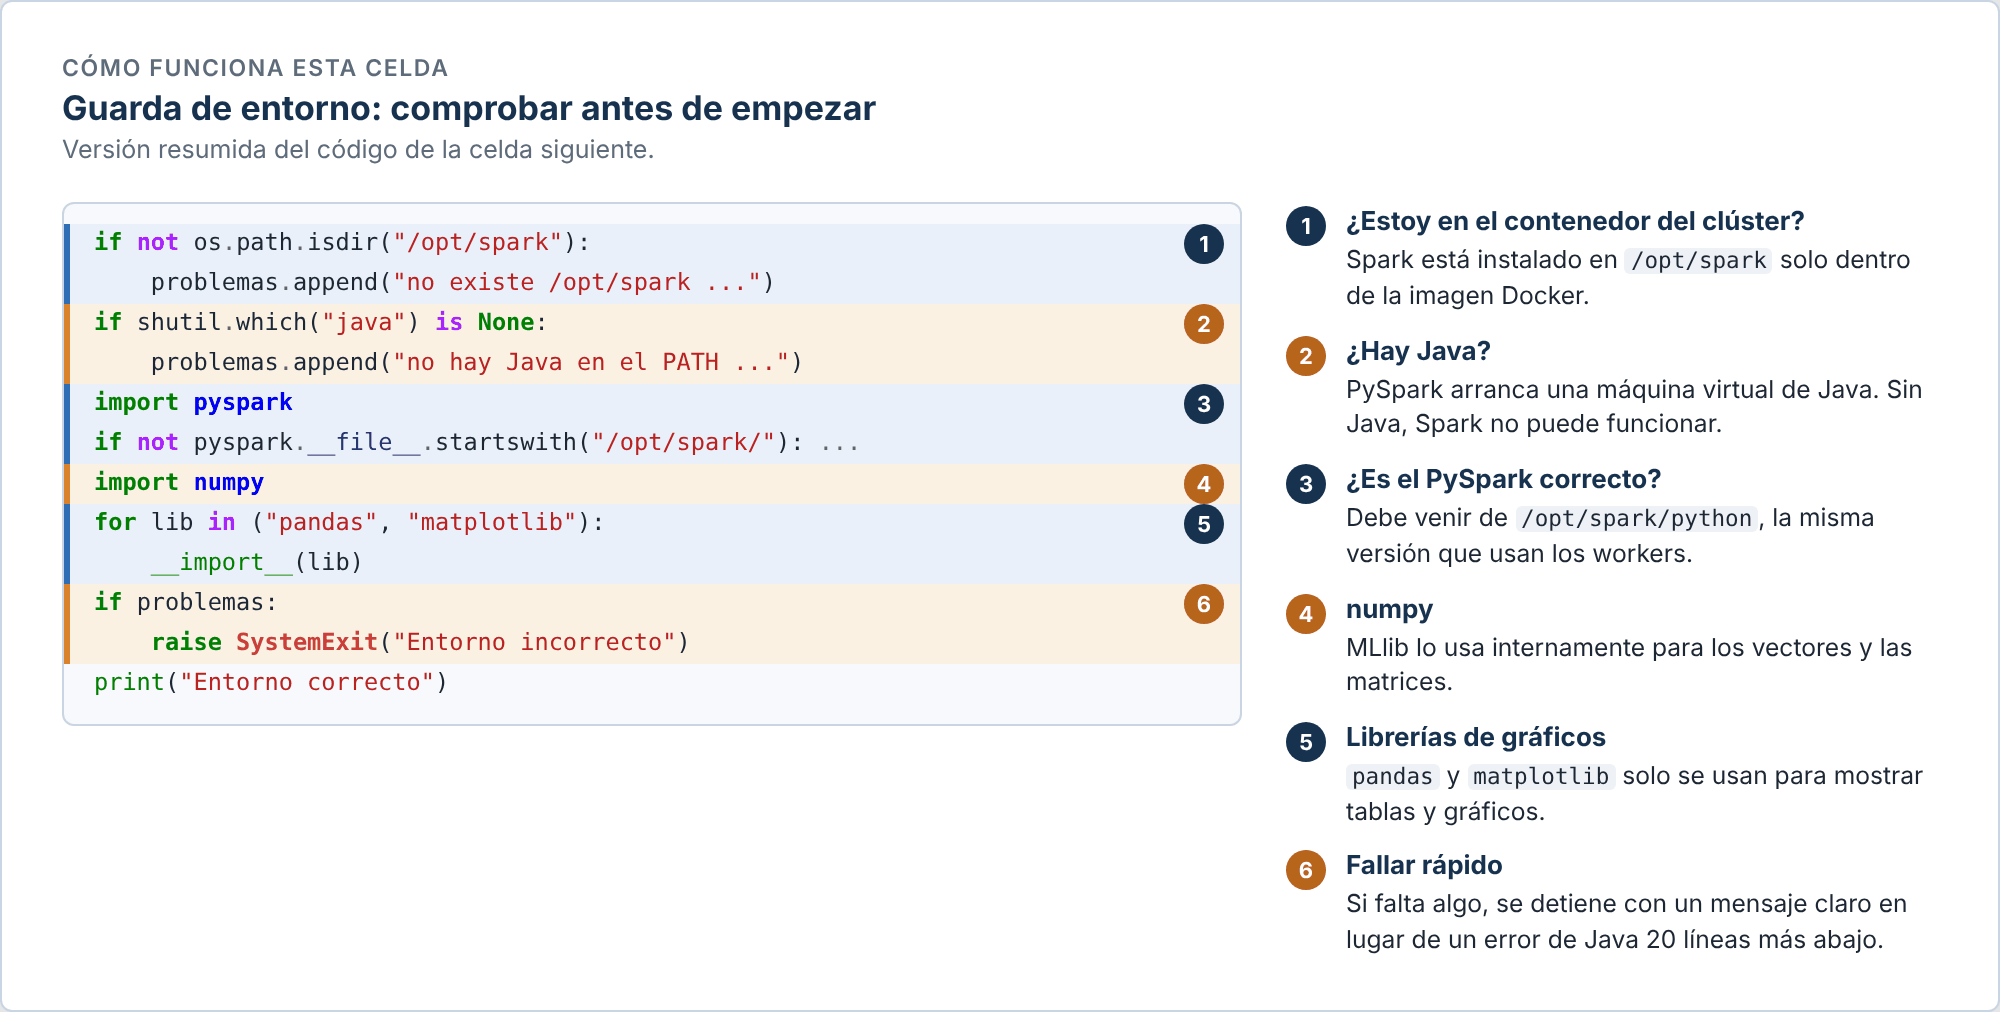

In [1]:
# --- Guarda de entorno: falla rápido y con un mensaje claro ---------------------
import os, shutil, sys

problemas, faltan_visuales = [], []

if not os.path.isdir("/opt/spark"):
    problemas.append("no existe /opt/spark: no estás en el contenedor del clúster")
if shutil.which("java") is None:
    problemas.append("no hay Java en el PATH: PySpark no puede arrancar")
try:
    import pyspark
    if not pyspark.__file__.startswith("/opt/spark/"):
        problemas.append(f"pyspark viene de {pyspark.__file__} y no de /opt/spark/python")
except ImportError:
    problemas.append("pyspark no es importable")
try:
    import numpy
except ImportError:
    problemas.append("falta numpy: MLlib no funciona sin él (agrégalo al docker/Dockerfile)")

for lib in ("pandas", "matplotlib"):
    try:
        __import__(lib)
    except ImportError:
        faltan_visuales.append(lib)

if problemas:
    print("EL ENTORNO NO ESTÁ LISTO")
    for p in problemas:
        print("-", p)
    print("\n   Abre el notebook en http://localhost:8889  (token: lab-sitio3)")
    raise SystemExit("Entorno incorrecto")

if faltan_visuales:
    print("Faltan librerías para los gráficos:", ", ".join(faltan_visuales))
    print("Ejecuta en una celda nueva:   %pip install " + " ".join(faltan_visuales))
    print("y luego reinicia el kernel (Kernel > Restart Kernel).")
    raise SystemExit("Faltan librerías de visualización")

print("Entorno correcto")
print(f"Python  {sys.version.split()[0]}  ·  PySpark {pyspark.__version__}  ·  numpy {numpy.__version__}")

Entorno correcto
Python  3.10.12  ·  PySpark 4.0.1  ·  numpy 2.2.6


<details>
<summary><b>Si aparece un error, haz clic aquí</b></summary>

| Mensaje | Qué hacer |
|---|---|
| `no existe /opt/spark` | Estás en el Jupyter equivocado. Abre **http://localhost:8889** |
| `falta numpy` | Agrega `numpy` al `pip install` del `docker/Dockerfile` y ejecuta `docker compose up -d --build` |
| `Faltan librerías para los gráficos` | Ejecuta `%pip install pandas matplotlib` en una celda y reinicia el kernel |

</details>

---
## Bloque 1 · Conectarse al clúster

> **Objetivo.** Crear la `SparkSession`, igual que en la Fase 2.

> **Concepto clave.** Lo nuevo es **`pyspark.ml`** (MLlib), la librería de Machine Learning de Spark.
> Trabaja con los mismos **DataFrames** que ya conoces. ¡No hay que aprender otra estructura de datos!

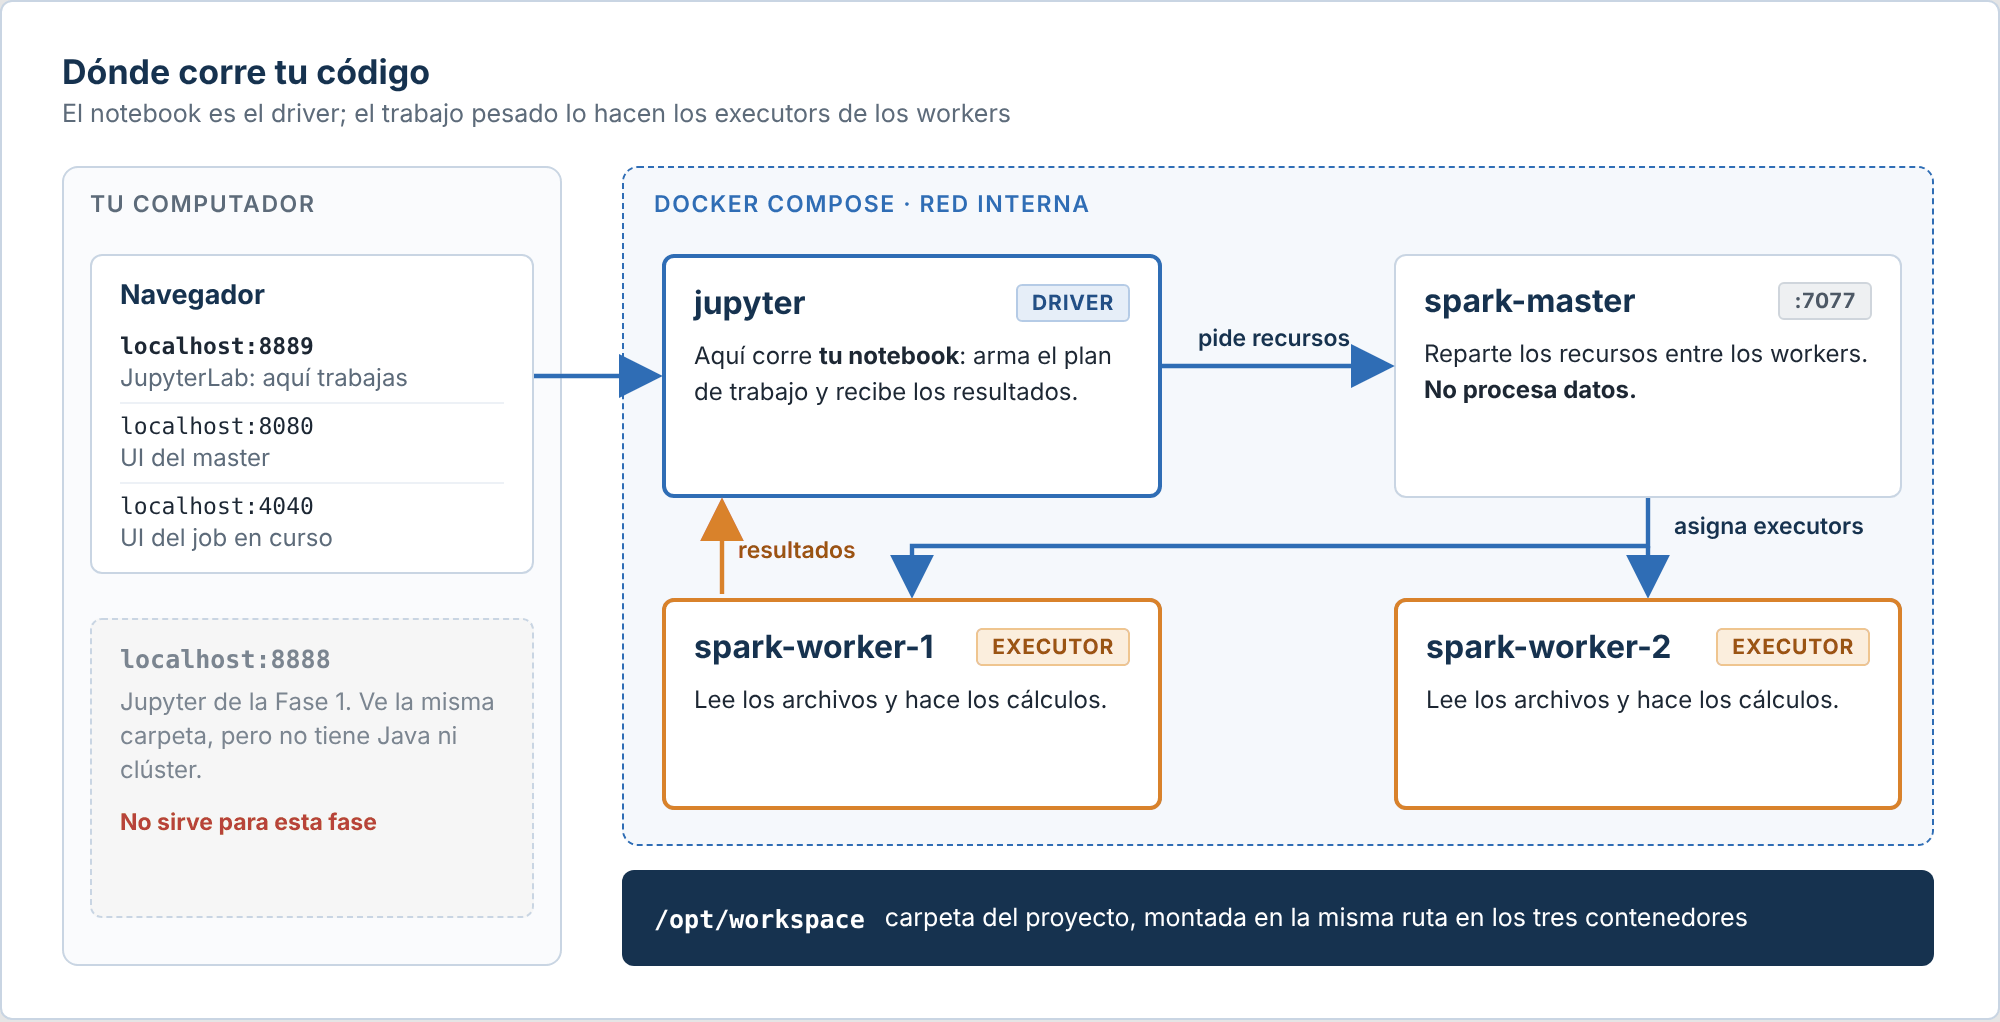

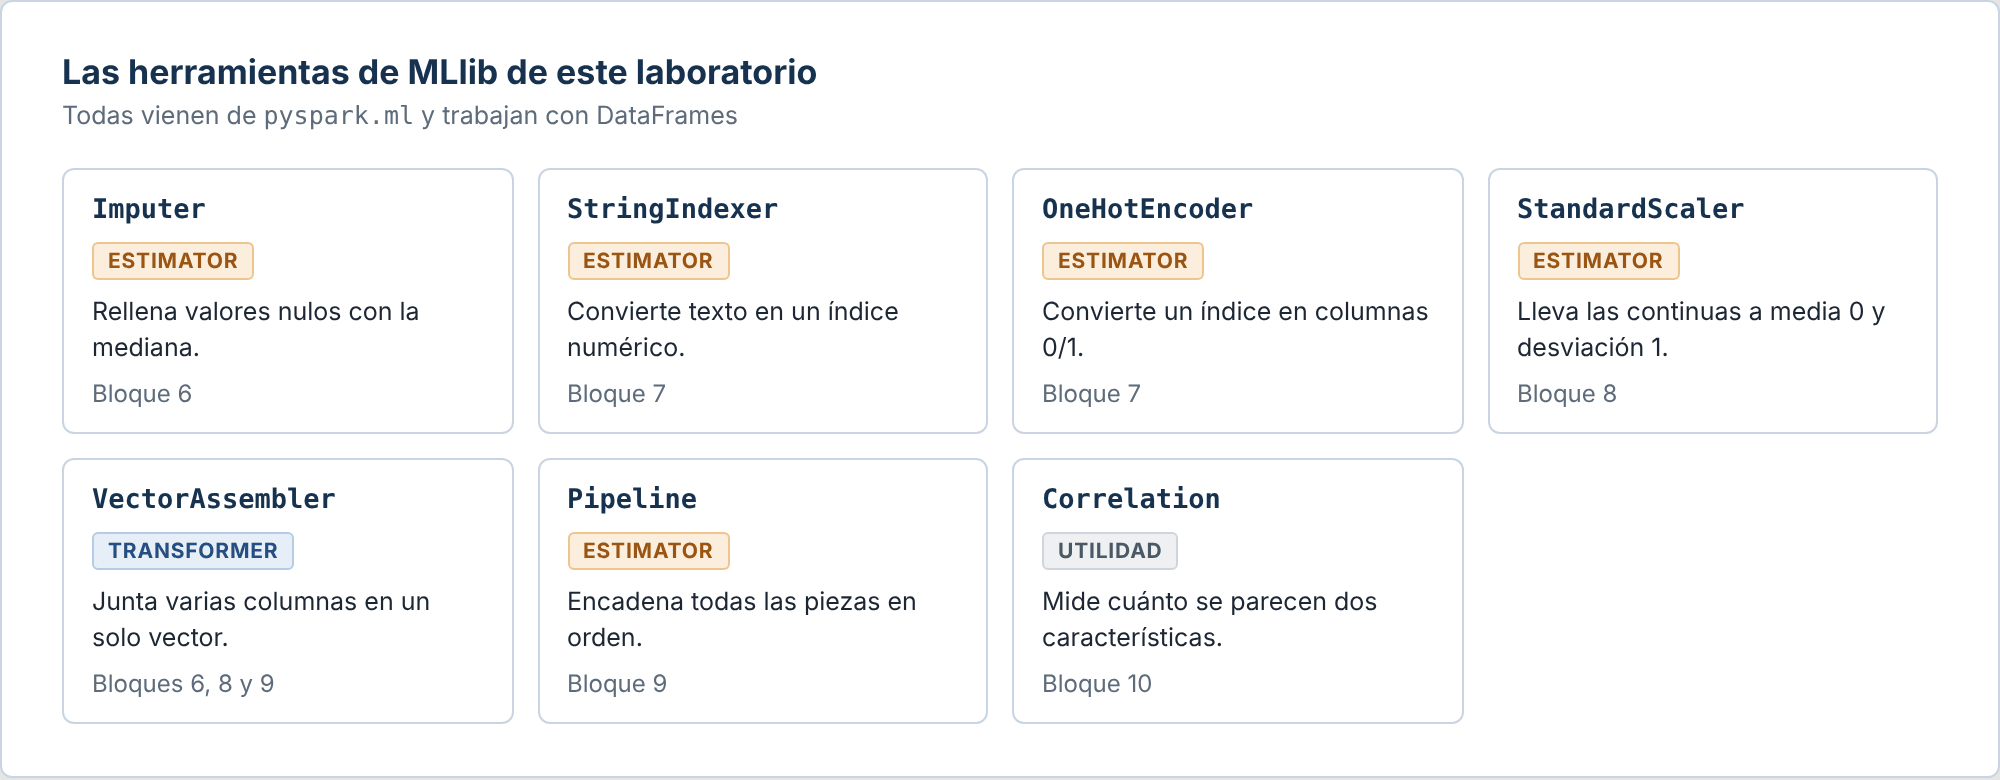

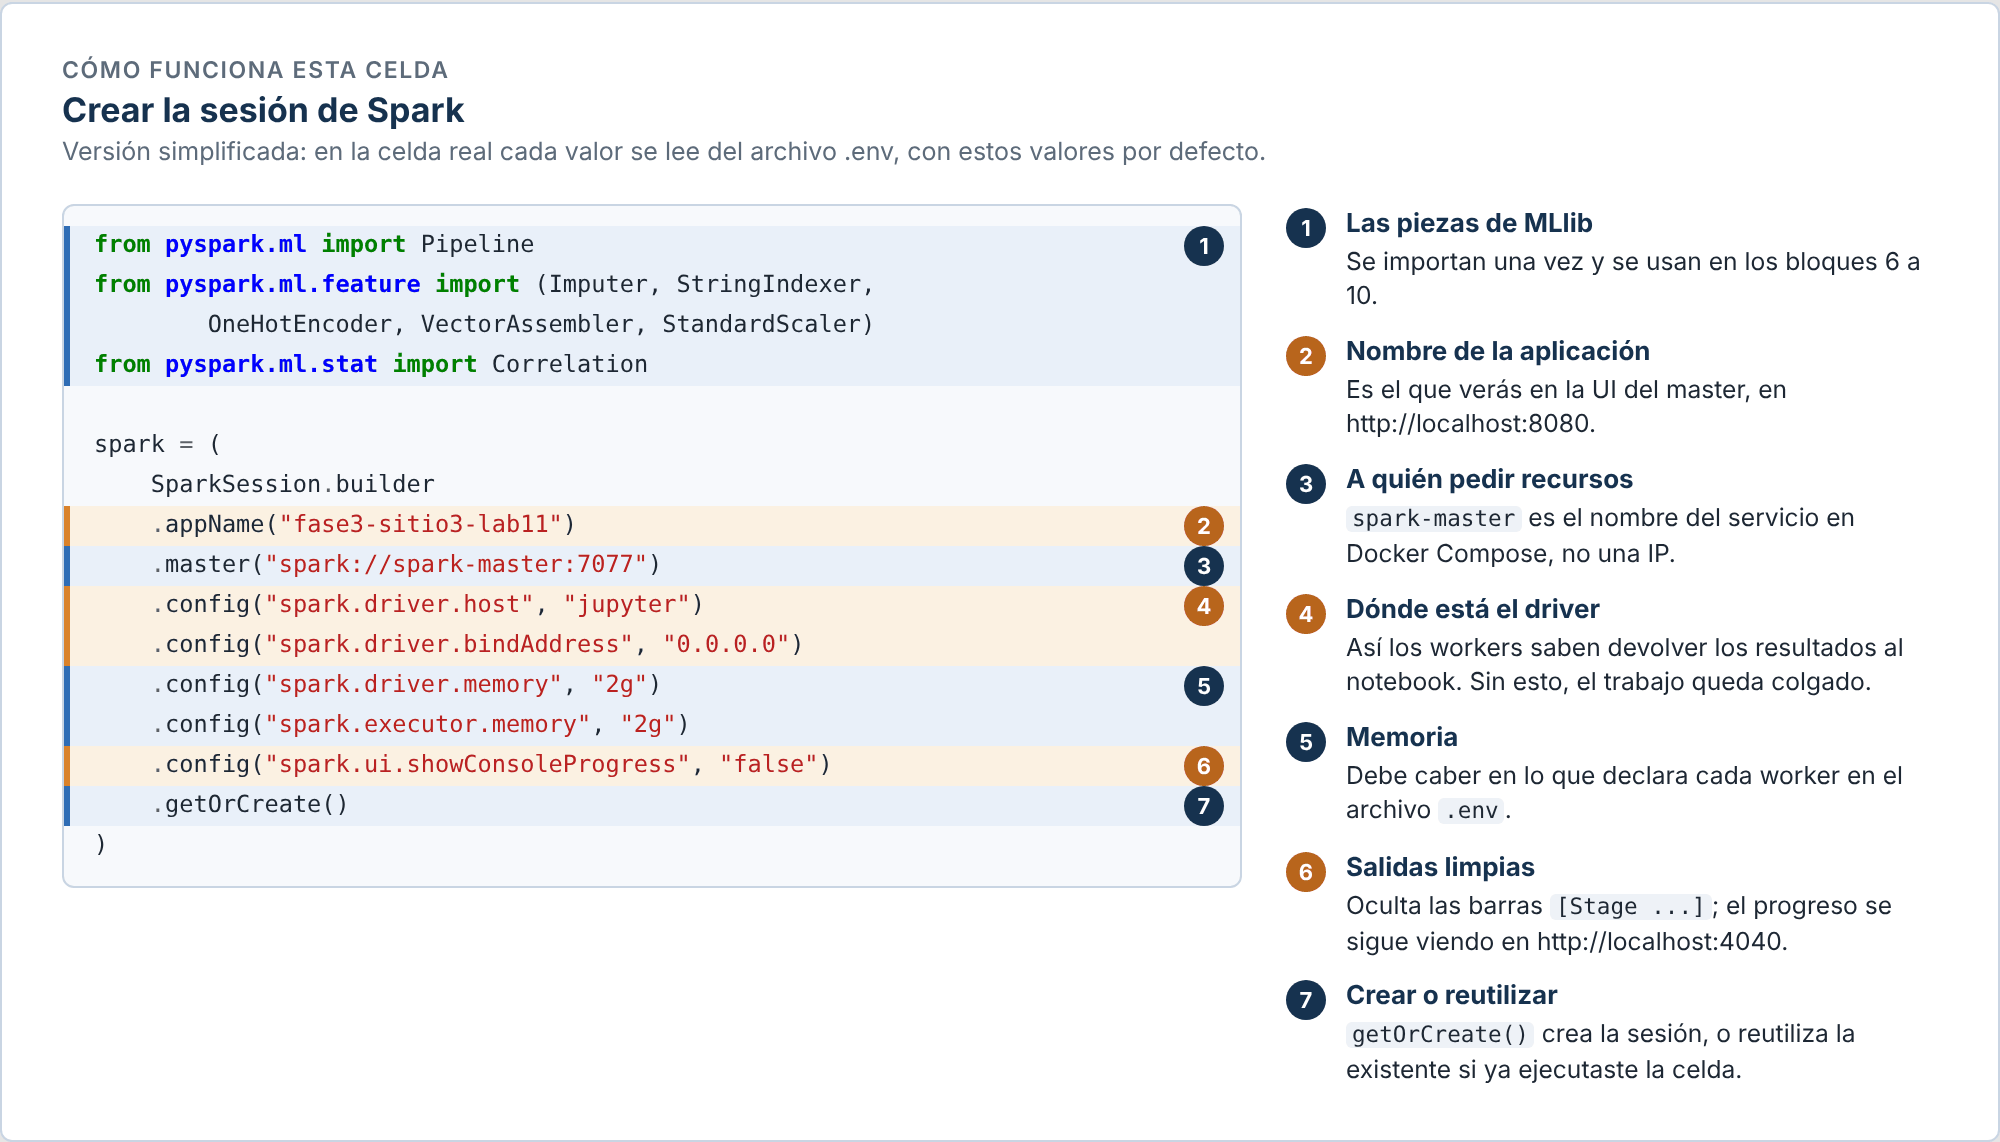

In [2]:
import os, time, math
from pyspark.sql import SparkSession, functions as F, Window

# --- MLlib: lo nuevo de esta fase ---
from pyspark.ml import Pipeline
from pyspark.ml.feature import (Imputer, StringIndexer, OneHotEncoder,
                                VectorAssembler, StandardScaler)
from pyspark.ml.stat import Correlation

spark = (
    SparkSession.builder
    .appName("fase3-sitio3-lab11")
    .master(os.environ.get("SPARK_MASTER_URL", "spark://spark-master:7077"))
    .config("spark.driver.host", os.environ.get("SPARK_DRIVER_HOST", "jupyter"))
    .config("spark.driver.bindAddress", "0.0.0.0")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "2g"))
    .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "2g"))
    .config("spark.ui.showConsoleProgress", "false")   # sin barras [Stage ...] en las salidas
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/24 20:56:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


#### Utilidades visuales

La siguiente celda solo define funciones para mostrar **tablas, indicadores y gráficos**.
No es contenido de MLlib, pero conviene saber qué hace cada función: el diagrama de abajo lo resume.

> Todas usan `.toPandas()` sobre resultados **pequeños**. Nunca hagas `.toPandas()` de la tabla
> completa: traería millones de filas a la memoria del driver.

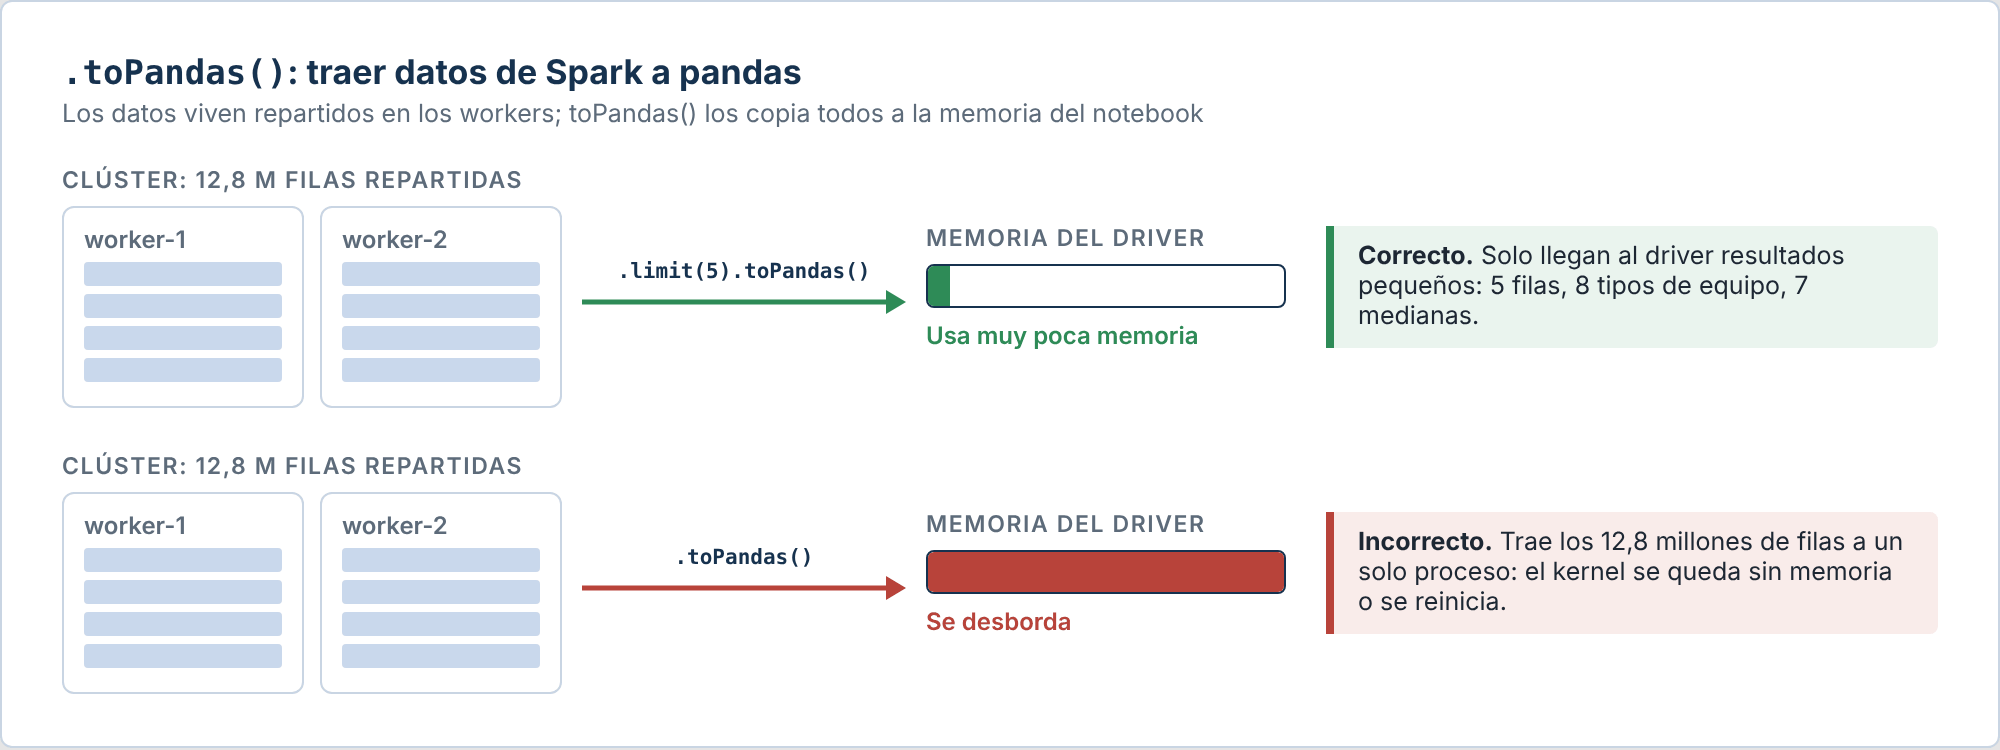

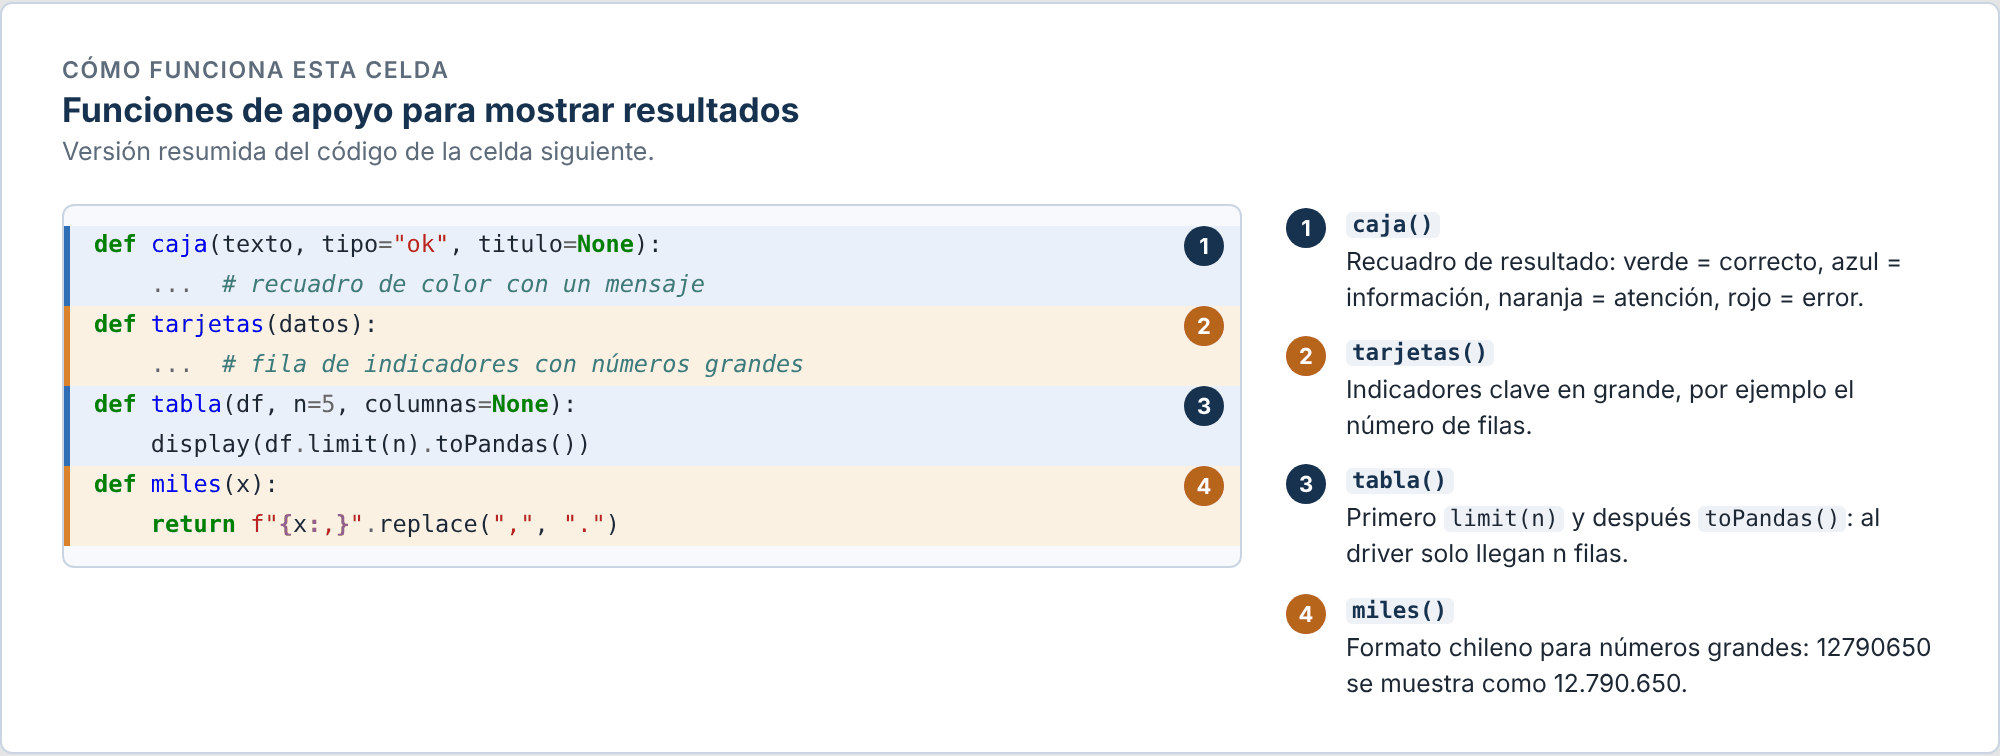

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
AZUL, NARANJA, VERDE, ROJO, GRIS = "#2f6db5", "#d9822b", "#2e8b57", "#b8433a", "#9aa9ba"

_COLORES = {"ok": ("#eaf4ee", "#2e8b57"), "info": ("#eaf1fa", "#2f6db5"),
            "warn": ("#fbf2e6", "#d9822b"), "error": ("#f9ecea", "#b8433a")}

def caja(texto, tipo="ok", titulo=None):
    """Recuadro de color con un mensaje."""
    fondo, borde = _COLORES[tipo]
    t = f'<div style="font-weight:700;margin-bottom:2px">{titulo}</div>' if titulo else ""
    display(HTML(f'<div style="background:{fondo};border-left:5px solid {borde};padding:8px 12px;'
                 f'margin:6px 0;border-radius:4px;color:#1d232b">{t}{texto}</div>'))

def tarjetas(datos):
    """Fila de tarjetas con números grandes: {'Etiqueta': valor}."""
    html = "".join(
        f'<div style="flex:1;min-width:120px;background:#f3f6fa;border:1px solid #d5dce6;border-radius:8px;'
        f'padding:10px;text-align:center"><div style="font-size:22px;font-weight:700;color:{AZUL}">{v}</div>'
        f'<div style="font-size:12px;color:#5b6470">{k}</div></div>' for k, v in datos.items())
    display(HTML(f'<div style="display:flex;gap:10px;flex-wrap:wrap;margin:6px 0">{html}</div>'))

def tabla(df, n=5, columnas=None):
    """Muestra las primeras n filas de un DataFrame de Spark como tabla de pandas."""
    if columnas:
        df = df.select(columnas)
    display(df.limit(n).toPandas())

def miles(x):
    return f"{x:,}".replace(",", ".")

print("Utilidades listas")
print(f"Conectado a {sc.master}  ·  Spark {spark.version}  ·  {sc.defaultParallelism} tareas en paralelo")
print("UI del job: http://localhost:4040   ·   UI del master: http://localhost:8080")

Utilidades listas
Conectado a spark://spark-master:7077  ·  Spark 4.0.1  ·  4 tareas en paralelo
UI del job: http://localhost:4040   ·   UI del master: http://localhost:8080


---
## Bloque 2 · Leer los datos de la Fase 2

> **Objetivo.** Cargar la **capa limpia** que escribiste al final de la Fase 2.

Recuerda cómo terminó la Fase 2: telemetría con tipos correctos, con la calidad del sensor marcada y
**etiquetada** con las fallas reales (gracias al *range join*). Esa tabla es nuestro punto de partida.

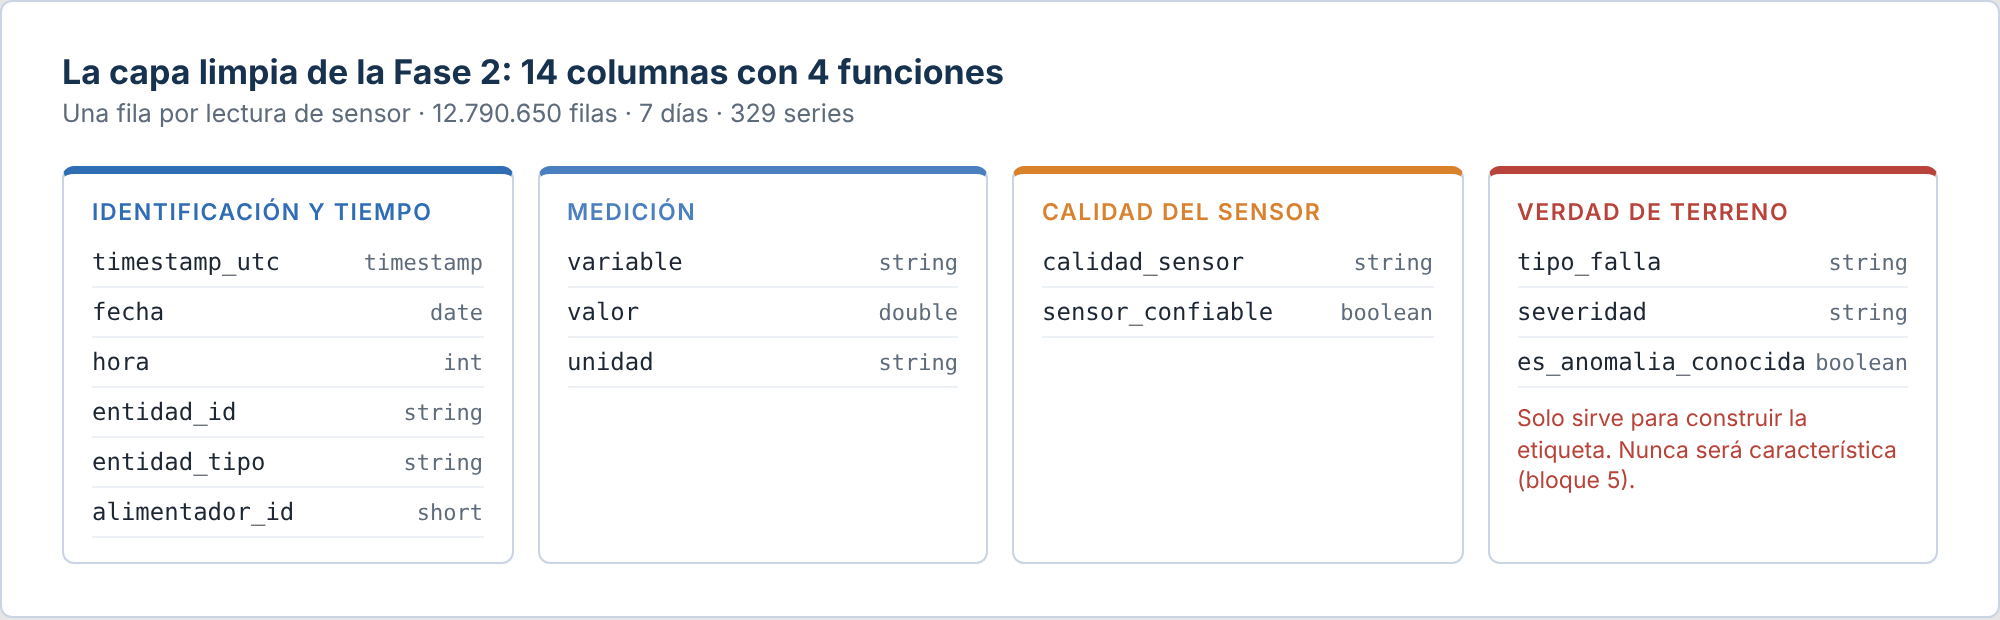

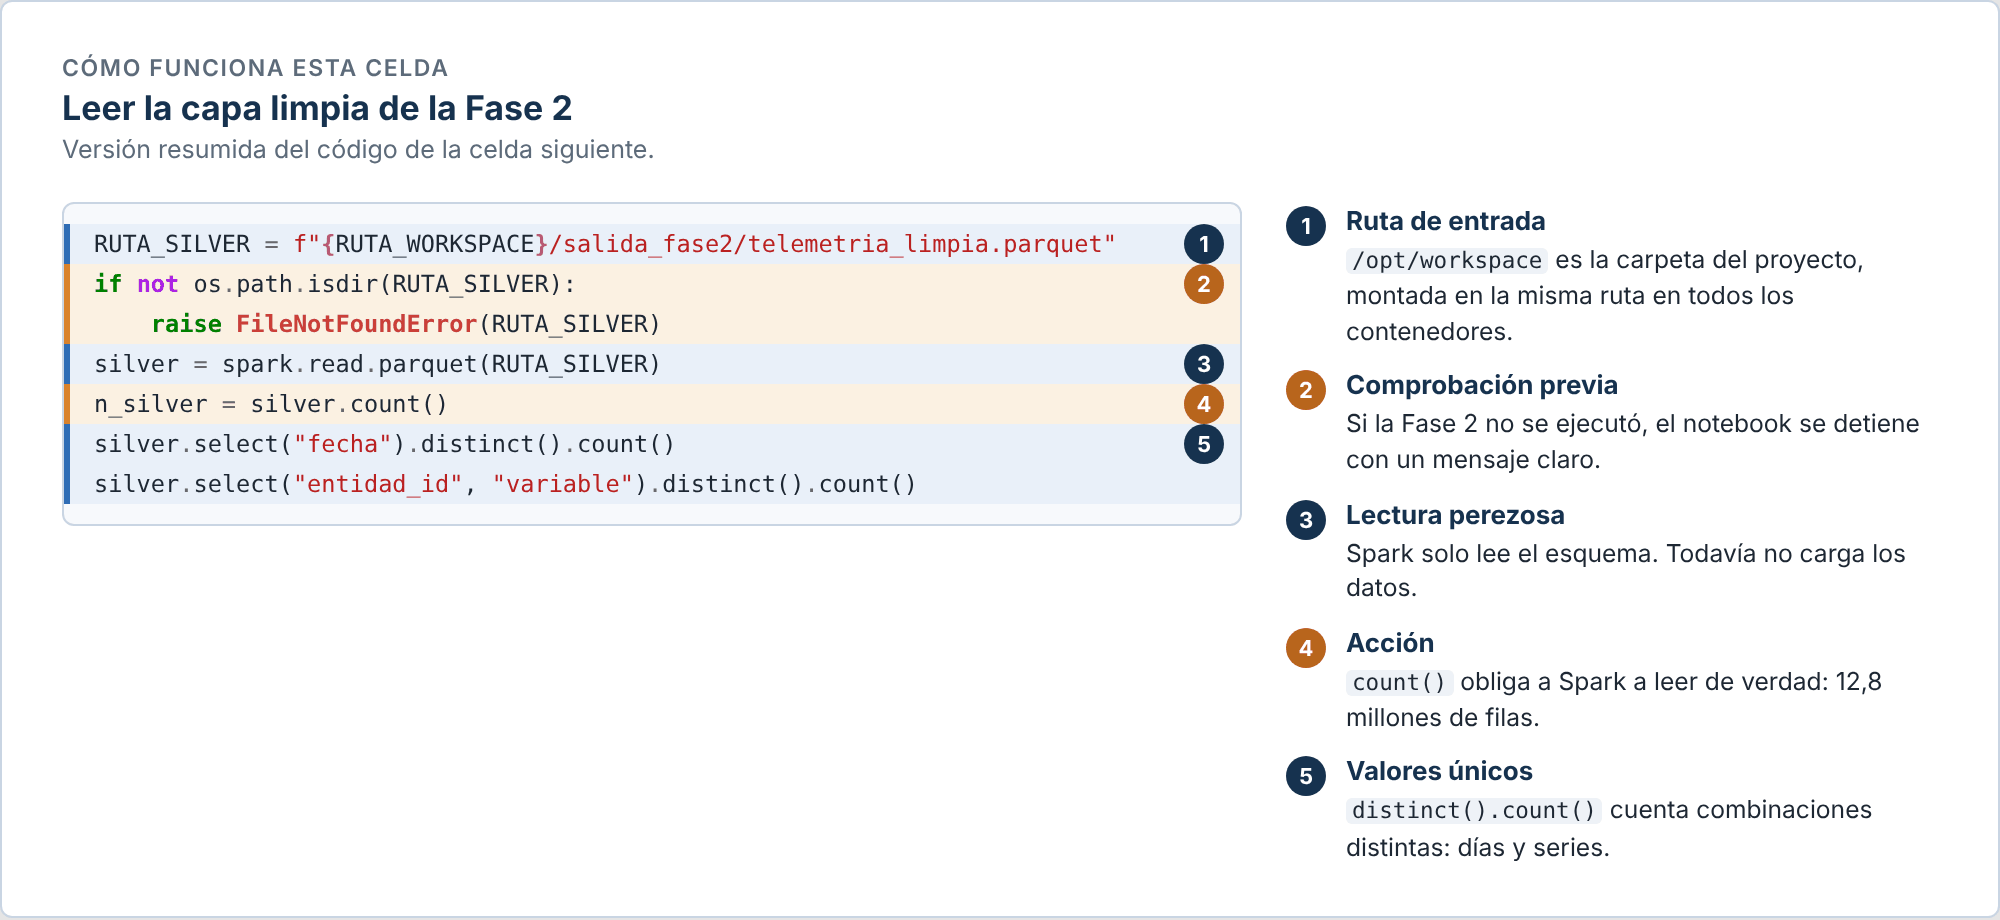

In [4]:
RUTA_WORKSPACE = "/opt/workspace"
RUTA_SILVER    = f"{RUTA_WORKSPACE}/salida_fase2/telemetria_limpia.parquet"
RUTA_SALIDA    = f"{RUTA_WORKSPACE}/salida_fase3"

if not os.path.isdir(RUTA_SILVER):
    caja(f"No existe <code>{RUTA_SILVER}</code>. Ejecuta completo el notebook de la Fase 2 "
         "(bloque 11) y vuelve aquí.", "error", "Falta la entrada")
    raise FileNotFoundError(RUTA_SILVER)

silver = spark.read.parquet(RUTA_SILVER)

n_silver = silver.count()
tarjetas({
    "lecturas": miles(n_silver),
    "días": silver.select("fecha").distinct().count(),
    "series (entidad × variable)": silver.select("entidad_id", "variable").distinct().count(),
    "tipos de entidad": silver.select("entidad_tipo").distinct().count(),
})
tabla(silver, 5, ["timestamp_utc", "entidad_id", "variable", "valor", "calidad_sensor", "en_falla"])

,timestamp_utc,entidad_id,variable,valor,calidad_sensor,en_falla
0,2026-01-13 00:00:31,faja_1,corriente_a,182.025981,ok,True
1,2026-01-13 00:00:00,reefer_1,potencia_kw,0.500000,ok,False
2,2026-01-13 00:00:51,faja_1,temperatura_polines_c,31.705914,ok,True
3,2026-01-13 00:00:00,reefer_71,temperatura_c,-17.900000,ok,False
4,2026-01-13 00:01:33,faja_1,corriente_a,184.668344,ok,True


> **Resultado esperado:** deberías ver aproximadamente **6,4 millones** de lecturas en esta corrida, **7 días** y **329 series**.

> **Concepto clave: esta tabla todavía no sirve para un modelo.** Está en **formato largo**: una fila por
> cada lectura. Una lectura sola (`corriente_a = 117`) no dice si hay una falla.

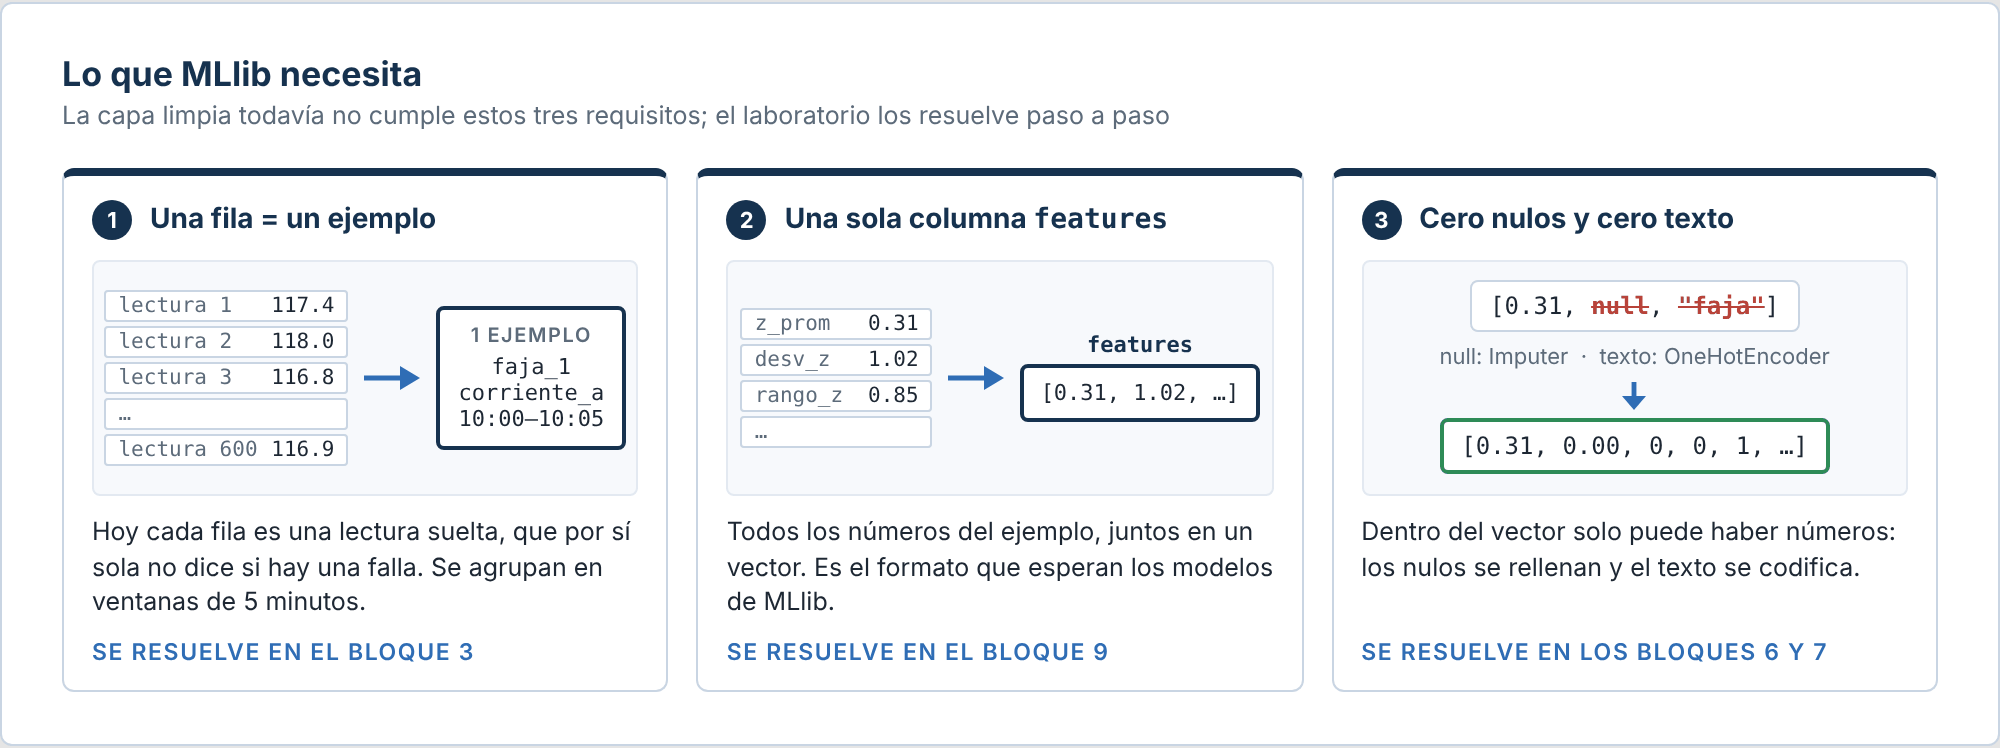

---
## Bloque 3 · ¿Qué es un ejemplo? Agrupar lecturas en ventanas

> **Objetivo.** Transformar millones de lecturas sueltas en **ejemplos** que tengan sentido.

> **Concepto clave (analogía del médico).** Un médico no diagnostica con *un* latido; mira el pulso
> durante un rato. Igual aquí: una falla se nota en el **comportamiento durante un intervalo**
> (el promedio sube, el sensor oscila más, deja de moverse...).

Nuestro ejemplo será: **un sensor (`entidad_id` + `variable`) durante una ventana de 5 minutos.**

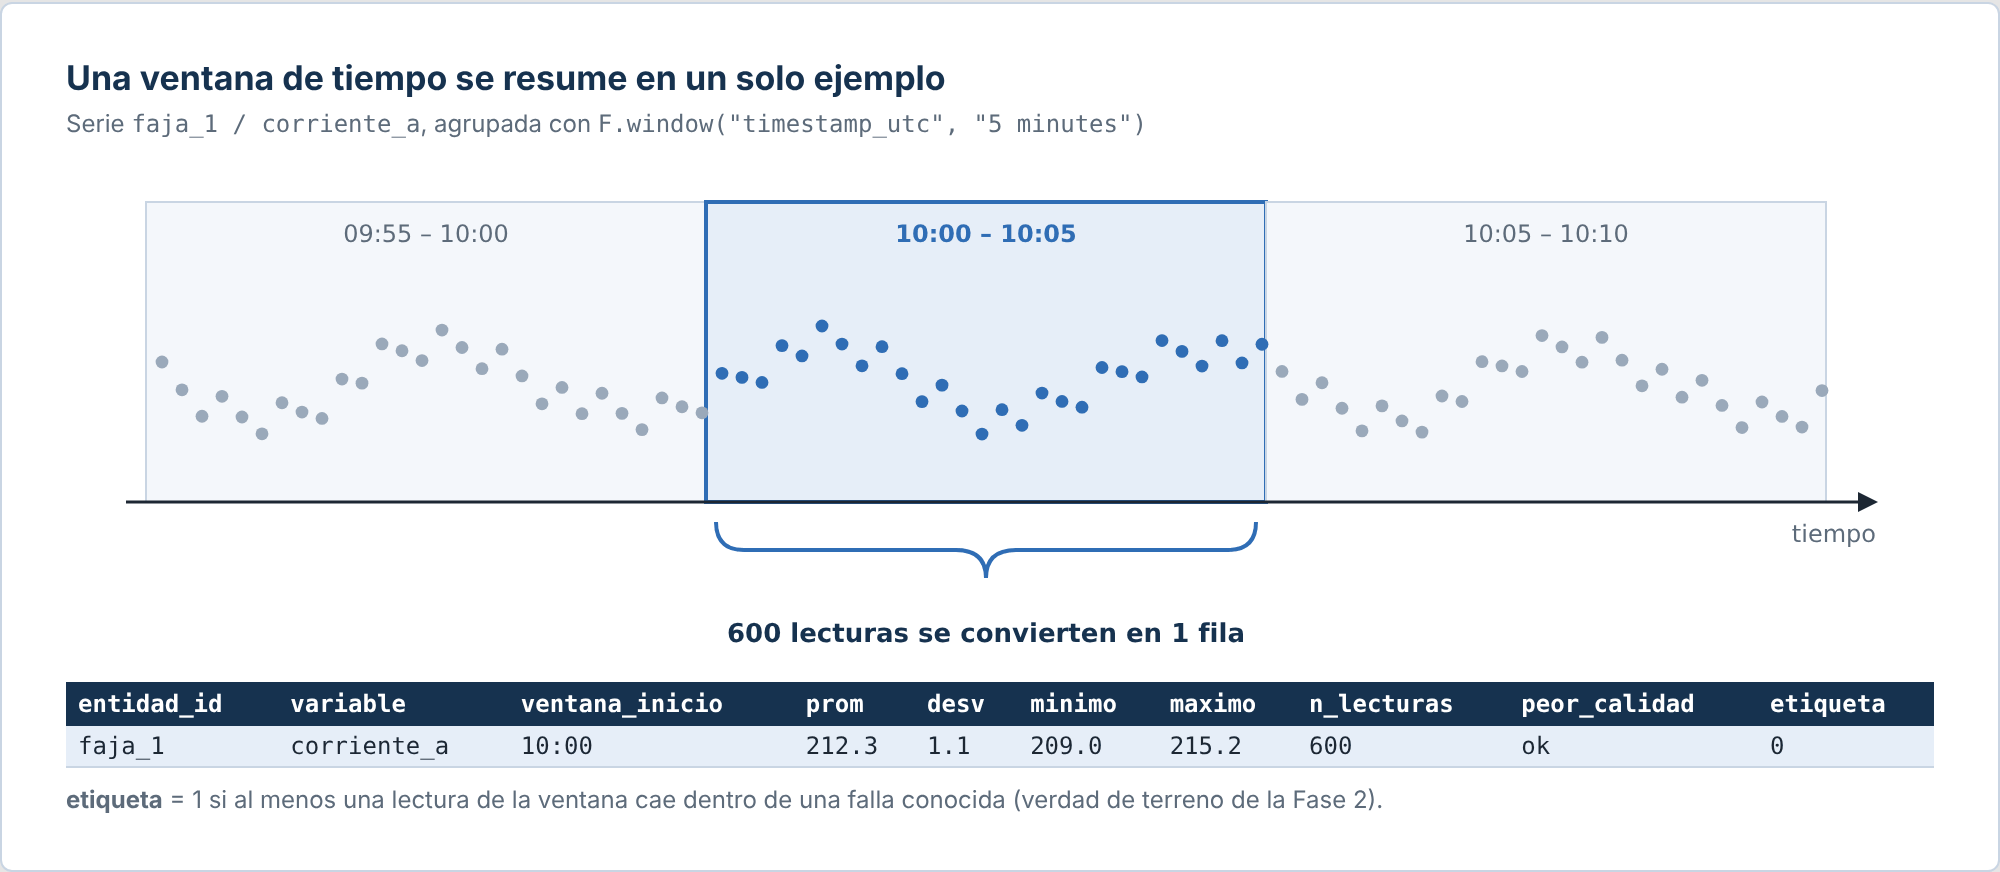

De cada ventana calculamos `prom` (promedio), `desv` (desviación), `minimo`, `maximo`, `n_lecturas`,
`frac_confiable`, la **peor** calidad del sensor y la **etiqueta**.

### 3.1 · La peor calidad y la etiqueta de cada ventana

Para resumir una ventana en **una** calidad y **una** etiqueta usamos un truco: si las categorías se
ordenan como números, el **máximo** entrega lo peor que pasó en la ventana.

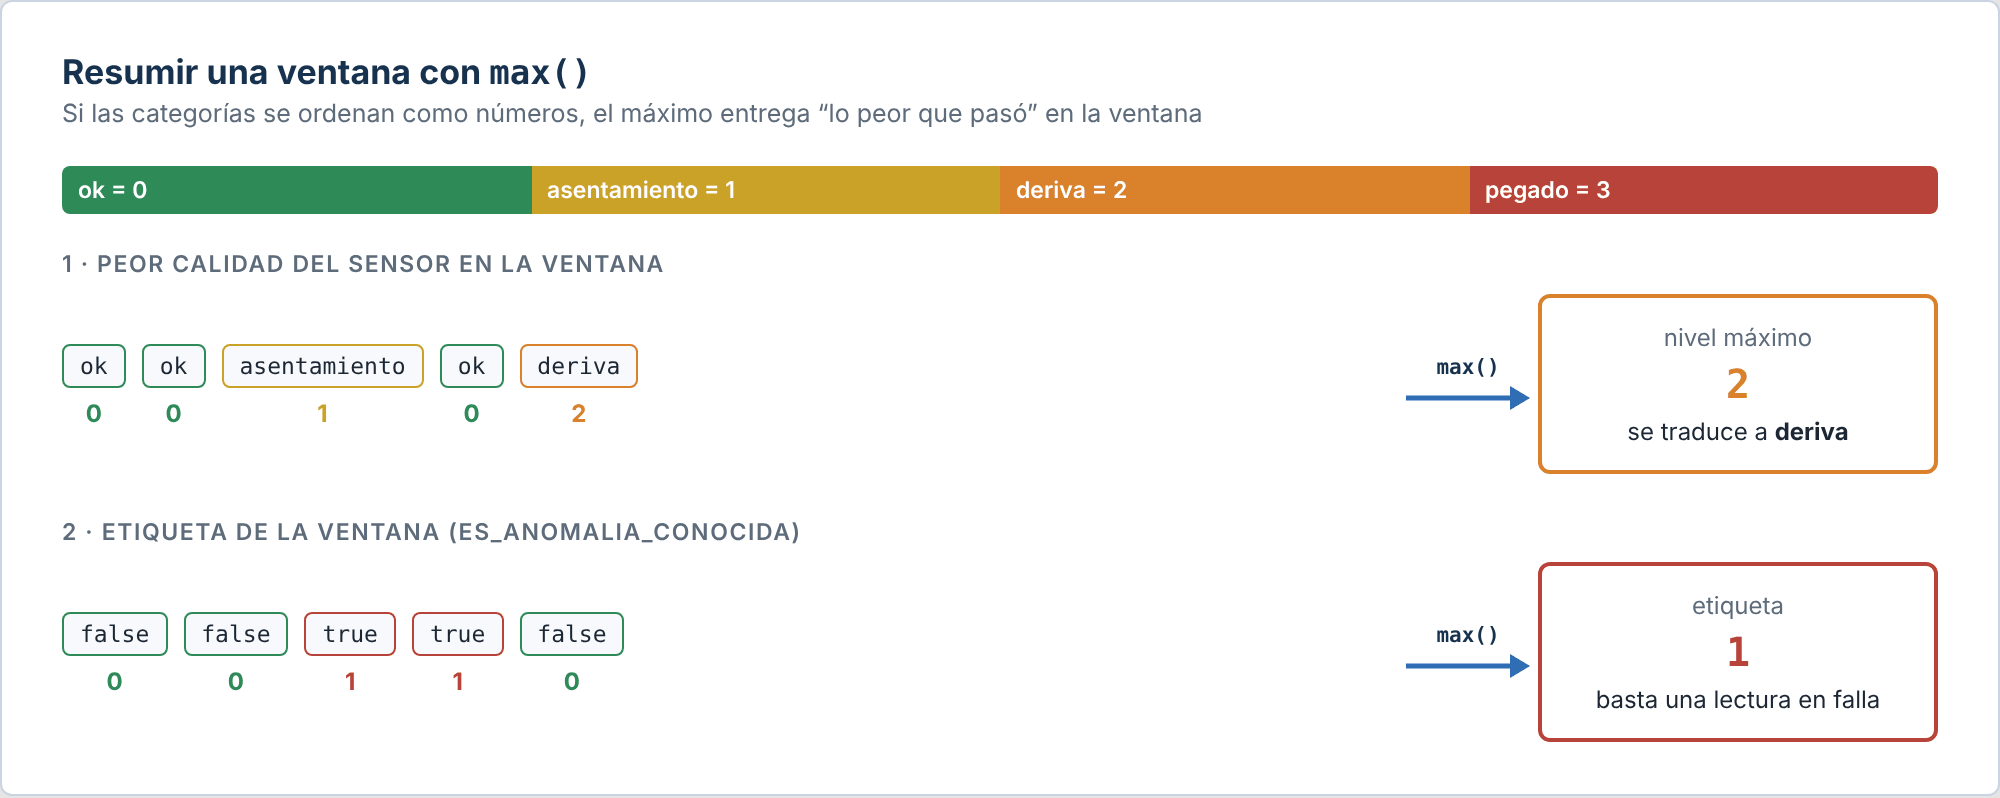

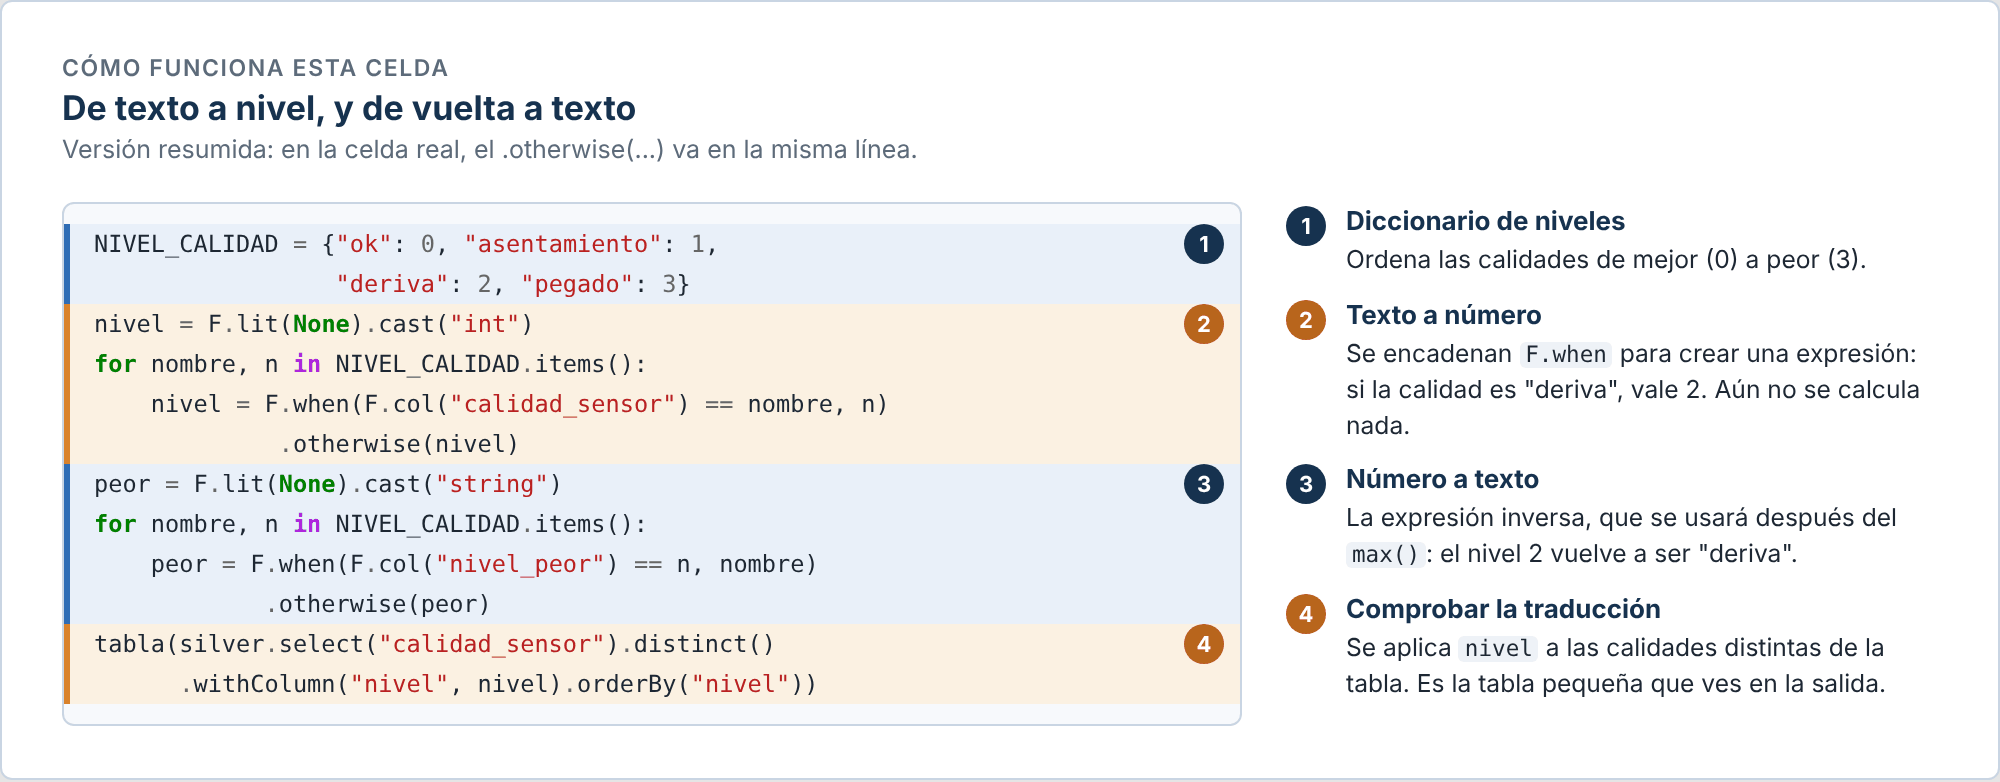

In [5]:
# La calidad es texto. Para quedarnos con la PEOR de la ventana la pasamos a número,
# tomamos el máximo y la volvemos a texto.
NIVEL_CALIDAD = {"ok": 0, "asentamiento": 1, "deriva": 2, "pegado": 3}

nivel = F.lit(None).cast("int")
for nombre, n in NIVEL_CALIDAD.items():
    nivel = F.when(F.col("calidad_sensor") == nombre, n).otherwise(nivel)

peor = F.lit(None).cast("string")
for nombre, n in NIVEL_CALIDAD.items():
    peor = F.when(F.col("nivel_peor") == n, nombre).otherwise(peor)

# Comprobación: cada calidad recibe su nivel
tabla(silver.select("calidad_sensor").distinct().withColumn("nivel", nivel).orderBy("nivel"), 10)

,calidad_sensor,nivel
0,ok,0
1,asentamiento,1
2,deriva,2
3,pegado,3


### 3.2 · Agrupar las lecturas en ventanas de 5 minutos

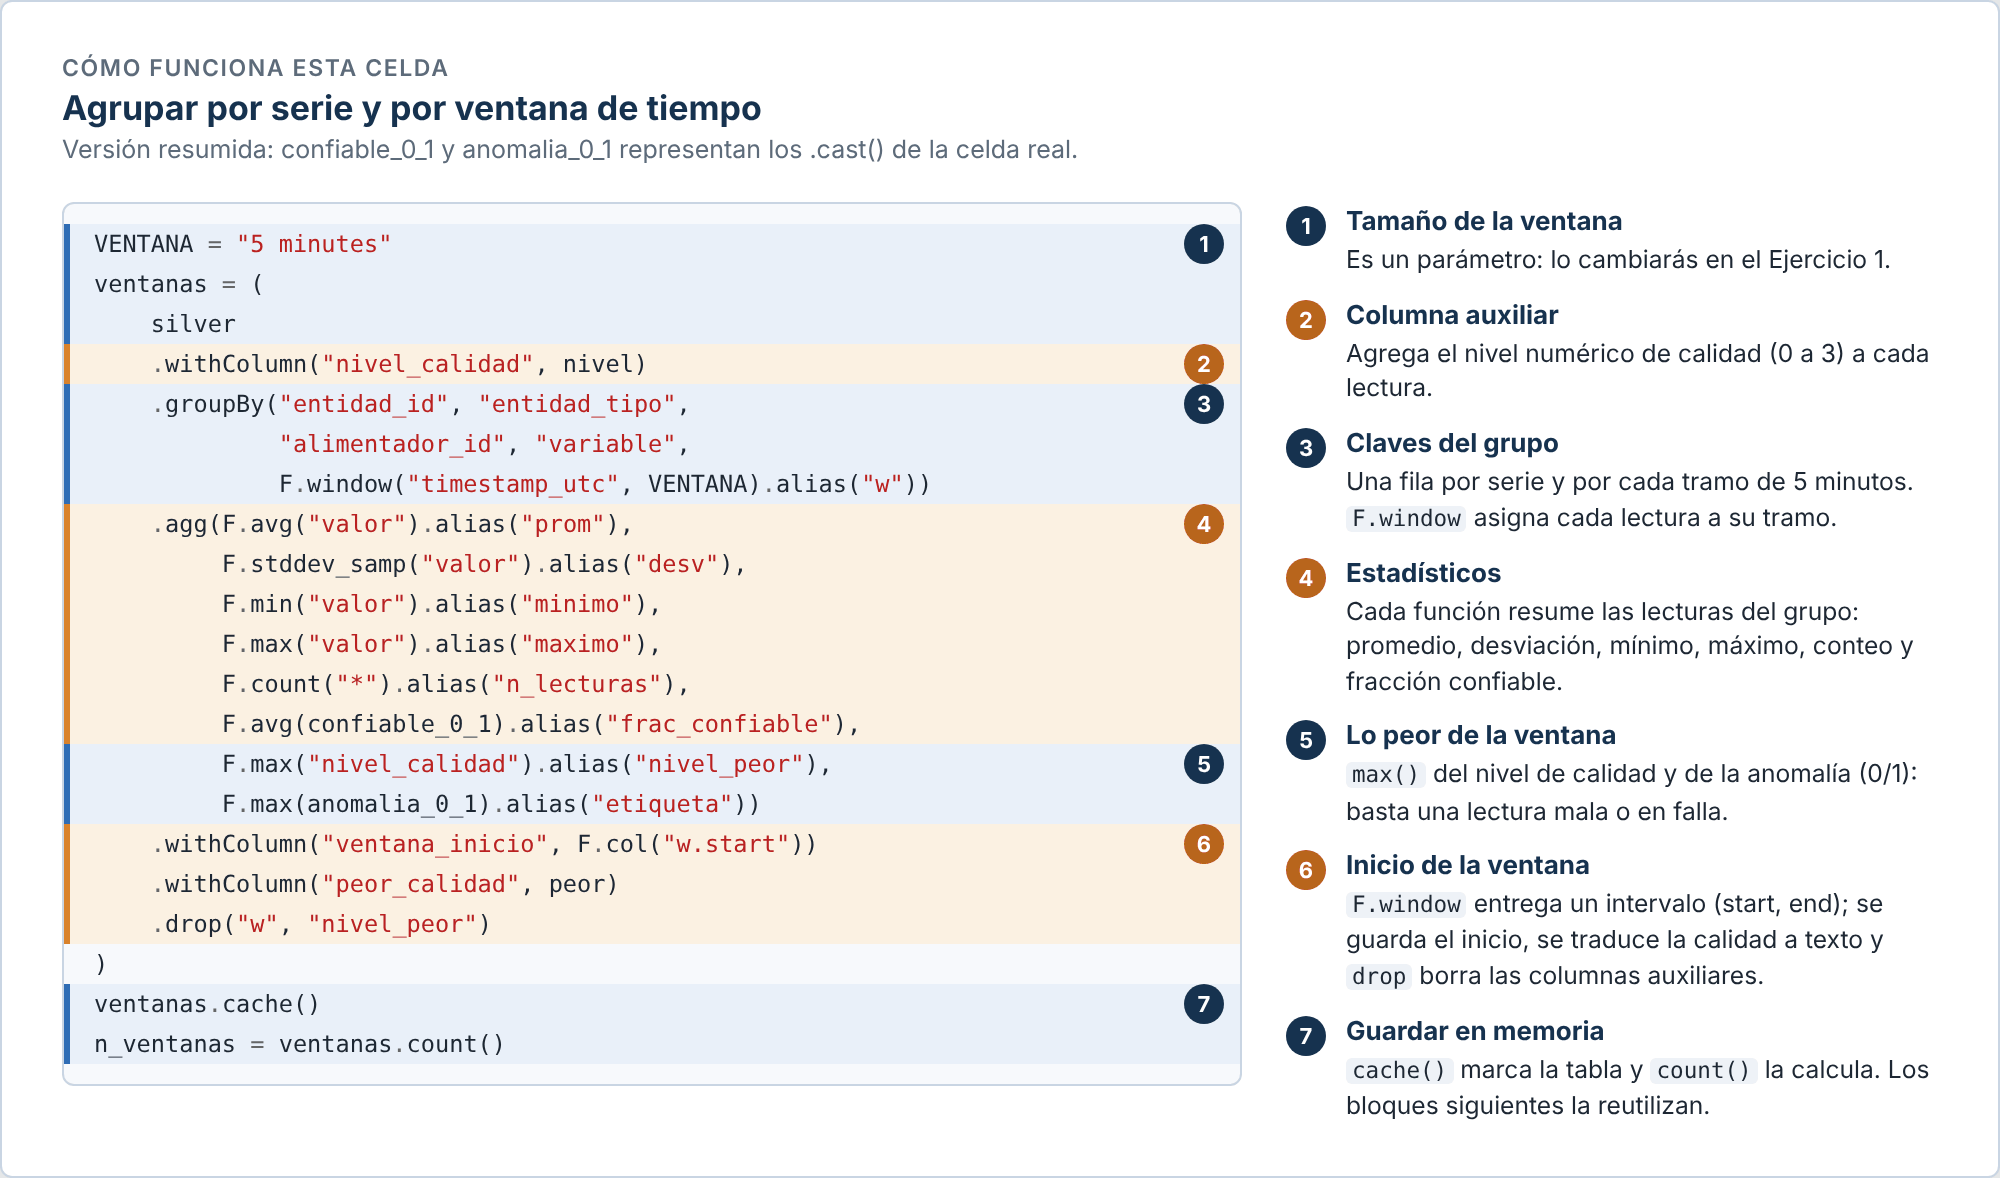

In [6]:
VENTANA = "5 minutes"   # Ejercicio 1: prueba "1 minute" y "15 minutes"

ventanas = (
    silver
    .withColumn("nivel_calidad", nivel)
    .groupBy("entidad_id", "entidad_tipo", "alimentador_id", "variable",
             F.window("timestamp_utc", VENTANA).alias("w"))           # la ventana de tiempo
    .agg(
        F.avg("valor").alias("prom"),
        F.stddev_samp("valor").alias("desv"),
        F.min("valor").alias("minimo"),
        F.max("valor").alias("maximo"),
        F.count("*").alias("n_lecturas"),
        F.avg(F.col("sensor_confiable").cast("double")).alias("frac_confiable"),
        F.max("nivel_calidad").alias("nivel_peor"),
        F.max(F.col("en_falla").cast("int")).alias("etiqueta"),   # la respuesta
    )
    .withColumn("ventana_inicio", F.col("w.start"))
    .withColumn("peor_calidad", peor)
    .drop("w", "nivel_peor")
)

ventanas.cache()                 # la usaremos muchas veces: la guardamos en memoria
n_ventanas = ventanas.count()

tarjetas({"lecturas (antes)": miles(n_silver),
          "ventanas = ejemplos (después)": miles(n_ventanas),
          "lecturas por ventana (promedio)": round(n_silver / n_ventanas)})
tabla(ventanas.orderBy("entidad_id", "variable", "ventana_inicio"), 5,
      ["entidad_id", "variable", "ventana_inicio", "prom", "desv", "minimo", "maximo",
       "n_lecturas", "peor_calidad", "etiqueta"])

,entidad_id,variable,ventana_inicio,prom,desv,minimo,maximo,n_lecturas,peor_calidad,etiqueta
0,alimentador_0,demanda_kw,2026-01-12 00:00:00,78.5,15.556349,56.5,89.5,5,ok,0
1,alimentador_0,demanda_kw,2026-01-12 00:05:00,21.3,8.341163,12.5,34.5,5,ok,0
2,alimentador_0,demanda_kw,2026-01-12 00:10:00,25.7,9.203260,18.0,40.0,5,ok,0
3,alimentador_0,demanda_kw,2026-01-12 00:15:00,43.3,3.012474,40.0,45.5,5,ok,0
4,alimentador_0,demanda_kw,2026-01-12 00:20:00,30.1,9.037422,18.0,40.0,5,ok,0


> **Resultado esperado:** unos **655 mil ejemplos**, muchos menos que las lecturas originales.

### 3.3 · ¿Cuántas lecturas tiene cada ventana?

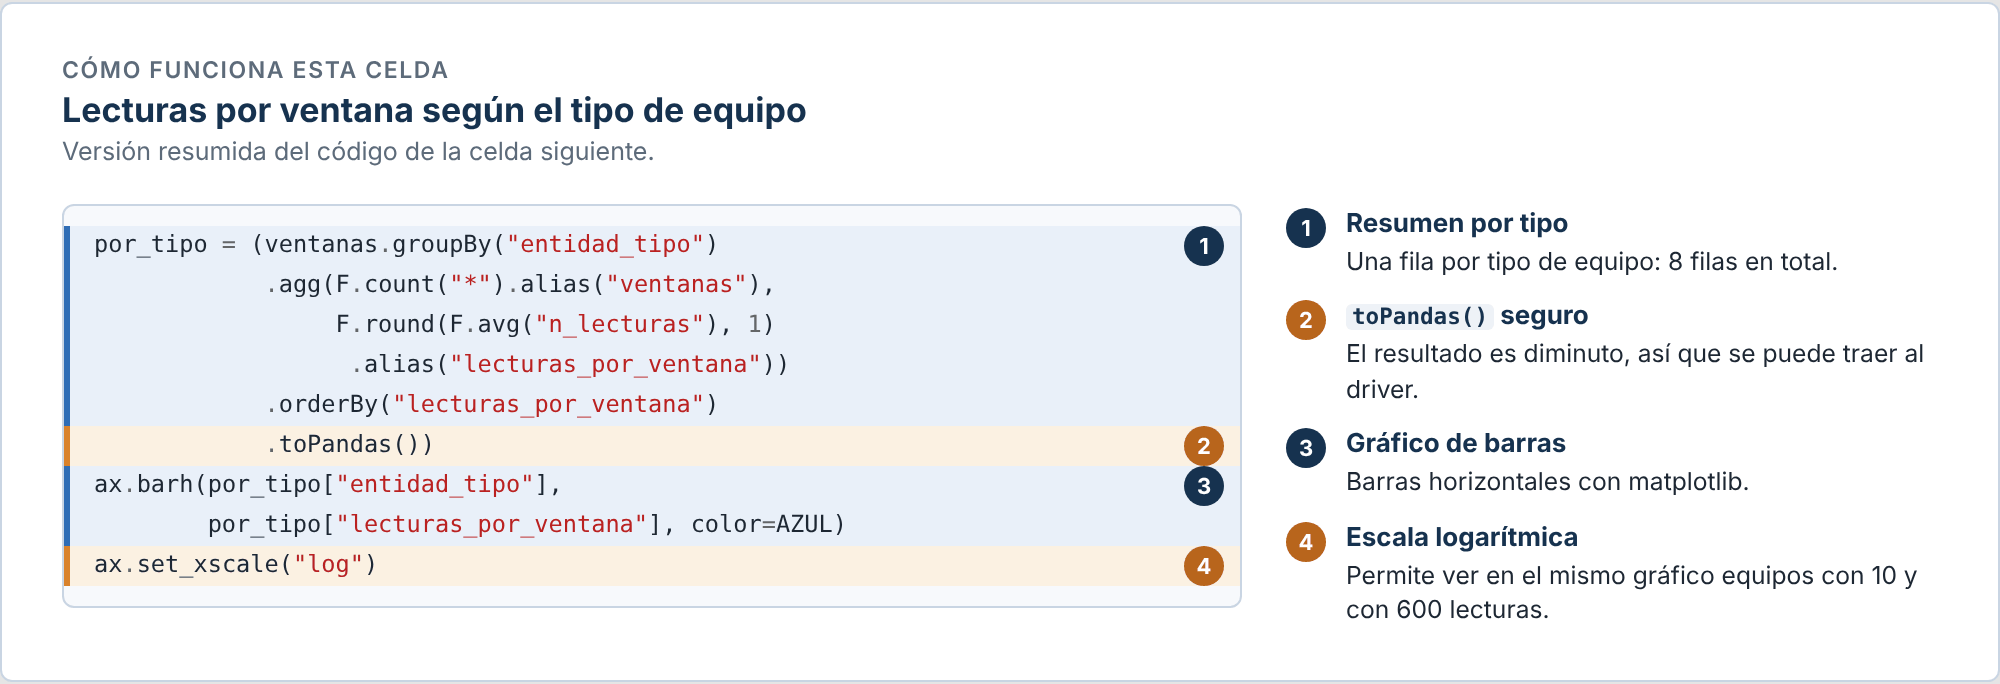

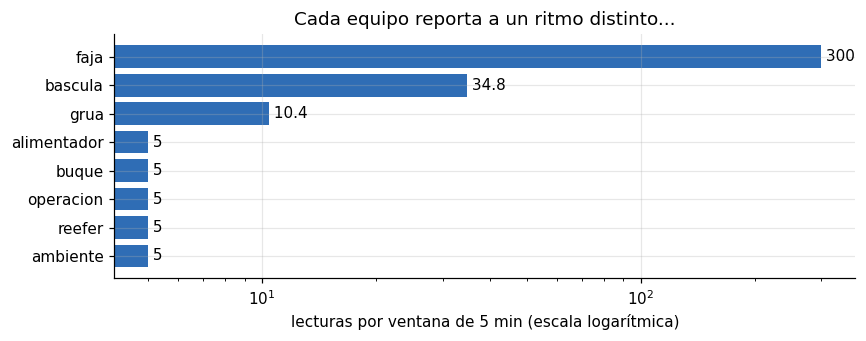

In [7]:
# ¿Cuántas lecturas caben en una ventana según el tipo de equipo?
por_tipo = (ventanas.groupBy("entidad_tipo")
            .agg(F.count("*").alias("ventanas"),
                 F.round(F.avg("n_lecturas"), 1).alias("lecturas_por_ventana"))
            .orderBy("lecturas_por_ventana").toPandas())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(por_tipo["entidad_tipo"], por_tipo["lecturas_por_ventana"], color=AZUL)
for y, v in enumerate(por_tipo["lecturas_por_ventana"]):
    ax.text(v, y, f" {v:g}", va="center")
ax.set_xscale("log")
ax.set_xlabel("lecturas por ventana de 5 min (escala logarítmica)")
ax.set_title("Cada equipo reporta a un ritmo distinto...")
plt.tight_layout(); plt.show()

caja("...pero ahora <b>cada ventana cuenta como UN ejemplo</b>, sin importar cuántas lecturas tenga. "
     "El sesgo de claves de la Fase 2 (la faja con casi la mitad de las filas) deja de dominar.", "info")

> **Resultado esperado:** la faja tiene un ritmo mayor por ventana que un reefer; los valores efectivos se muestran en el gráfico.

<details>
<summary><b>Pregunta de repaso:</b> ¿por qué usamos <code>.cache()</code> en <code>ventanas</code>? (clic para ver la respuesta)</summary>

El `groupBy` es una operación **ancha**: provoca un *shuffle* (mover datos por la red), que es lo más caro
de Spark, como viste en la Fase 2. Como todos los bloques siguientes parten de `ventanas`, la guardamos en
memoria para no repetir ese trabajo cada vez.

</details>

---
## Bloque 4 · Crear características nuevas

> **Objetivo.** Fabricar números que **delaten una falla** y que sean **comparables entre sensores**.

> **Concepto clave.** Un promedio de **380** es normal para un voltaje (`tension_v`), pero absurdo para
> una velocidad (`velocidad_ms`). Por eso comparamos cada ventana **con lo habitual de su propio sensor**.

Es como las notas: un **5,5** puede ser excelente en un ramo difícil y malo en uno fácil. Lo que
importa es **cuánto te alejas del promedio del curso**. Eso es un ***z-score***:

$$z = \frac{\text{valor} - \text{promedio habitual}}{\text{variación habitual}}$$

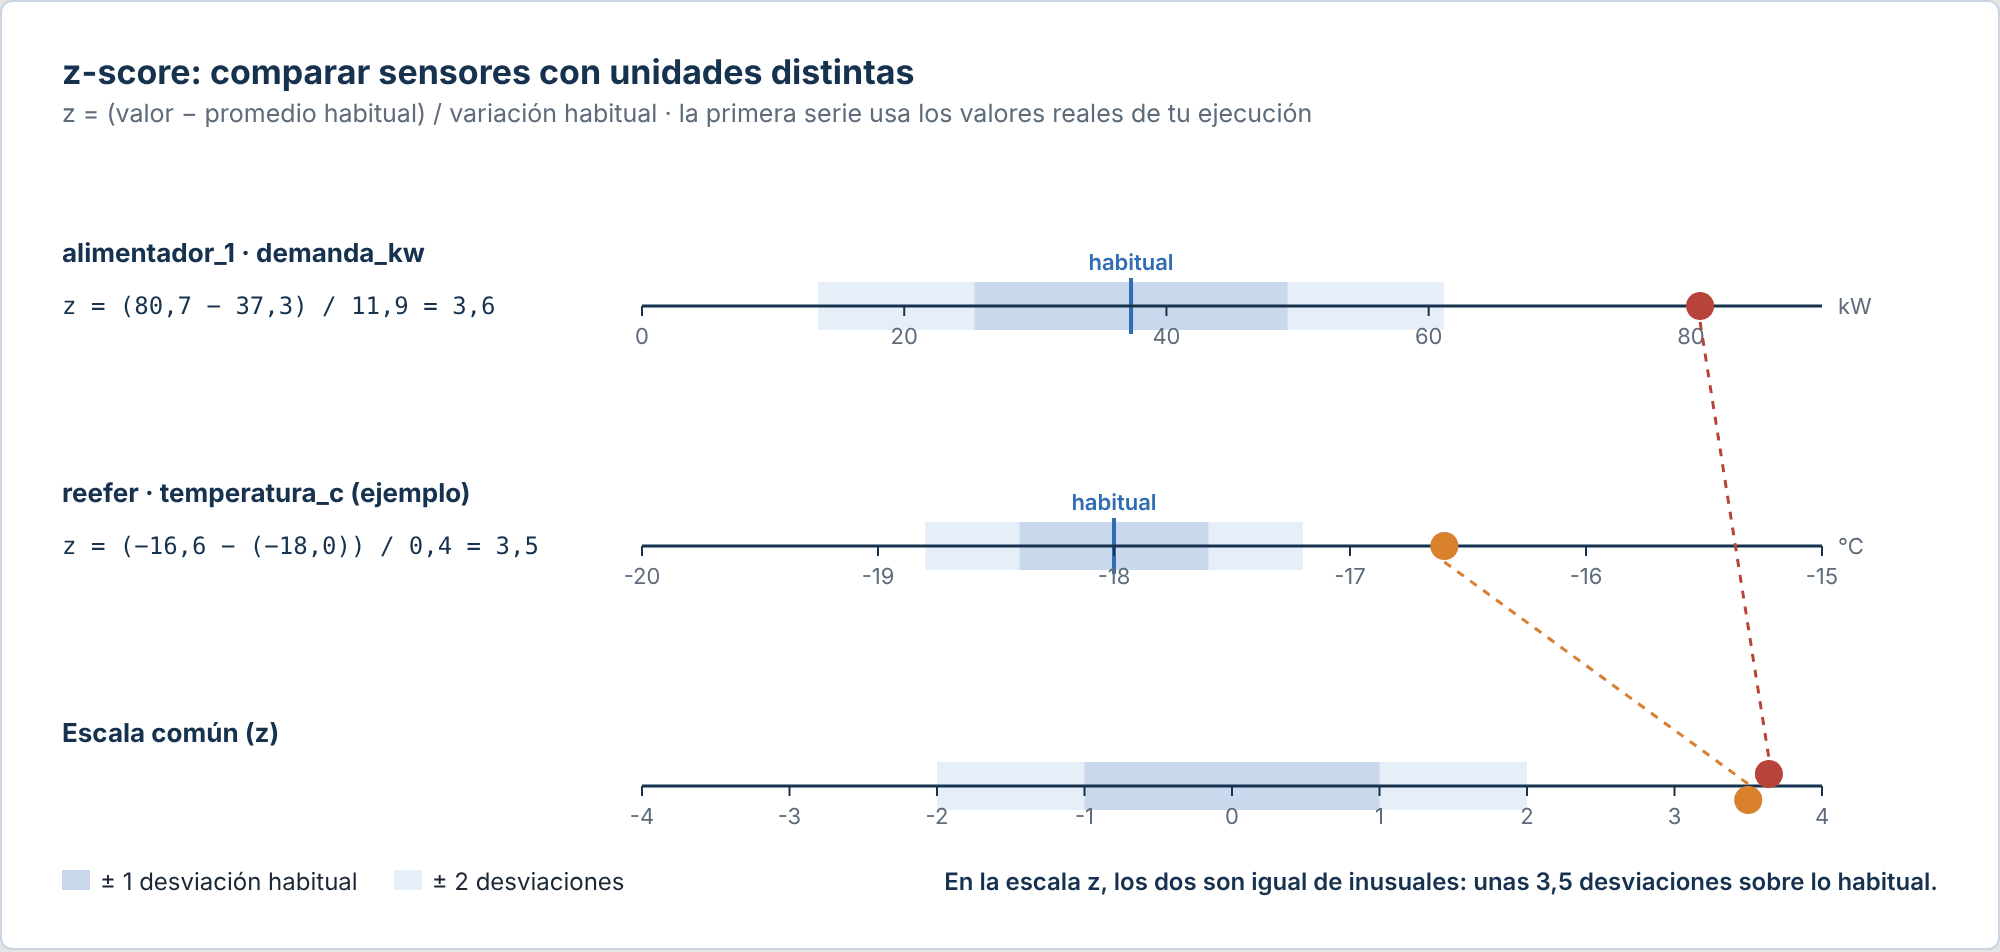

Con esa idea construimos cinco características. Cada una responde una pregunta distinta sobre la ventana:

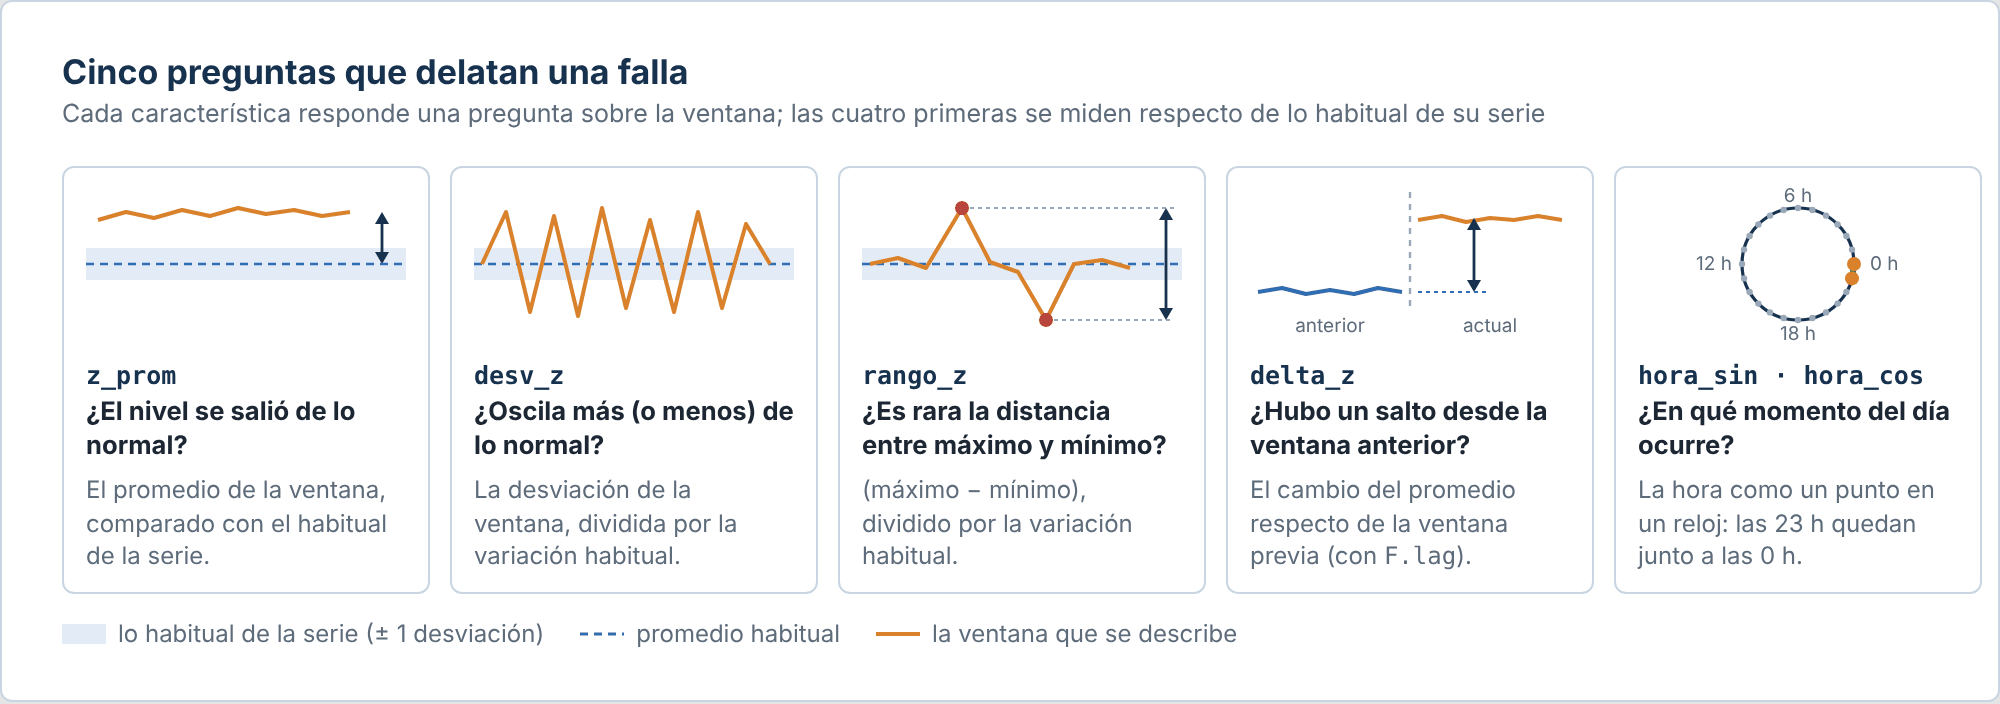

### 4.1 · La “línea base” de cada sensor

Primero calculamos el **promedio habitual** y la **variación habitual** de cada serie (solo con lecturas
confiables). Es una tabla **pequeña** (una fila por serie), así que la unimos con un **broadcast join**,
como en la Fase 2, y **verificamos** que el join no cambie el número de filas.

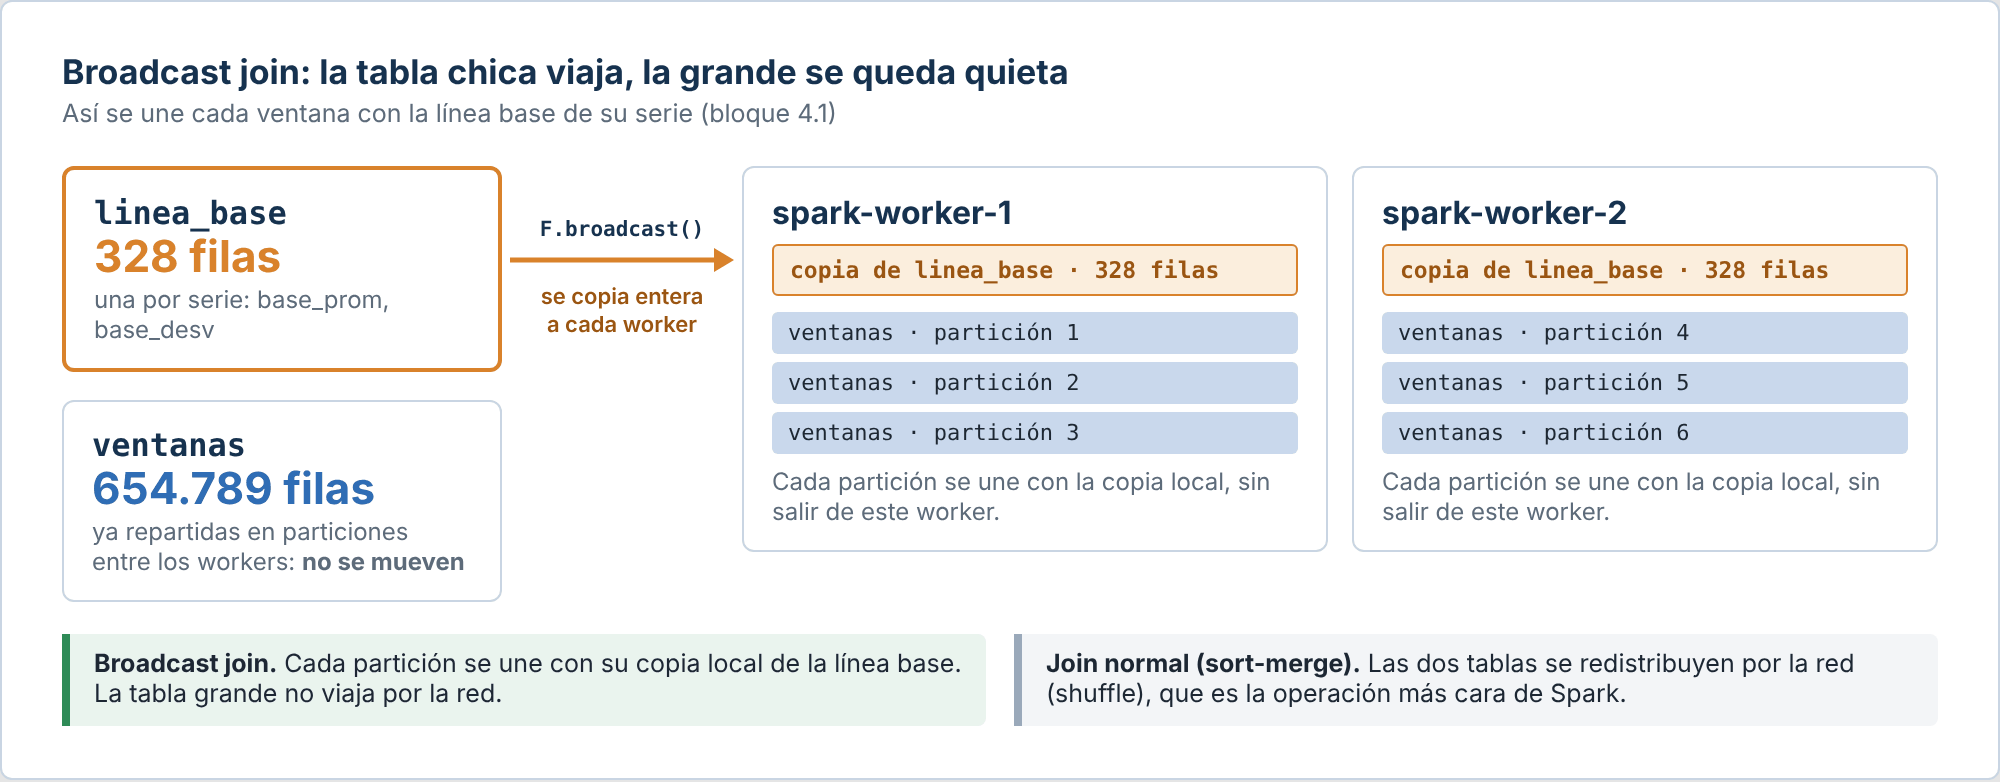

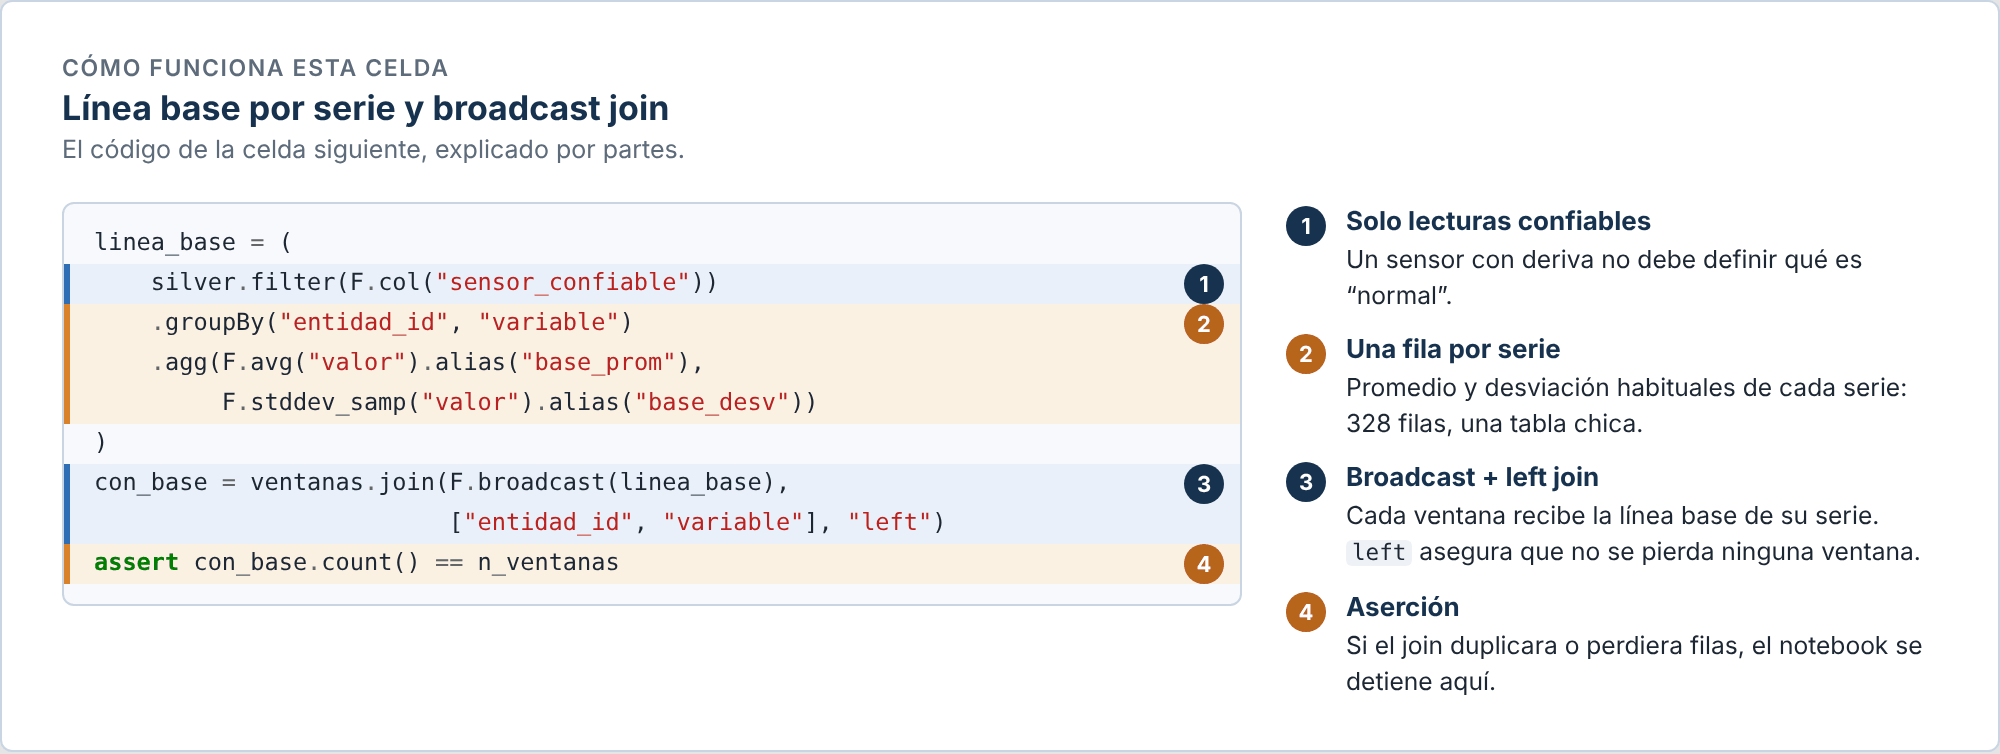

In [8]:
linea_base = (
    silver.filter(F.col("sensor_confiable"))
    .groupBy("entidad_id", "variable")
    .agg(F.avg("valor").alias("base_prom"),
         F.stddev_samp("valor").alias("base_desv"))
)

con_base = ventanas.join(F.broadcast(linea_base), ["entidad_id", "variable"], "left")

# La lección de la Fase 2: un join NUNCA debe cambiar el número de filas
assert con_base.count() == n_ventanas, "¡El join alteró el número de filas!"
caja(f"Línea base de <b>{linea_base.count()}</b> series unida con broadcast. "
     f"Conteo intacto: <b>{miles(n_ventanas)}</b> ventanas.")

### 4.2 · Calcular las características

> **Atención: Spark 4 no perdona dividir por cero.** Spark 4.0 trae el **modo ANSI** activado: dividir
> por cero **lanza un error**. Un sensor que nunca cambia (por ejemplo, uno que siempre marca `0`) tiene
> variación habitual = 0. Por eso usamos `dividir_seguro()`: si el denominador es 0, deja un **nulo** a
> propósito, que trataremos en el bloque 6.

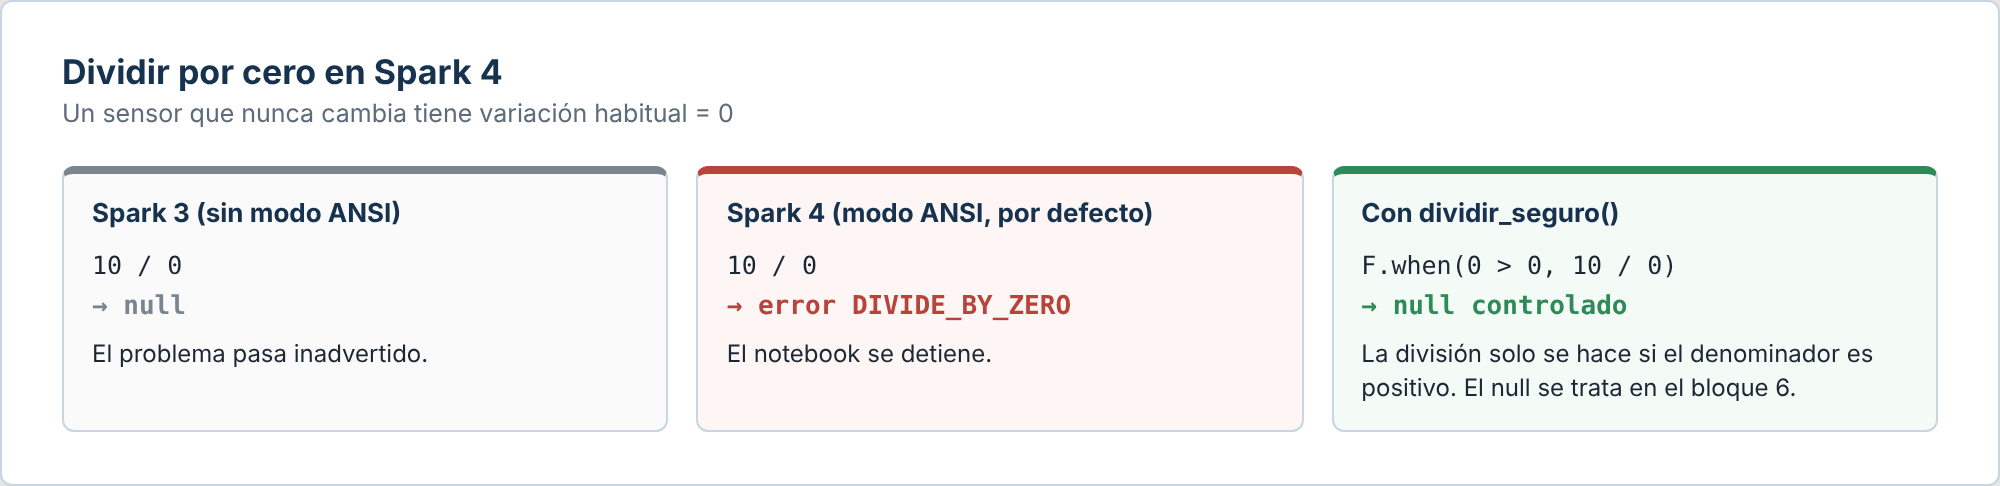

Para `delta_z` necesitamos el promedio de la **ventana anterior** del mismo sensor. Eso lo entrega
`F.lag()` sobre una `Window` que separa cada serie y la ordena en el tiempo:

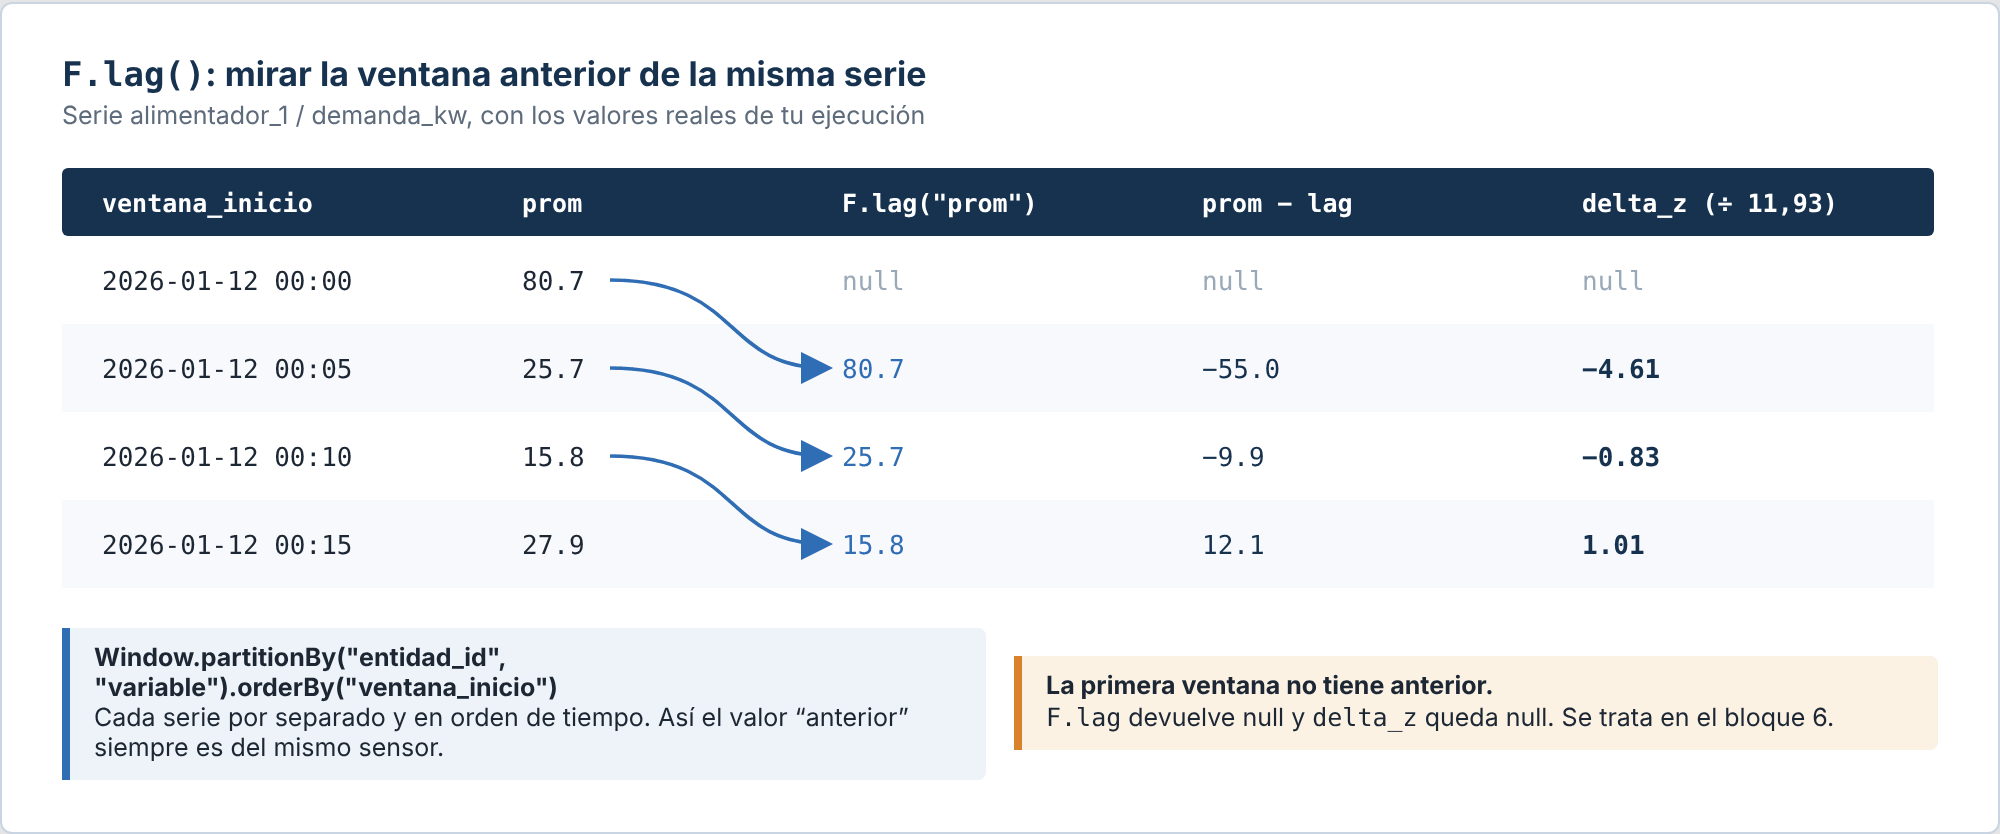

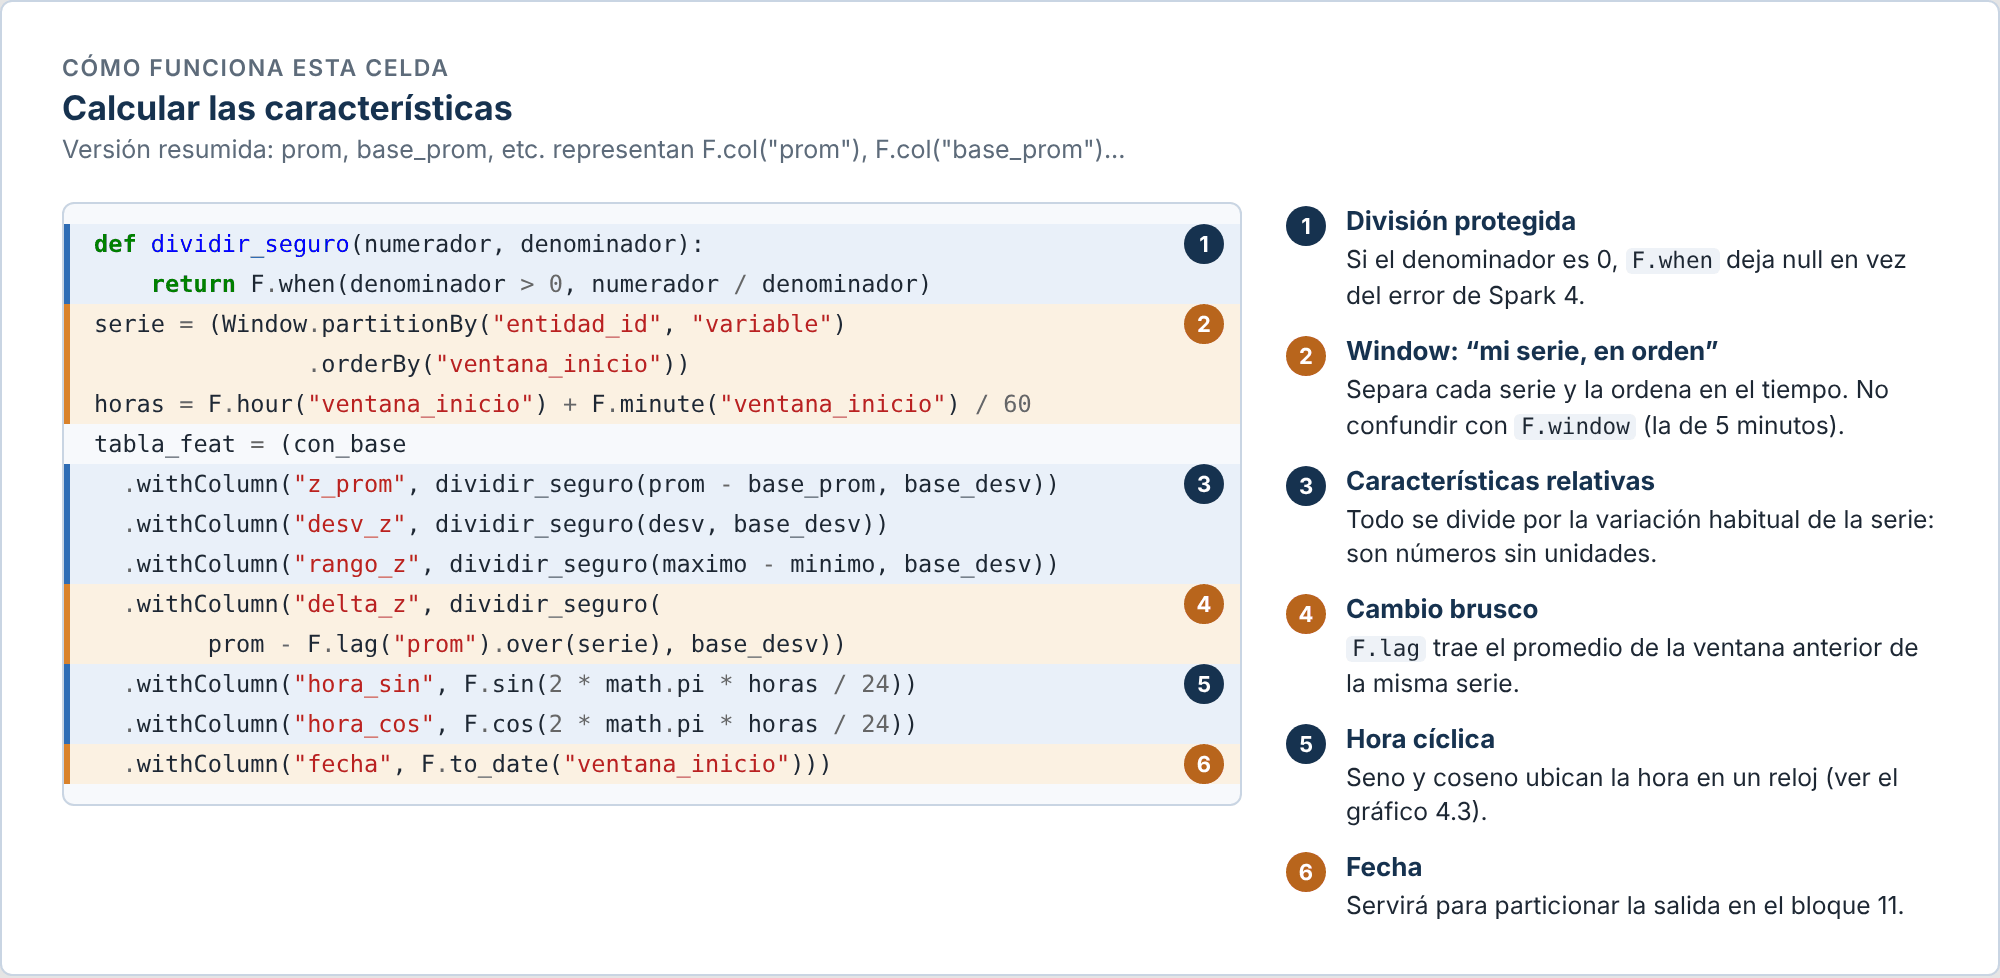

In [9]:
def dividir_seguro(numerador, denominador):
    """numerador / denominador, o null si el denominador es 0 o nulo."""
    return F.when(denominador > 0, numerador / denominador)

serie = Window.partitionBy("entidad_id", "variable").orderBy("ventana_inicio")   # "mi sensor, en orden"
horas = F.hour("ventana_inicio") + F.minute("ventana_inicio") / 60.0

tabla_feat = (
    con_base
    .withColumn("z_prom",  dividir_seguro(F.col("prom") - F.col("base_prom"), F.col("base_desv")))
    .withColumn("desv_z",  dividir_seguro(F.col("desv"), F.col("base_desv")))
    .withColumn("rango_z", dividir_seguro(F.col("maximo") - F.col("minimo"), F.col("base_desv")))
    .withColumn("delta_z", dividir_seguro(F.col("prom") - F.lag("prom").over(serie),   # ventana anterior
                                          F.col("base_desv")))
    .withColumn("hora_sin", F.sin(2 * math.pi * horas / 24))
    .withColumn("hora_cos", F.cos(2 * math.pi * horas / 24))
    .withColumn("fecha", F.to_date("ventana_inicio"))
)

print(f"Modo ANSI activo: {spark.conf.get('spark.sql.ansi.enabled')}")
tabla(tabla_feat.orderBy("entidad_id", "variable", "ventana_inicio"), 5,
      ["entidad_id", "variable", "ventana_inicio", "prom", "z_prom", "desv_z", "rango_z", "delta_z"])
caja("Fíjate en la <b>primera</b> fila: <code>delta_z</code> sale vacío (NaN/None) porque no hay "
     "ventana anterior con la cual comparar. Lo resolveremos en el bloque 6.", "info")

Modo ANSI activo: true


,entidad_id,variable,ventana_inicio,prom,z_prom,desv_z,rango_z,delta_z
0,alimentador_0,demanda_kw,2026-01-12 00:00:00,78.5,3.272620,1.254139,2.660430,NaN
1,alimentador_0,demanda_kw,2026-01-12 00:05:00,21.3,-1.338793,0.672457,1.773620,-4.611413
2,alimentador_0,demanda_kw,2026-01-12 00:10:00,25.7,-0.984069,0.741959,1.773620,0.354724
3,alimentador_0,demanda_kw,2026-01-12 00:15:00,43.3,0.434827,0.242863,0.443405,1.418896
4,alimentador_0,demanda_kw,2026-01-12 00:20:00,30.1,-0.629345,0.728589,1.773620,-1.064172


### 4.3 · ¿Por qué la hora como seno y coseno?

Si le damos la hora como número (0 a 23), el modelo cree que las **23:00** y las **00:00** están lo más
lejos posible (¡23 unidades!), cuando en realidad están separadas por **una hora**.

La solución es poner las horas **en un reloj**: cada hora se convierte en un punto de un círculo,
con coordenadas (`hora_cos`, `hora_sin`). La celda siguiente no usa Spark: solo dibuja las 24 horas de
las dos formas para compararlas.

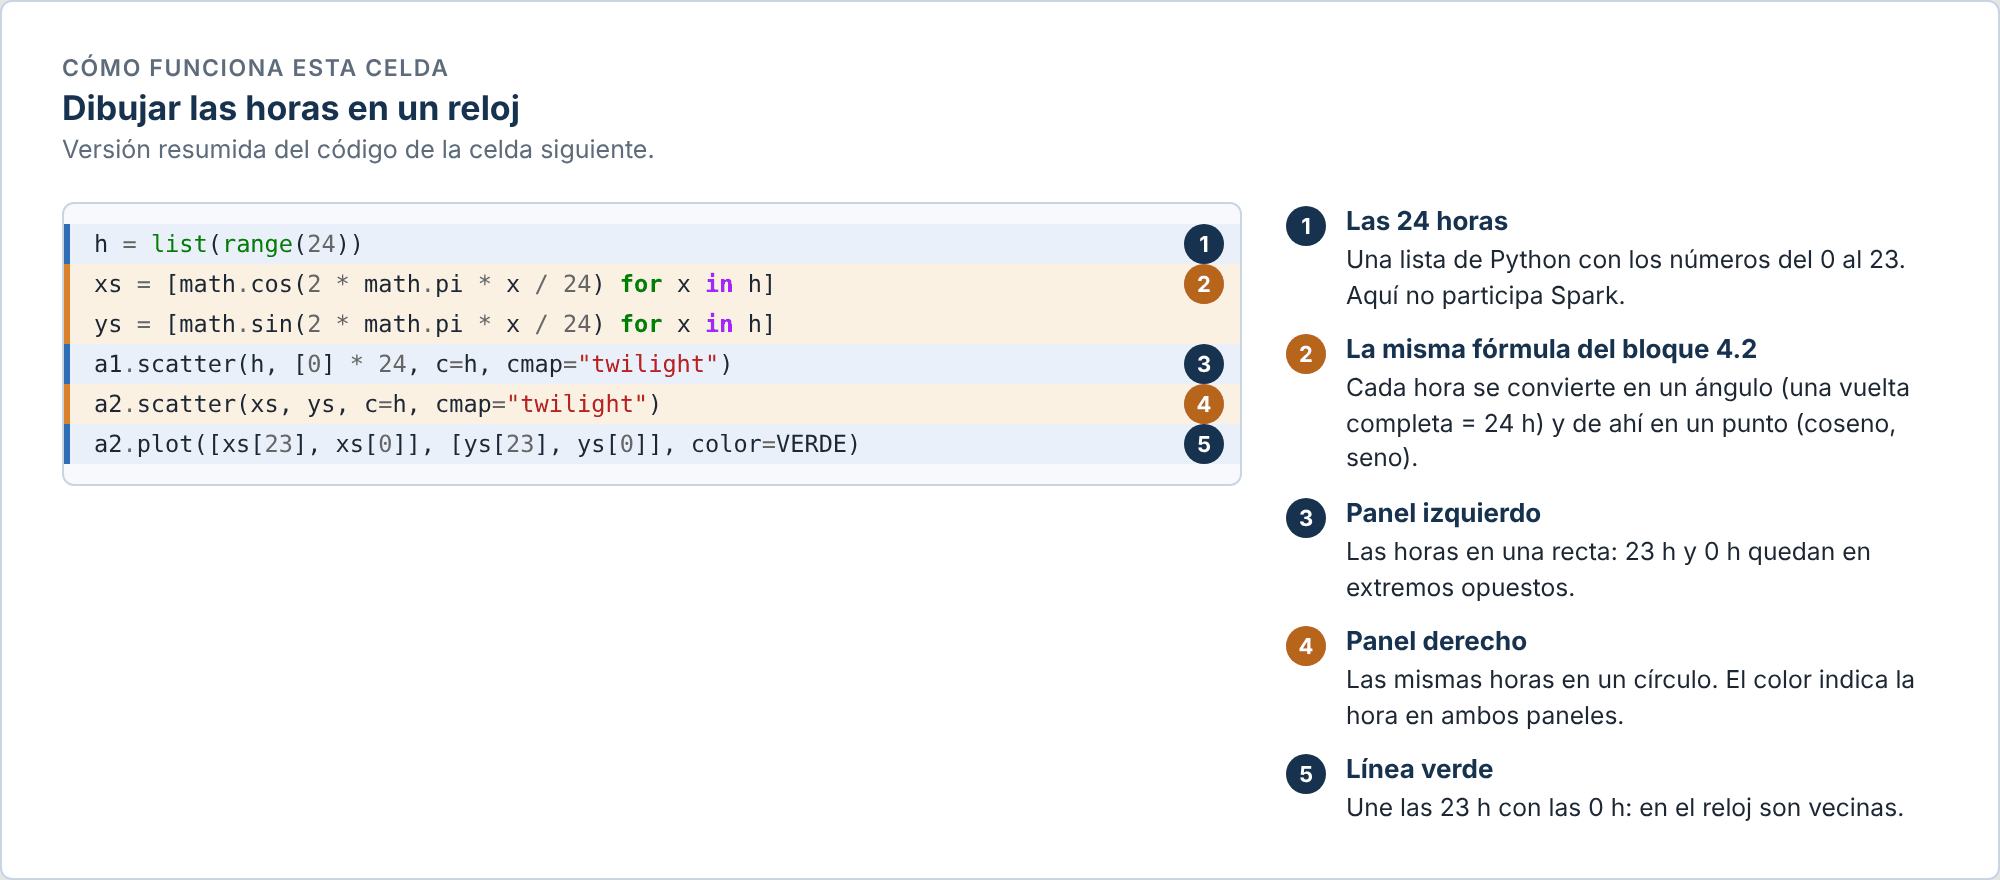

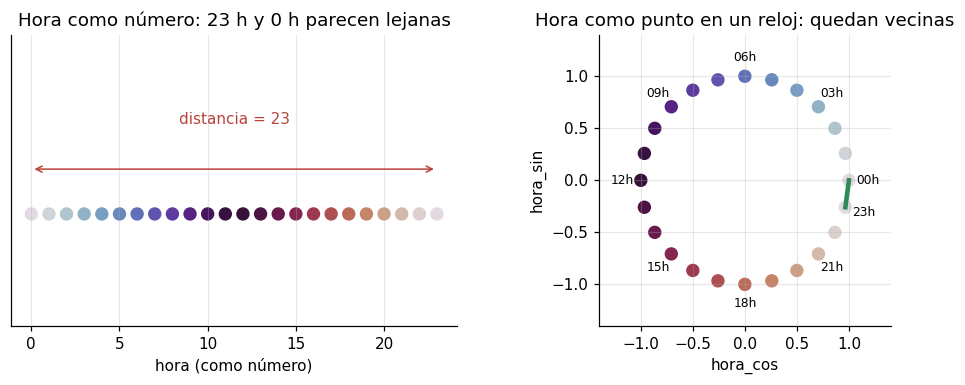

In [10]:
h = list(range(24))
xs = [math.cos(2 * math.pi * x / 24) for x in h]
ys = [math.sin(2 * math.pi * x / 24) for x in h]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6))

a1.scatter(h, [0] * 24, c=h, cmap="twilight", s=60)
a1.annotate("", xy=(23, 0.02), xytext=(0, 0.02), arrowprops=dict(arrowstyle="<->", color=ROJO))
a1.text(11.5, 0.04, "distancia = 23", ha="center", color=ROJO)
a1.set_yticks([]); a1.set_ylim(-0.05, 0.08); a1.set_xlabel("hora (como número)")
a1.set_title("Hora como número: 23 h y 0 h parecen lejanas")

a2.scatter(xs, ys, c=h, cmap="twilight", s=60)
for x, y, t in zip(xs, ys, h):
    if t % 3 == 0 or t == 23:
        a2.text(x * 1.18, y * 1.18, f"{t:02d}h", ha="center", va="center", fontsize=8)
a2.plot([xs[23], xs[0]], [ys[23], ys[0]], color=VERDE, lw=3)
a2.set_aspect("equal"); a2.set_xlim(-1.4, 1.4); a2.set_ylim(-1.4, 1.4)
a2.set_xlabel("hora_cos"); a2.set_ylabel("hora_sin")
a2.set_title("Hora como punto en un reloj: quedan vecinas")
plt.tight_layout(); plt.show()

---
## Bloque 5 · Fuga de información

> **Objetivo.** Decidir qué columnas **jamás** pueden entrar al modelo.

> **Concepto clave (analogía de la prueba).** Si un alumno entra a la prueba con las respuestas
> escritas en la mano, saca un 7... pero no aprendió nada. Un modelo con fuga de información saca
> resultados **espectaculares** en el laboratorio y **falla** en la vida real.

**La regla:** una columna solo puede ser característica si **estaría disponible en el momento de
predecir**, con el sensor enviando datos en vivo.

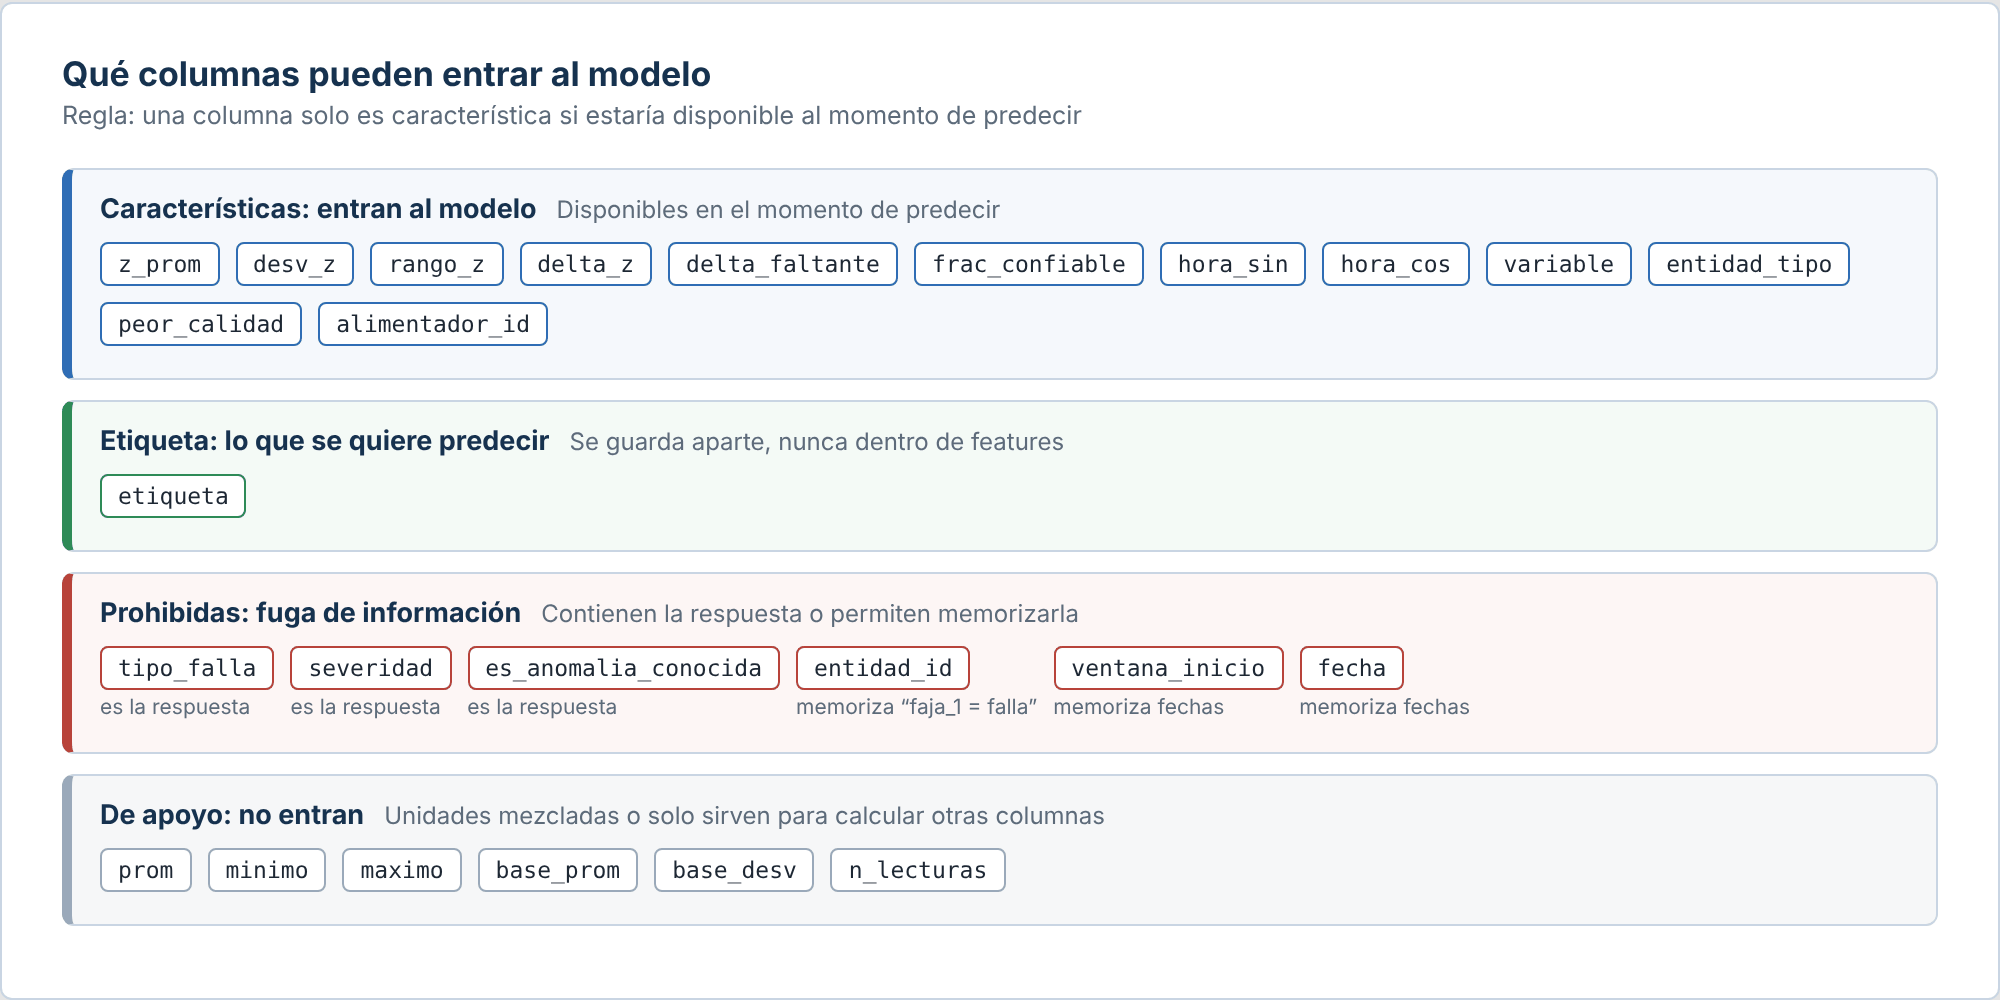

Dejamos la decisión **escrita en código**, para que el bloque 9 verifique que nadie la rompa:

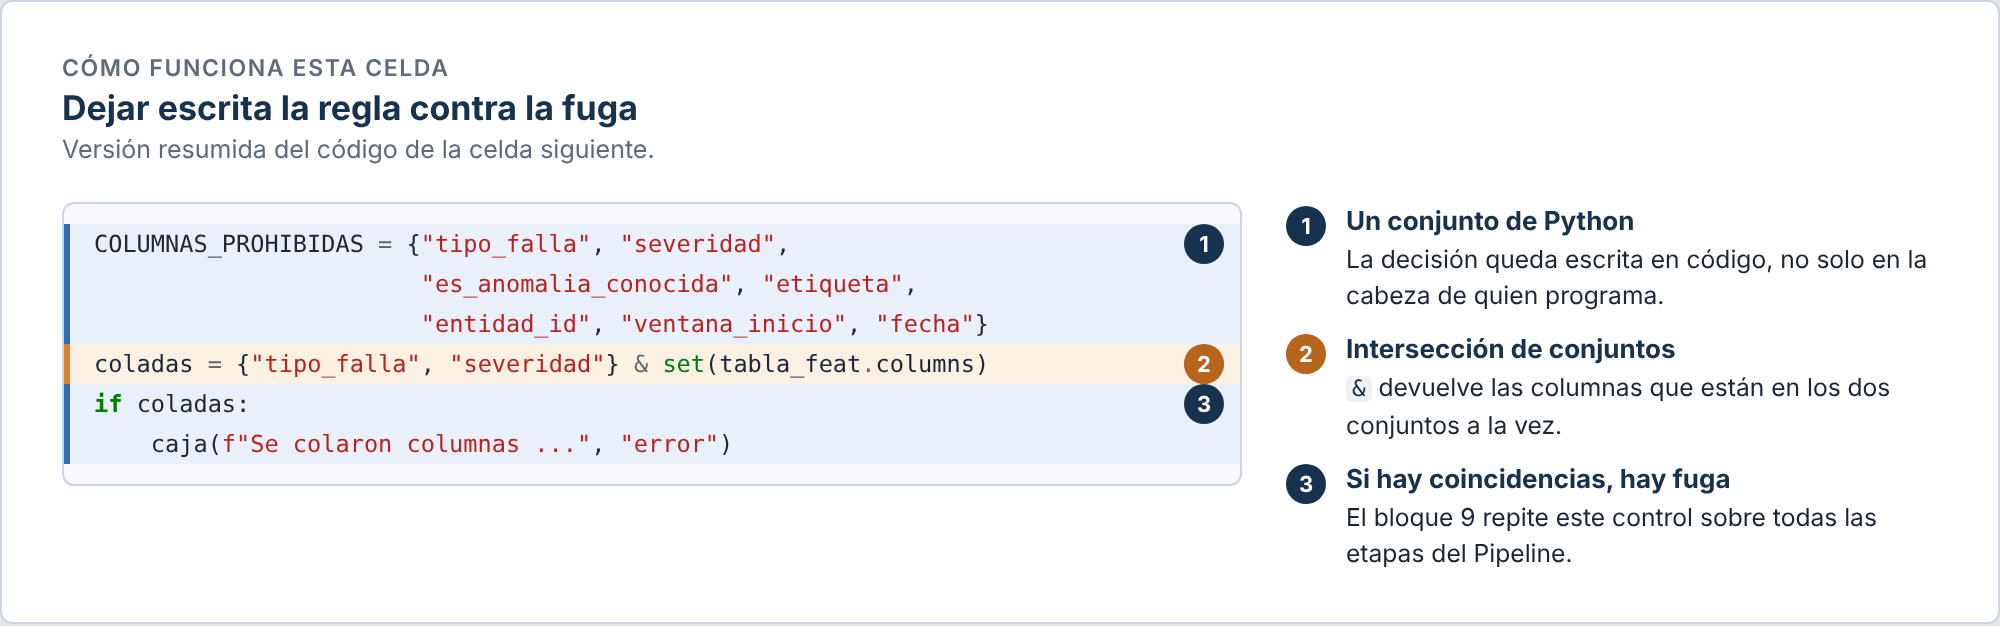

In [11]:
COLUMNAS_PROHIBIDAS = {"en_falla", "falla_id", "tipo_falla", "severidad", "es_anomalia_conocida", "etiqueta",
                       "entidad_id", "ventana_inicio", "fecha"}

coladas = {"tipo_falla", "severidad"} & set(tabla_feat.columns)
if coladas:
    caja(f"Se colaron columnas de la verdad de terreno: {coladas}", "error")
else:
    caja("Ninguna columna de la verdad de terreno (<code>tipo_falla</code>, <code>severidad</code>) "
         "está en la tabla de trabajo.")

---
## Bloque 6 · Valores nulos: primero entender, después arreglar

> **Objetivo.** Dejar **cero nulos**, pero tratando cada uno según **por qué** está vacío.

> **Concepto clave.** `dropna()` (borrar filas con nulos) es lo más rápido... y casi siempre lo peor:
> perderíamos ejemplos valiosos sin saber por qué. Como en la Fase 2: **primero se mide, después se decide.**

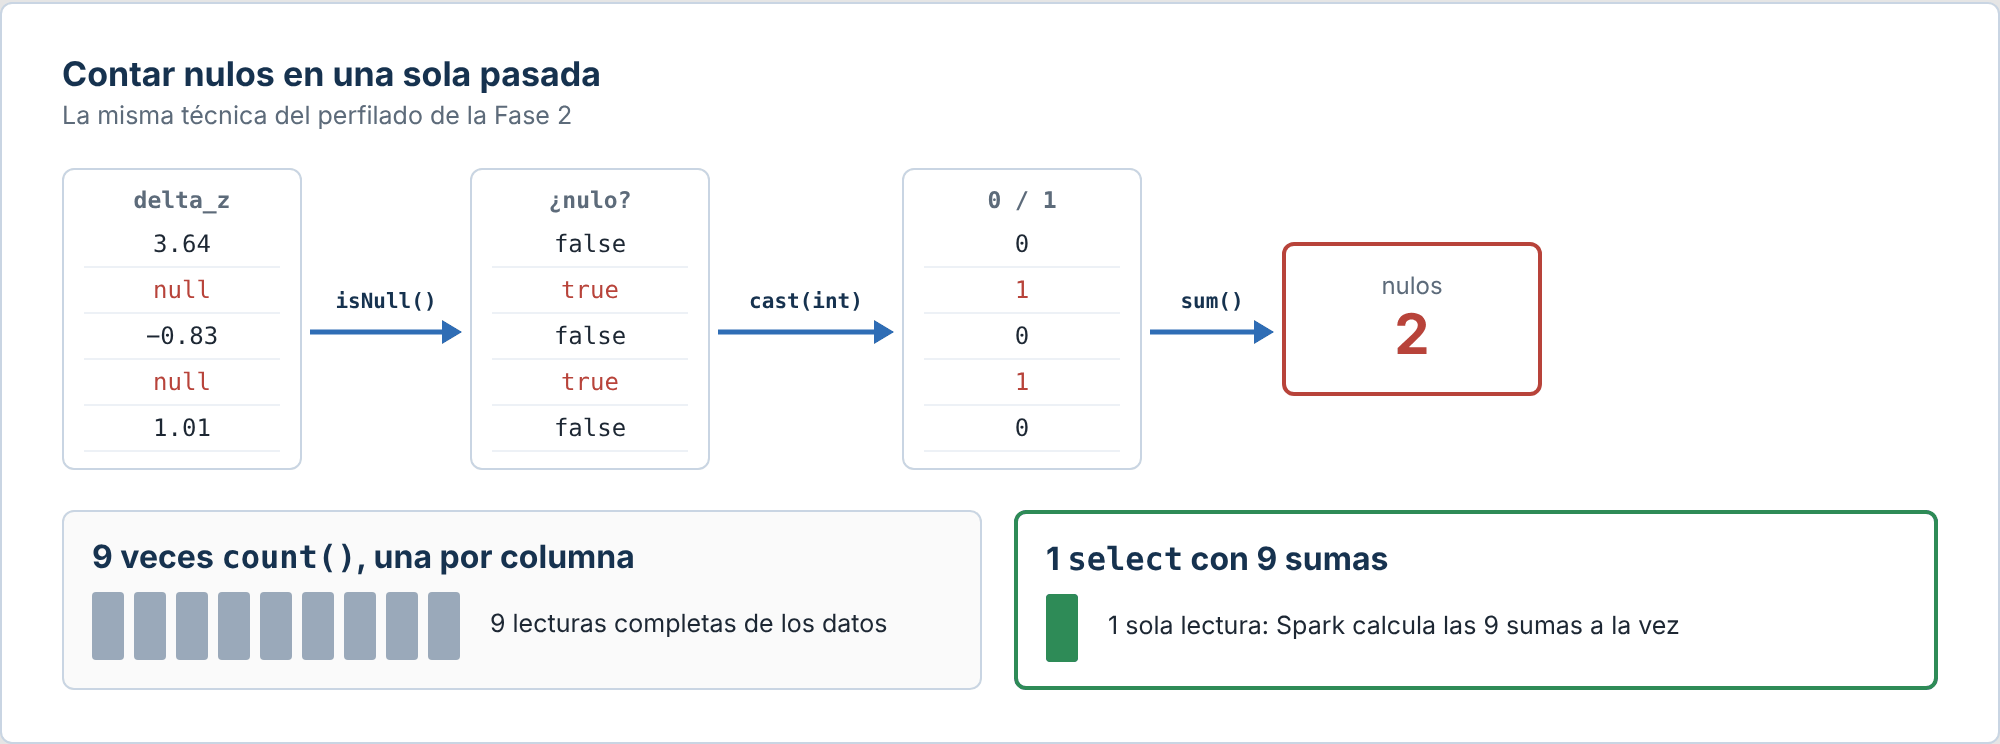

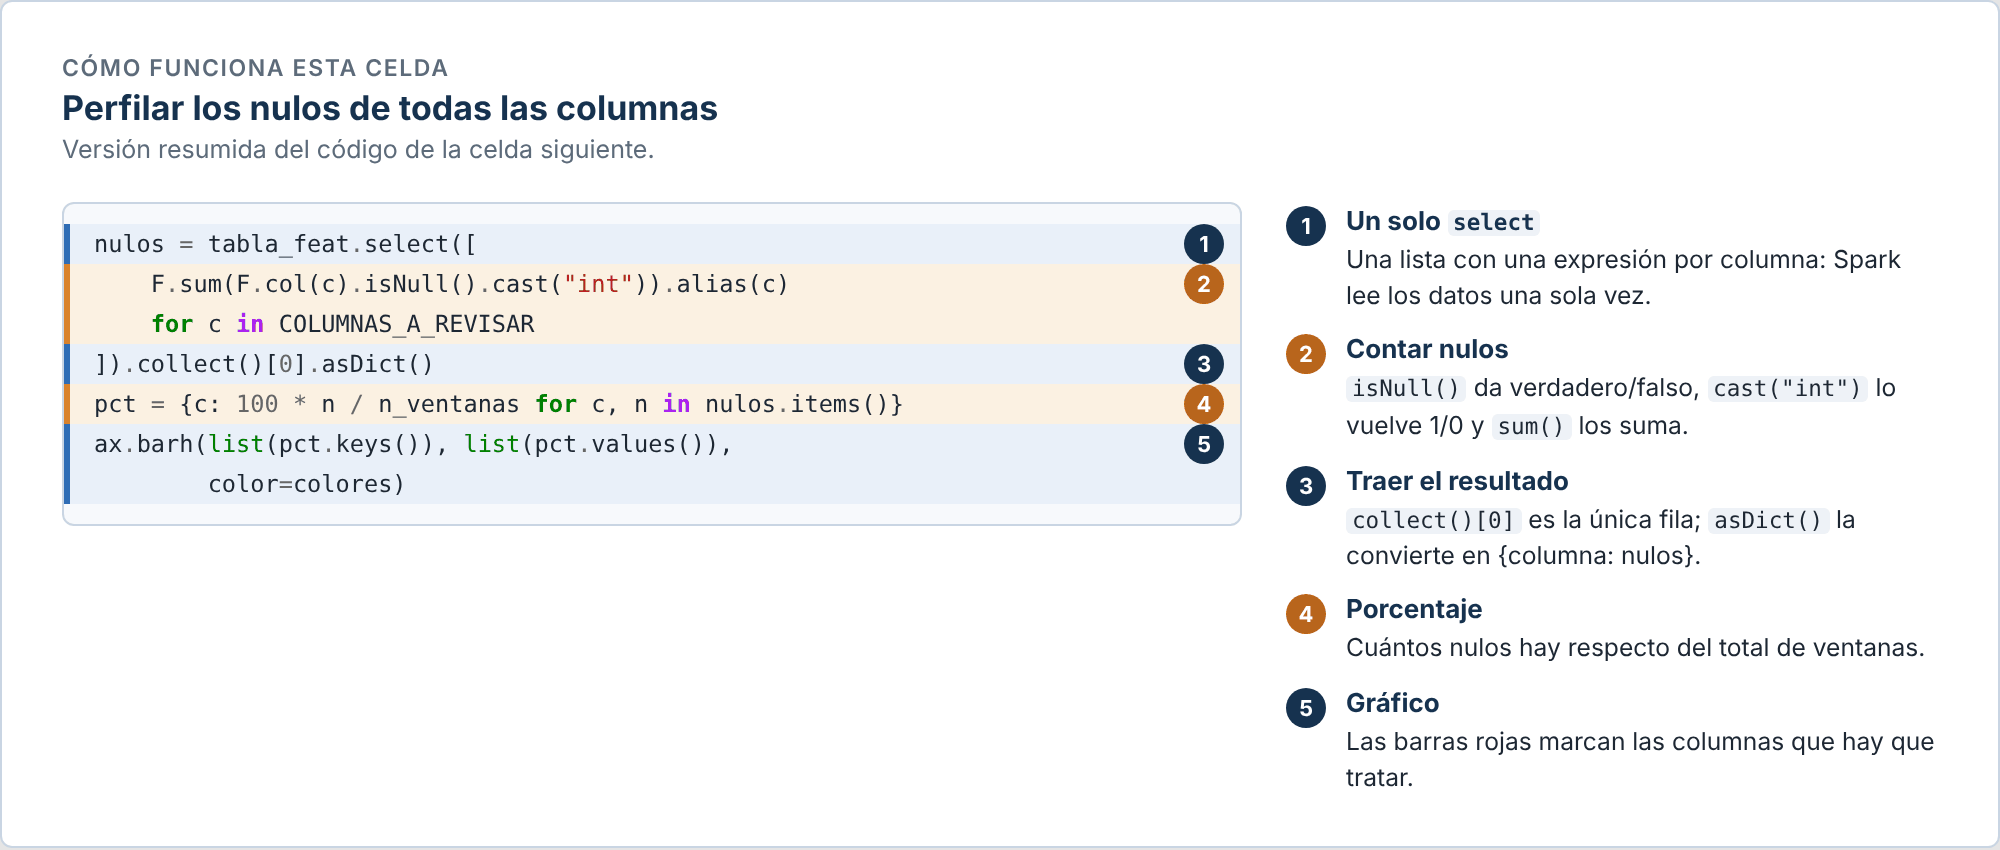

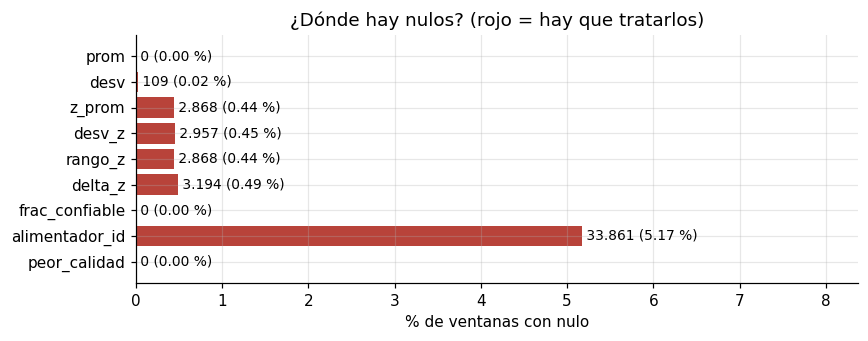

In [12]:
COLUMNAS_A_REVISAR = ["prom", "desv", "z_prom", "desv_z", "rango_z", "delta_z",
                      "frac_confiable", "alimentador_id", "peor_calidad"]

# Una sola pasada para contar los nulos de todas las columnas a la vez
nulos = tabla_feat.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c) for c in COLUMNAS_A_REVISAR
]).collect()[0].asDict()

pct = {c: 100 * n / n_ventanas for c, n in nulos.items()}
fig, ax = plt.subplots(figsize=(8, 3.2))
colores = [ROJO if v > 0 else GRIS for v in pct.values()]
ax.barh(list(pct.keys()), list(pct.values()), color=colores)
for y, (c, v) in enumerate(pct.items()):
    ax.text(v, y, f" {miles(nulos[c])} ({v:.2f} %)", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("% de ventanas con nulo")
ax.set_title("¿Dónde hay nulos? (rojo = hay que tratarlos)")
ax.set_xlim(0, max(pct.values()) * 1.6 + 0.1)
plt.tight_layout(); plt.show()

### 6.1 · Tres causas, tres tratamientos

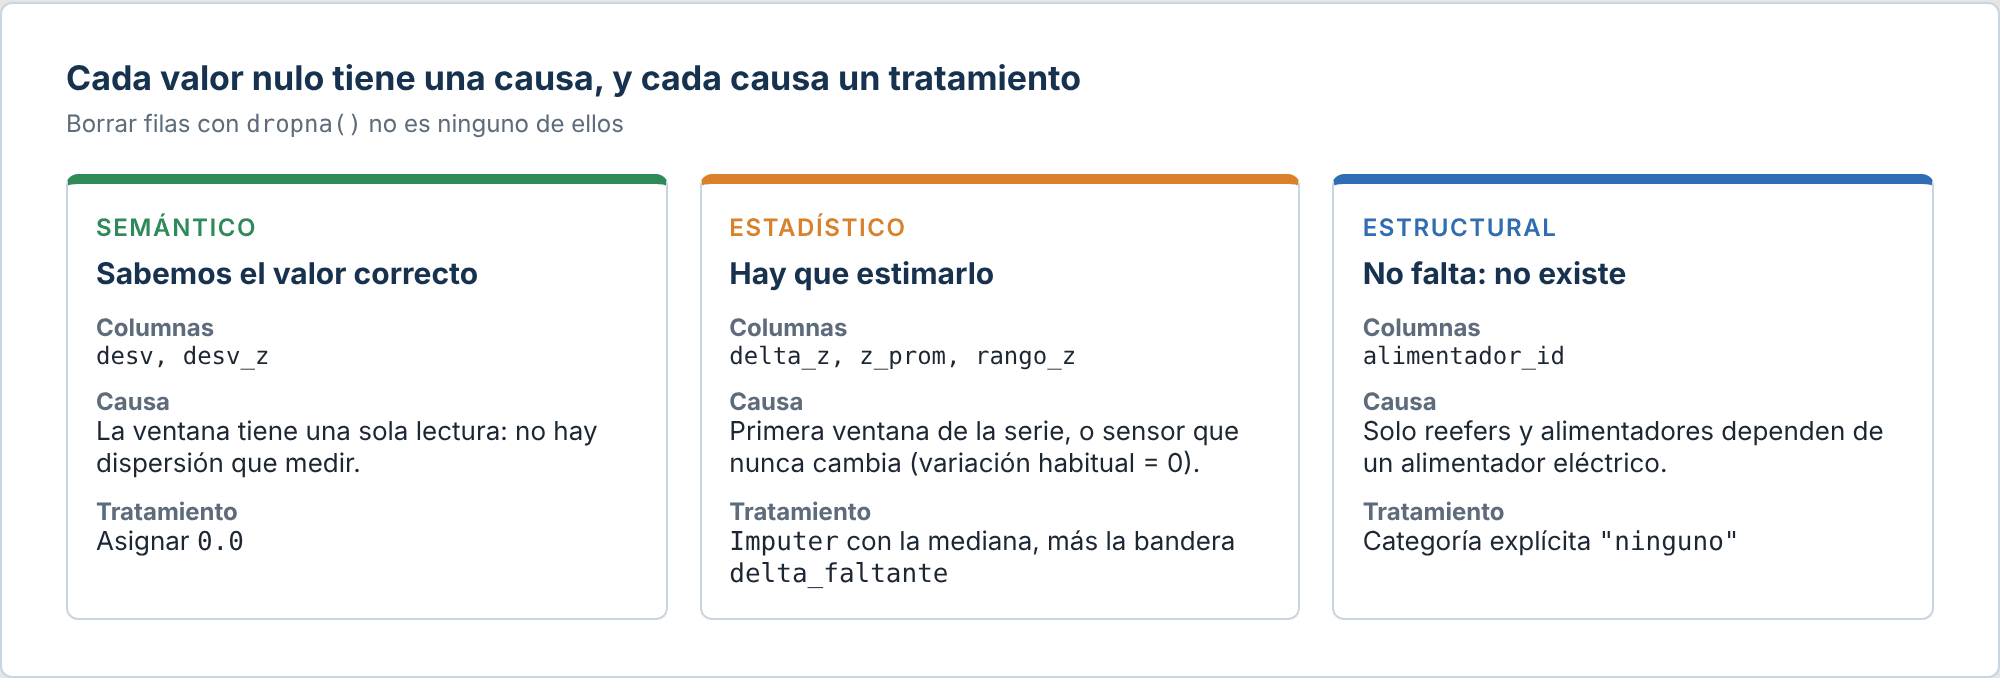

> **¿Qué es la bandera `delta_faltante`?** Una columna que vale **1** si el dato faltaba y **0** si no.
> El hecho de que un dato falte **también es información**, y así el modelo puede usarla.

> **Nota.** Es normal que alguna columna tenga **0 nulos** en tu ejecución. El tratamiento se deja igual: el
> pipeline debe aguantar los datos de mañana, no solo los de hoy.

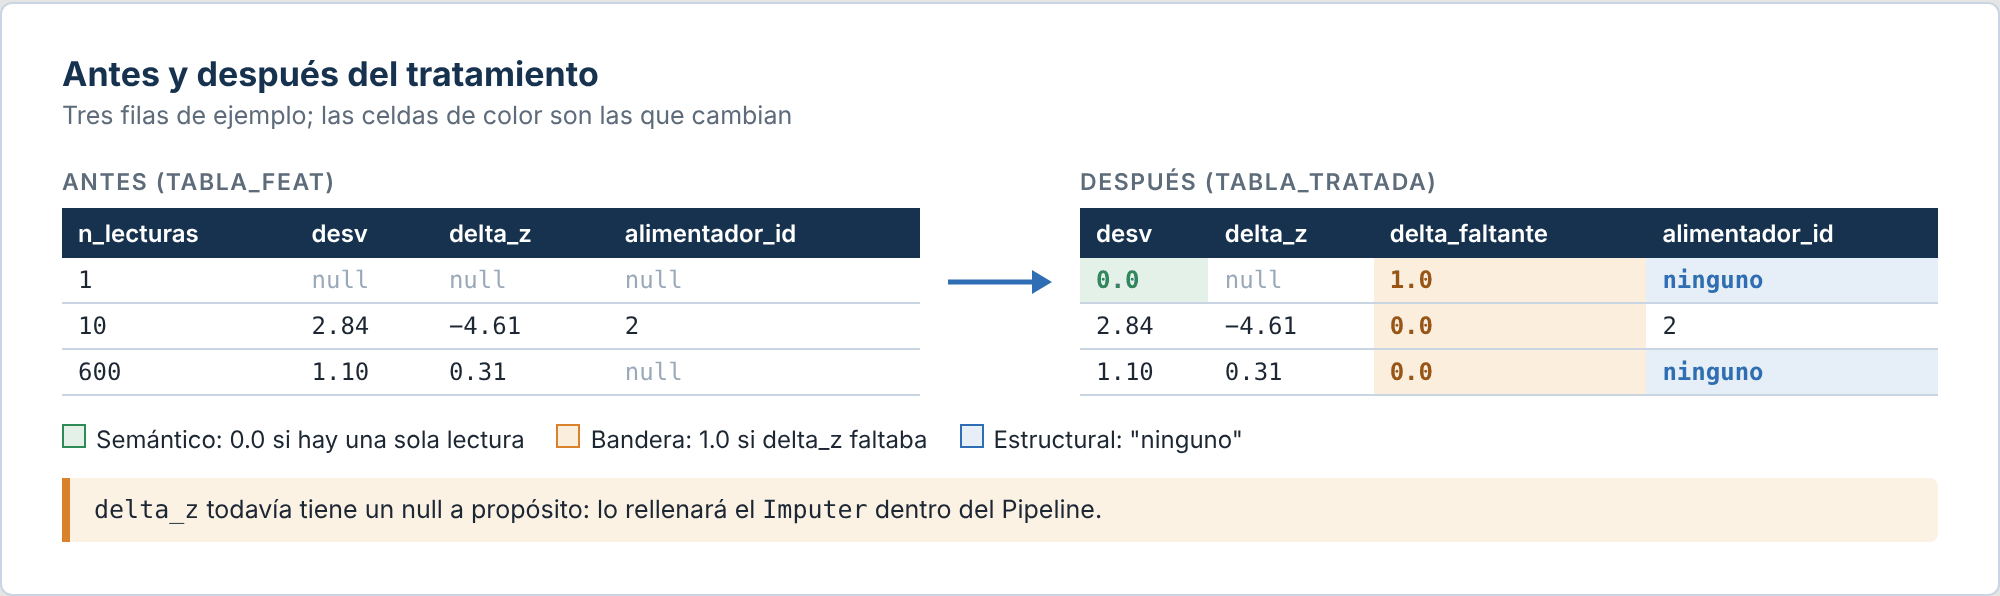

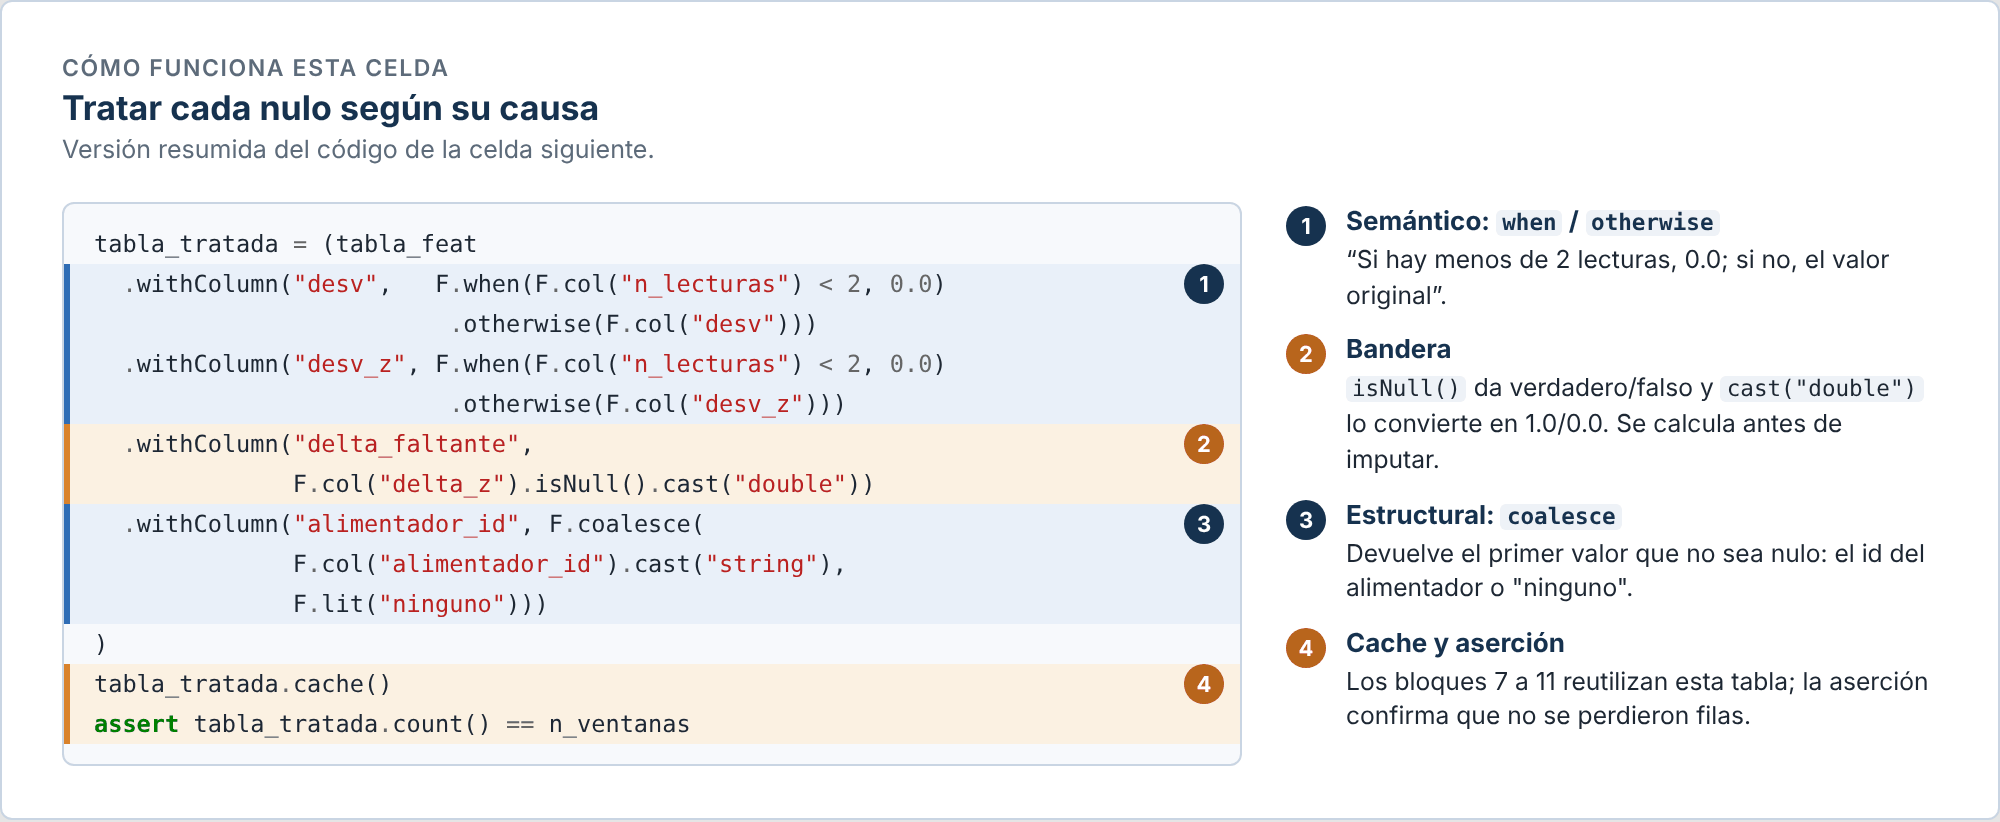

In [13]:
tabla_tratada = (
    tabla_feat
    # Semántico: una sola lectura -> no hay dispersión observable
    .withColumn("desv",   F.when(F.col("n_lecturas") < 2, F.lit(0.0)).otherwise(F.col("desv")))
    .withColumn("desv_z", F.when(F.col("n_lecturas") < 2, F.lit(0.0)).otherwise(F.col("desv_z")))
    # Bandera: ¿faltaba el dato? (se calcula ANTES de rellenar)
    .withColumn("delta_faltante", F.col("delta_z").isNull().cast("double"))
    # Estructural: no es que falte el alimentador, es que no tiene
    .withColumn("alimentador_id", F.coalesce(F.col("alimentador_id").cast("string"), F.lit("ninguno")))
)
# z_prom, desv_z, rango_z y delta_z conservan sus nulos: los rellenará el Imputer
# DENTRO del pipeline (bloque 9). Enseguida verás por qué ahí.

tabla_tratada.cache()
assert tabla_tratada.count() == n_ventanas

display(tabla_tratada.groupBy("entidad_tipo", "alimentador_id").count()
        .orderBy("entidad_tipo", "alimentador_id").toPandas())

,entidad_tipo,alimentador_id,count
0,alimentador,0,4032
1,alimentador,1,4032
2,alimentador,2,4032
3,alimentador,3,4032
4,ambiente,ninguno,10080
5,bascula,ninguno,3912
6,buque,ninguno,2016
7,faja,ninguno,10080
8,grua,ninguno,5757
9,operacion,ninguno,2016


### 6.2 · ¿Qué pasa si dejamos un nulo? Provoquemos el error a propósito

`VectorAssembler` es la pieza que junta varias columnas en **un solo vector**. Por defecto **se niega**
a trabajar con nulos. Hay tres formas de reaccionar, según el parámetro `handleInvalid`:

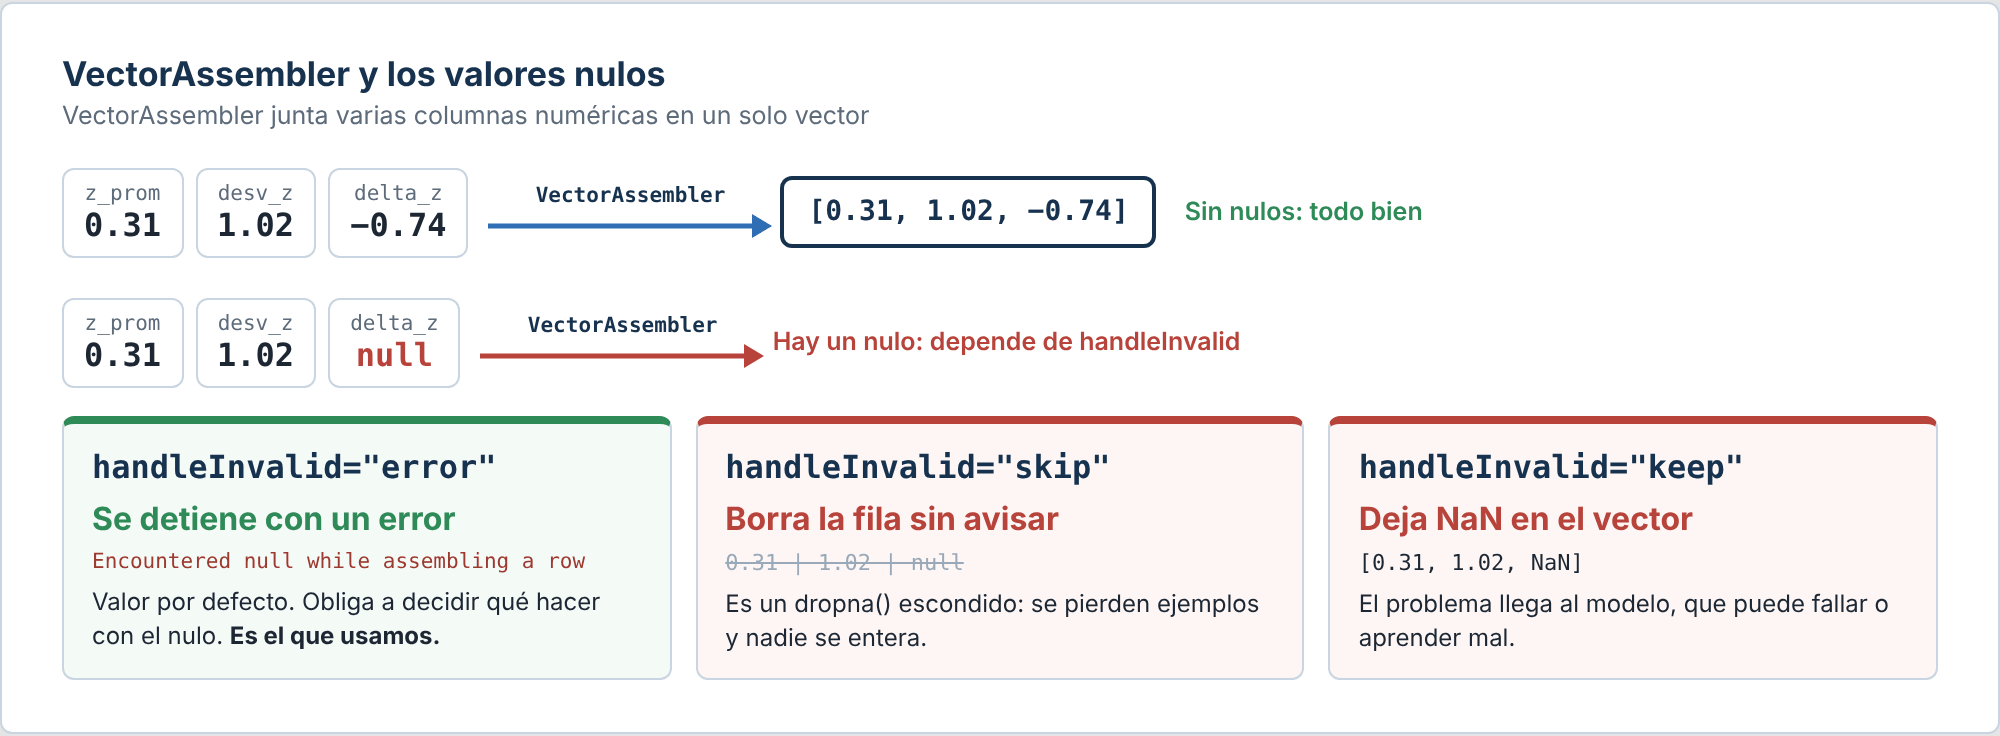

Comprobemos la primera, que es la que viene por defecto:

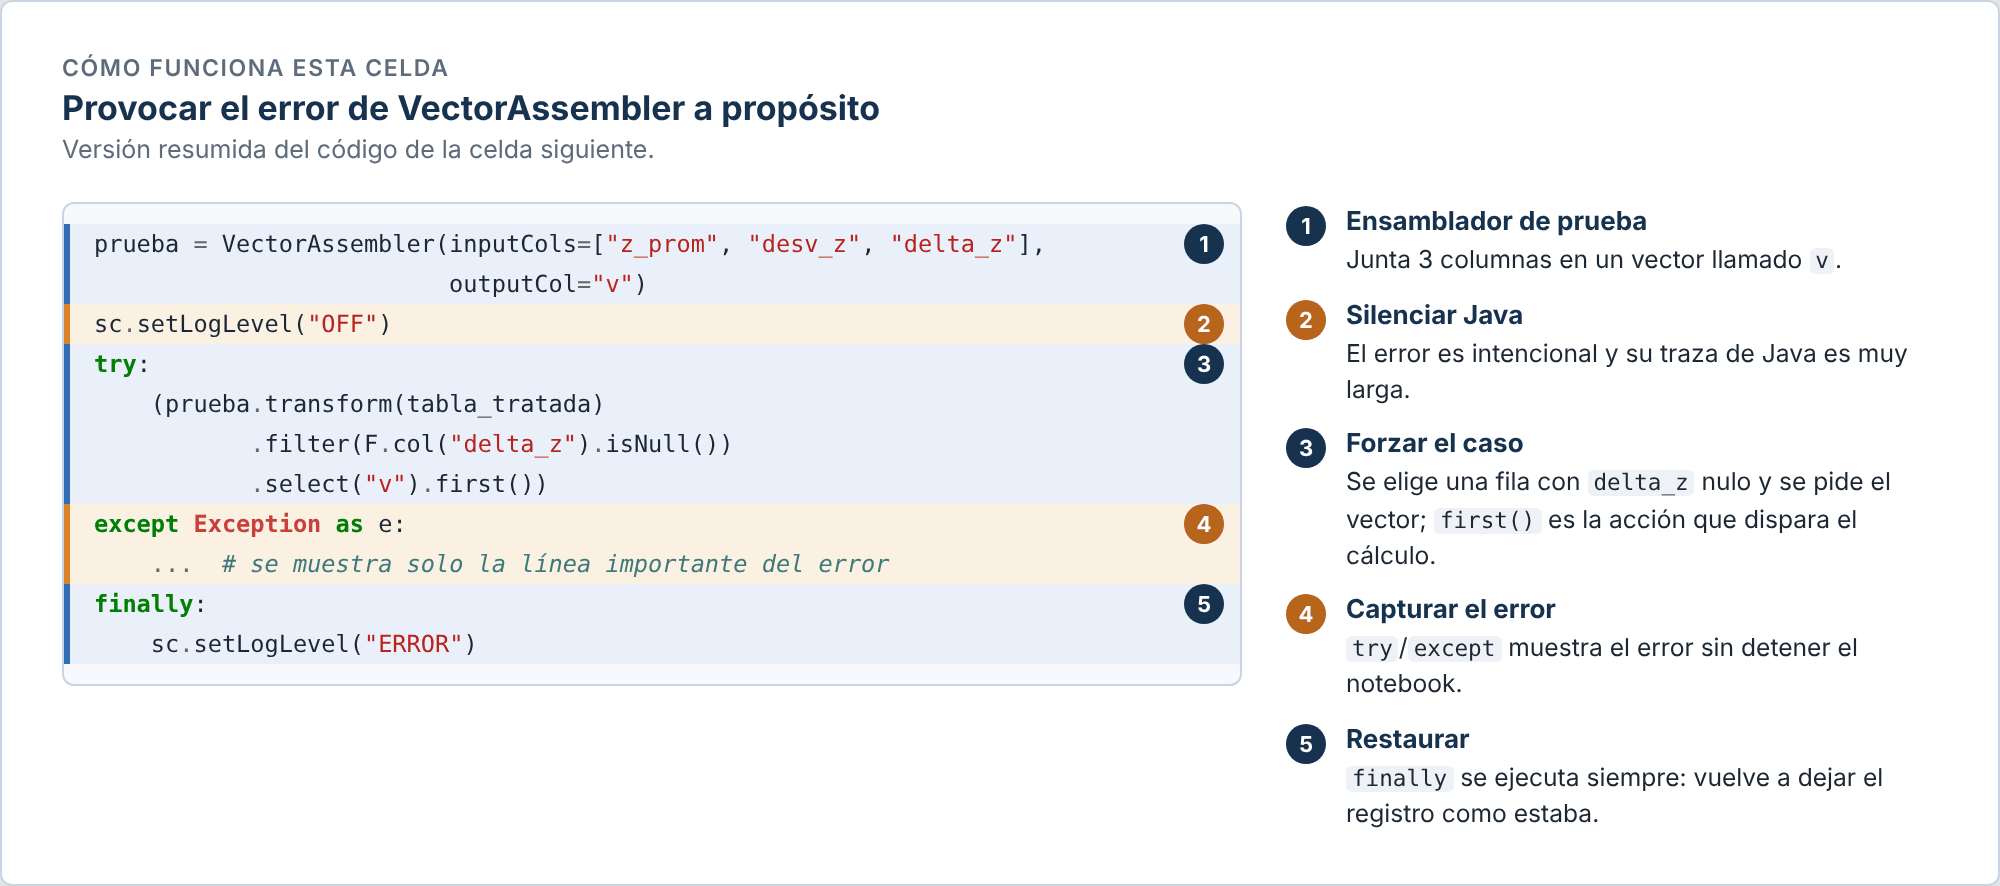

In [14]:
prueba = VectorAssembler(inputCols=["z_prom", "desv_z", "delta_z"], outputCol="v")

sc.setLogLevel("OFF")      # silenciamos el error de Java: lo estamos provocando a propósito
try:
    prueba.transform(tabla_tratada).filter(F.col("delta_z").isNull()).select("v").first()
    caja("No hubo error: ¿ya no quedan nulos en delta_z?", "warn")
except Exception as e:
    texto = str(e)
    i = texto.find("Encountered null")
    mensaje = texto[i:texto.find("\".", i) + 2] if i >= 0 else texto.splitlines()[0][:200]
    caja(f"<code>{mensaje}</code>", "error", "VectorAssembler se negó (¡esto es lo esperado!)")
finally:
    sc.setLogLevel("ERROR")

### 6.3 · `Imputer`: nuestro primer **Estimator**

`Imputer` rellena los nulos con la **mediana** de cada columna. Pero, para saber cuál es la mediana,
primero tiene que **mirar los datos y calcularla**. Eso lo convierte en un *Estimator*:

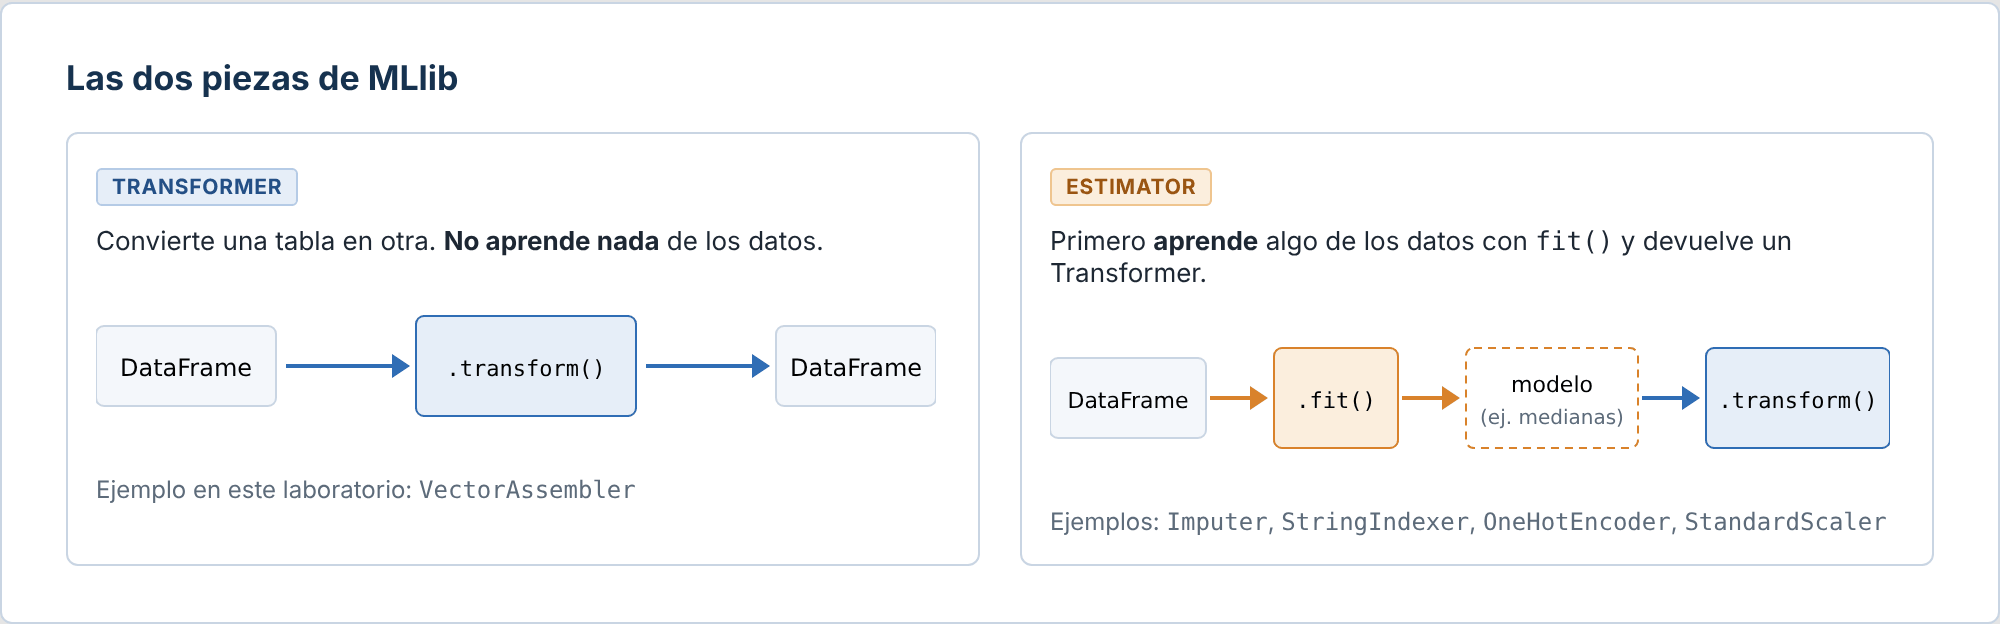

> **¿Por qué la mediana y no el promedio?** Las ventanas con fallas tienen valores extremos. El
> promedio se deja “arrastrar” por ellos; la mediana (el valor del medio) no.

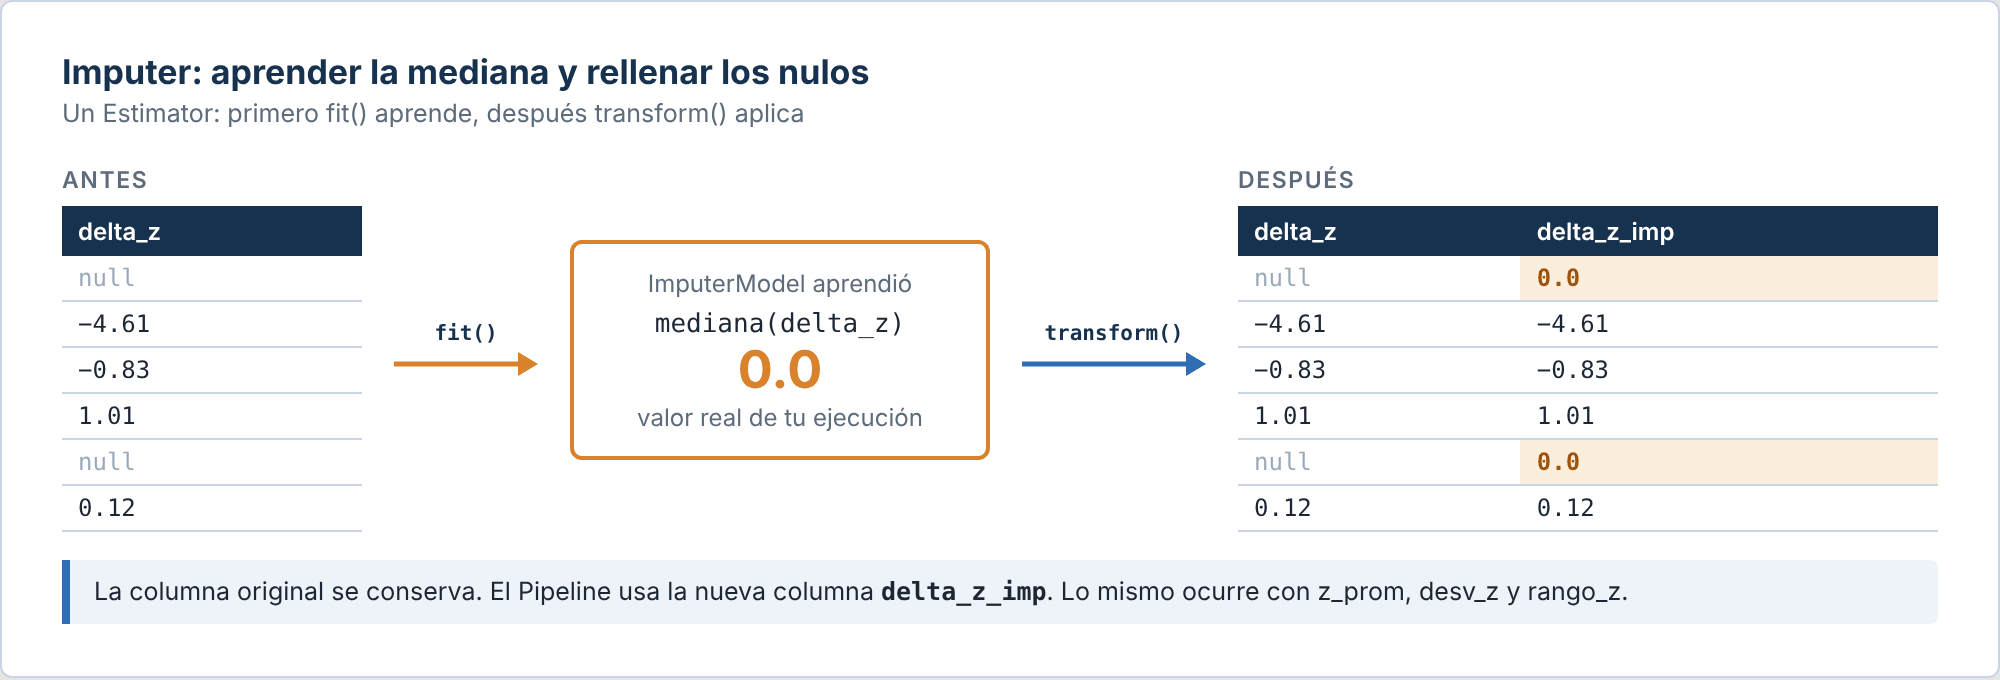

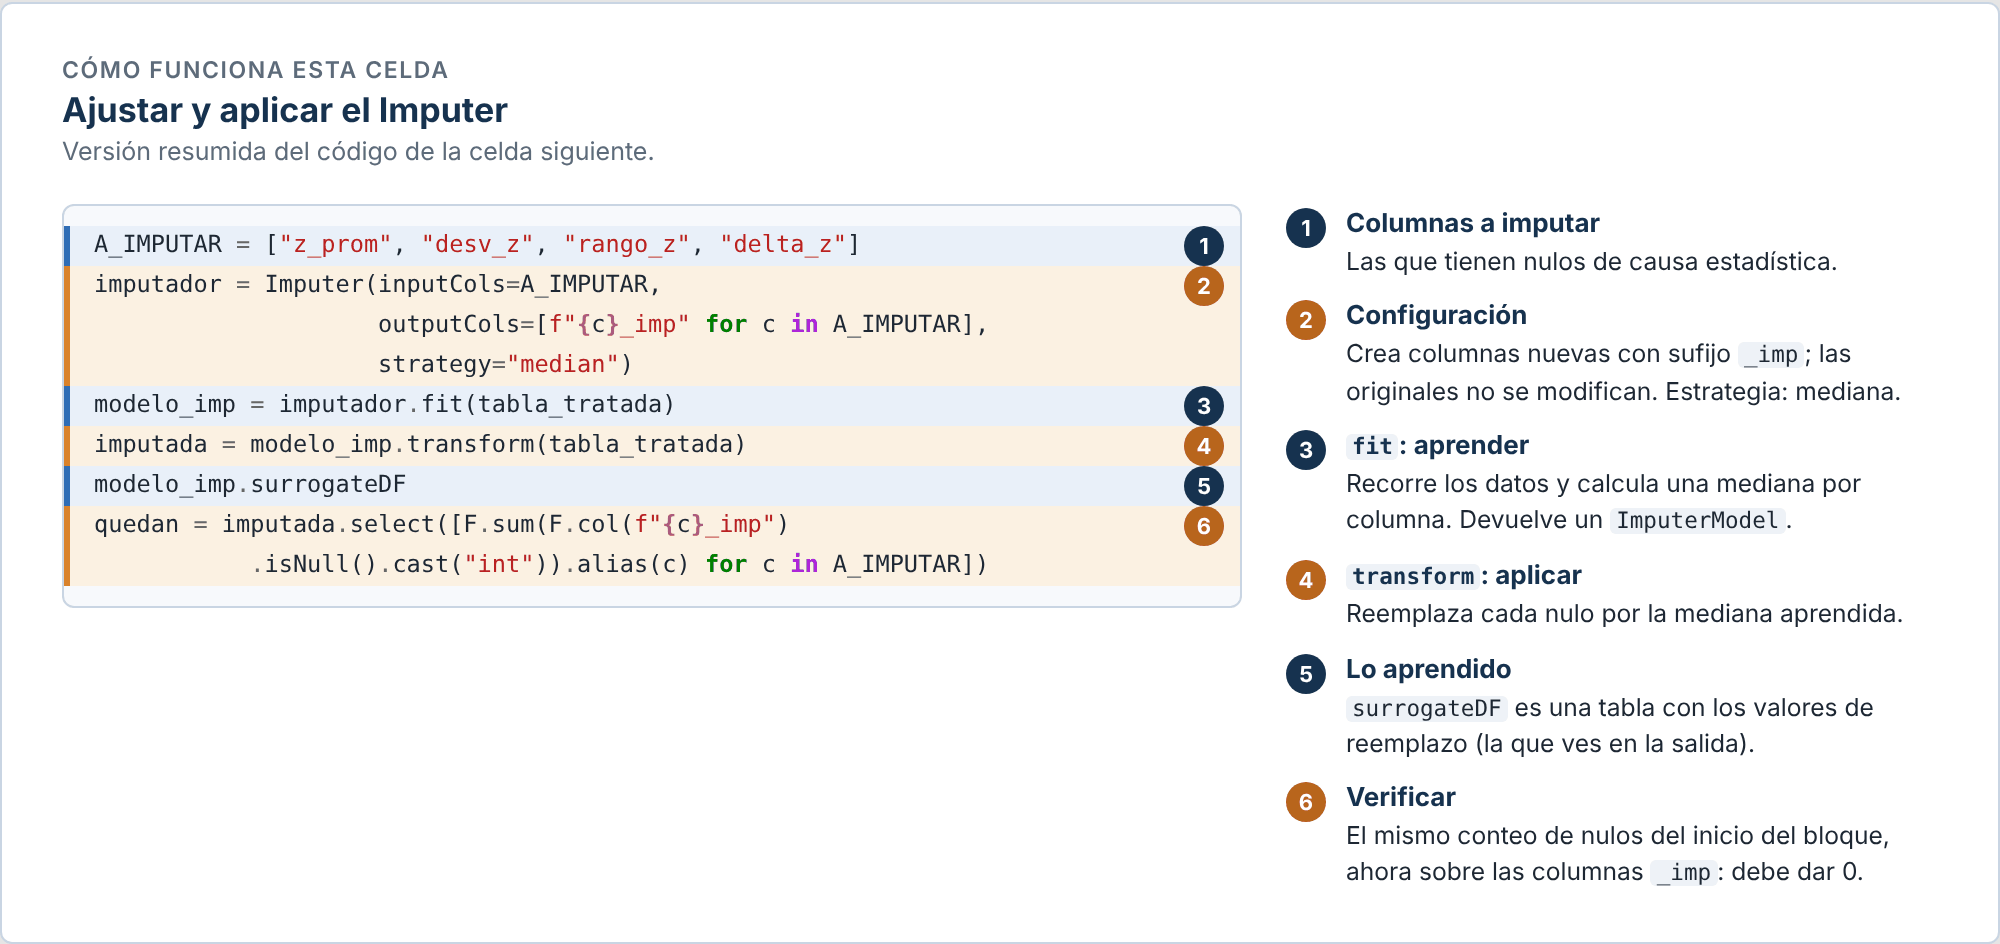

In [15]:
A_IMPUTAR = ["z_prom", "desv_z", "rango_z", "delta_z"]

imputador = Imputer(inputCols=A_IMPUTAR,
                    outputCols=[f"{c}_imp" for c in A_IMPUTAR],
                    strategy="median")

modelo_imp = imputador.fit(tabla_tratada)          # fit: aprende las medianas
imputada = modelo_imp.transform(tabla_tratada)     # transform: rellena

aprendido = modelo_imp.surrogateDF.toPandas().T.rename(columns={0: "valor de relleno (mediana)"})
quedan = imputada.select([F.sum(F.col(f"{c}_imp").isNull().cast("int")).alias(c)
                          for c in A_IMPUTAR]).collect()[0].asDict()
aprendido["nulos antes"] = [miles(nulos[c]) for c in A_IMPUTAR]
aprendido["nulos después"] = [quedan[c] for c in A_IMPUTAR]
display(aprendido)
caja("Todas las columnas imputadas quedaron con <b>0 nulos</b>." if sum(quedan.values()) == 0
     else "Aún quedan nulos: revisa el tratamiento.", "ok" if sum(quedan.values()) == 0 else "error")

,valor de relleno (mediana),nulos antes,nulos después
z_prom,-0.462757,2.868,0
desv_z,0.000000,2.957,0
rango_z,0.000000,2.868,0
delta_z,0.000000,3.194,0


<details>
<summary><b>Pregunta de repaso:</b> ¿por qué la mediana de <code>desv_z</code> puede salir 0? (clic para ver la respuesta)</summary>

Varias variables del Sitio 3 son de tipo **encendido/apagado** o cambian muy poco (por ejemplo
`compresor_on` o `nave_en_sitio`). En la mayoría de sus ventanas el valor no se mueve, así que su
dispersión es 0. Como esas ventanas son muchísimas, el valor “del medio” termina siendo 0.

</details>

---
## Bloque 7 · Convertir texto en números

> **Objetivo.** Que las columnas de texto (`variable`, `entidad_tipo`, `peor_calidad`, `alimentador_id`)
> se conviertan en números **sin inventar un orden falso**.

Se hace en **dos pasos**:

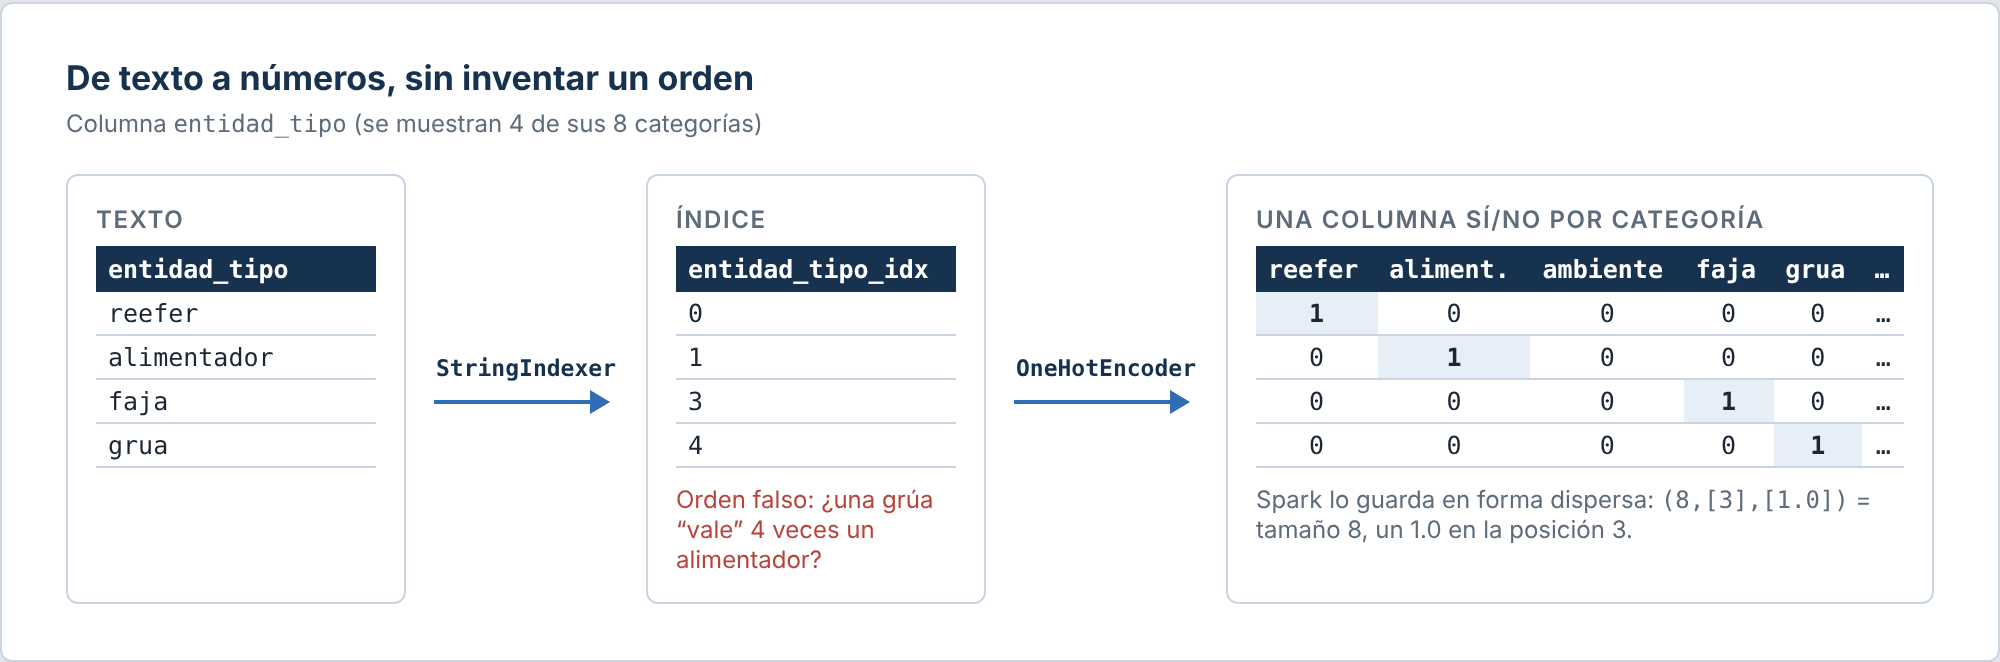

### 7.1 · `StringIndexer`: a cada texto, un número

La categoría **más frecuente** recibe el **0**, la segunda el **1**, y así. Con `handleInvalid="keep"`
reserva un número extra para categorías **nuevas** que aparezcan mañana, así el pipeline no se cae.

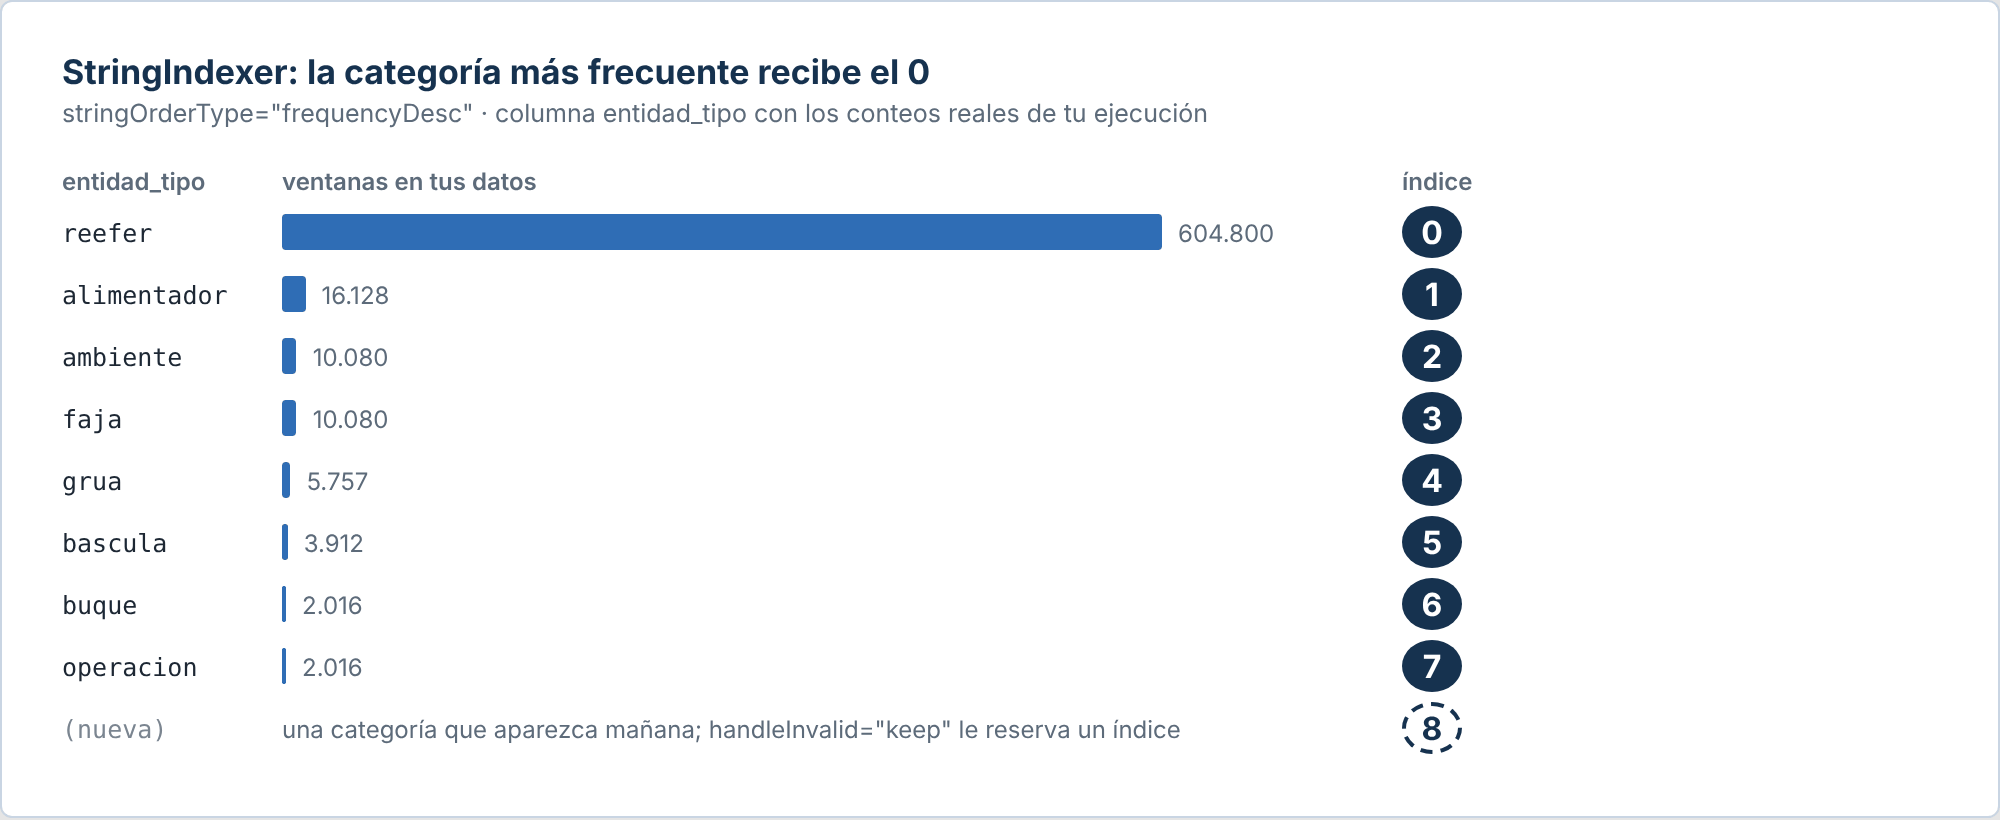

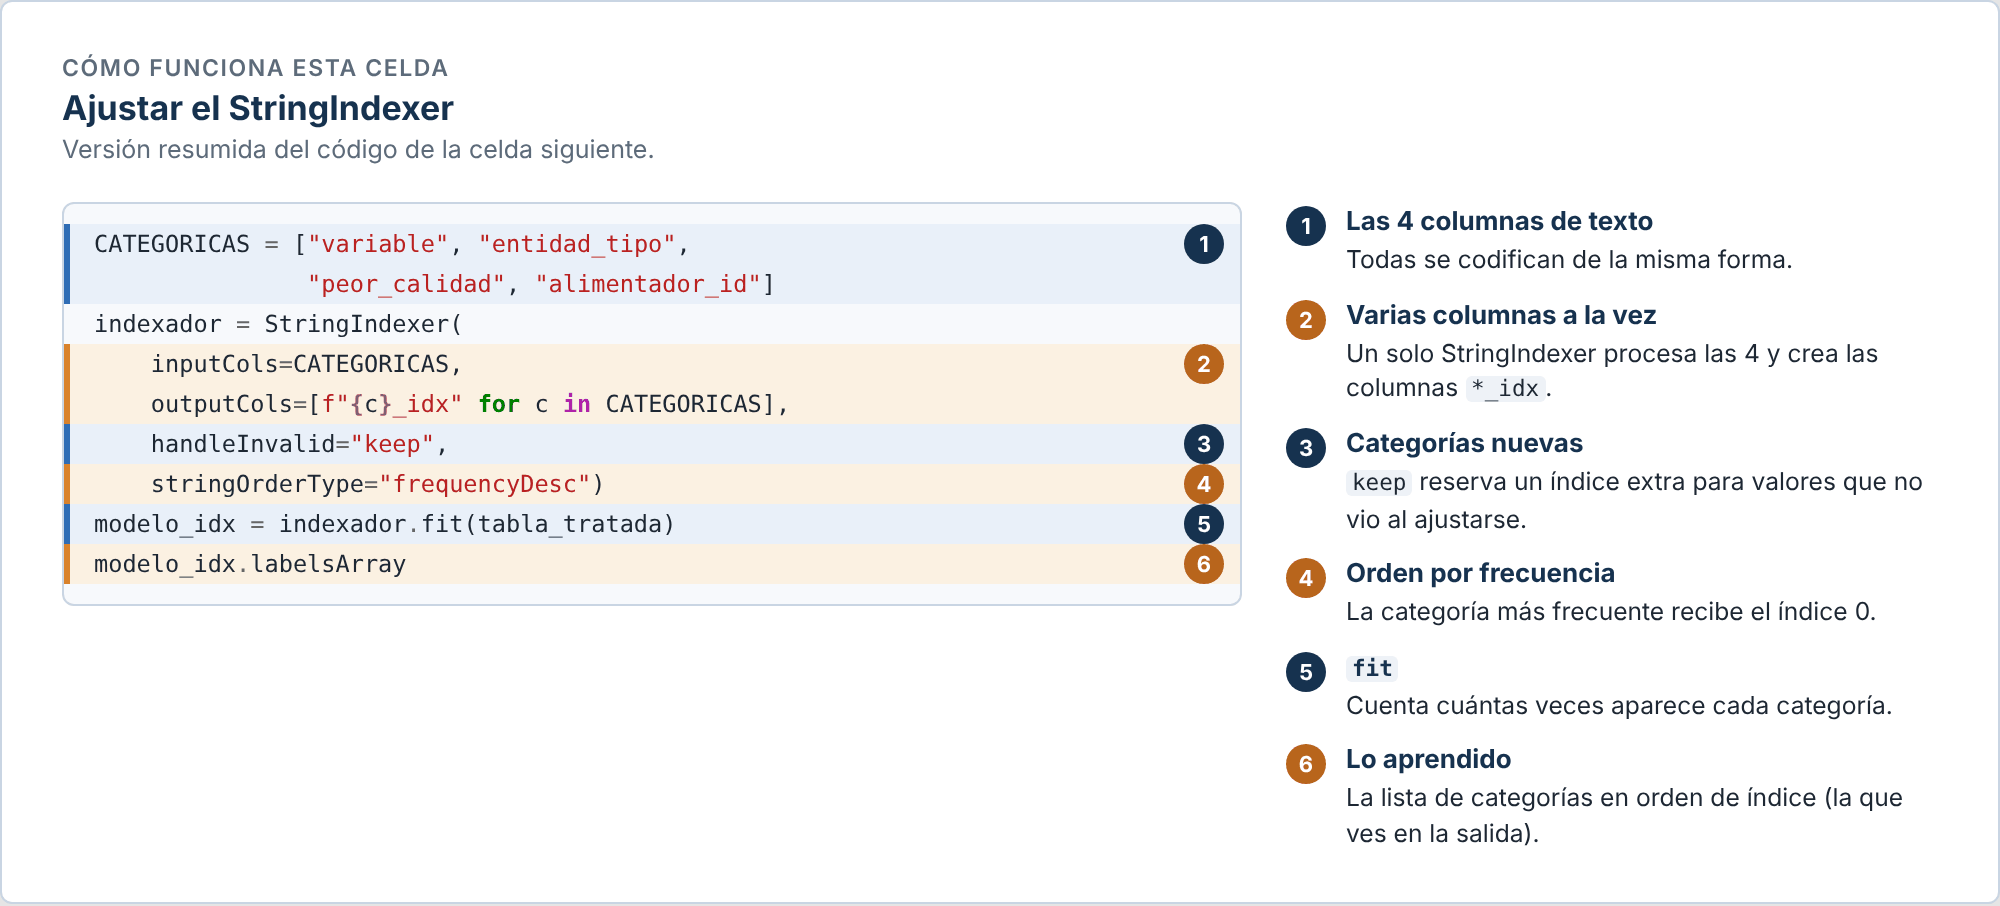

In [16]:
CATEGORICAS = ["variable", "entidad_tipo", "peor_calidad", "alimentador_id"]

indexador = StringIndexer(inputCols=CATEGORICAS,
                          outputCols=[f"{c}_idx" for c in CATEGORICAS],
                          handleInvalid="keep",
                          stringOrderType="frequencyDesc")

modelo_idx = indexador.fit(tabla_tratada)          # aprende qué categorías existen

for col, etiquetas_col in zip(CATEGORICAS, modelo_idx.labelsArray):
    if col == "variable":
        print(f"variable: {len(etiquetas_col)} categorías (la más frecuente es '{etiquetas_col[0]}')")
        continue
    display(pd.DataFrame({"categoría": etiquetas_col,
                          "índice": range(len(etiquetas_col))}).set_index("categoría").T
            .rename(index={"índice": col}))

variable: 21 categorías (la más frecuente es 'temperatura_c')


categoría,reefer,alimentador,ambiente,faja,grua,bascula,buque,operacion
entidad_tipo,0,1,2,3,4,5,6,7


categoría,ok,asentamiento,deriva,pegado
peor_calidad,0,1,2,3


categoría,0,1,2,3,ninguno
alimentador_id,0,1,2,3,4


### 7.2 · ¿Por qué no basta con el índice?

Si le damos `entidad_tipo_idx` tal cual, el modelo creería que una **faja (3)** es “más” que un
**reefer (0)**, o que **pegado (3)** es “el triple” de **asentamiento (1)**. ¡Eso no tiene sentido!

### 7.3 · `OneHotEncoder`: una columna “sí/no” por categoría

Cada categoría pasa a ser una columna que vale 1 o 0, como se vio en el diagrama anterior.

Como casi todo son ceros, Spark guarda solo las posiciones que valen 1. Esa forma de escribirlo se llama
**vector disperso**:

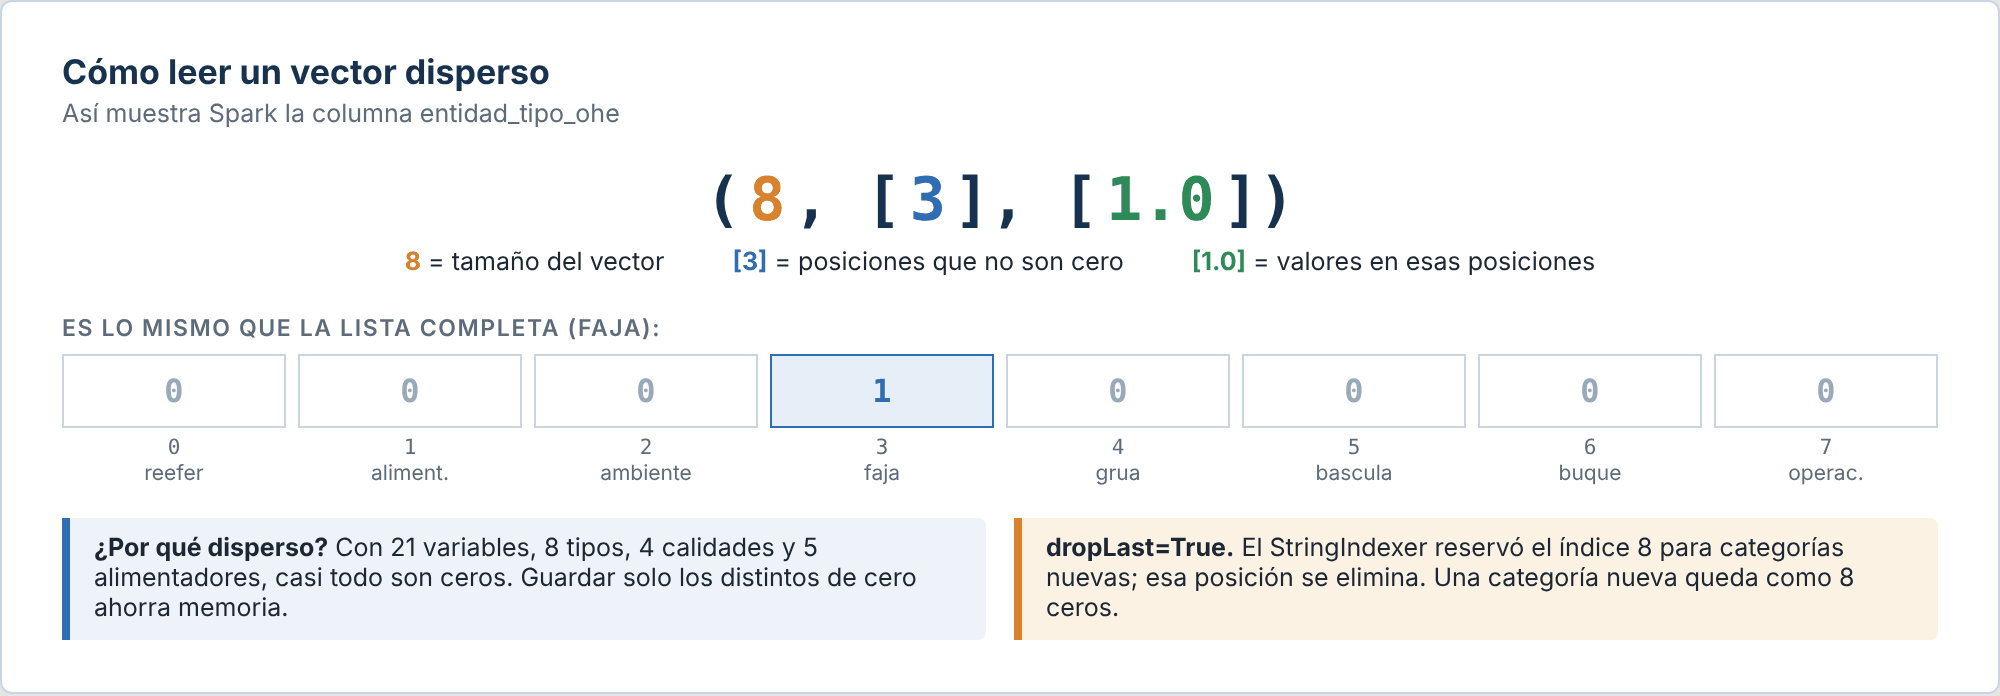

> **`dropLast=True`** elimina la última posición, que corresponde a la categoría **desconocida**
> reservada por el `StringIndexer`. Así, una categoría nueva queda como “todo ceros”.

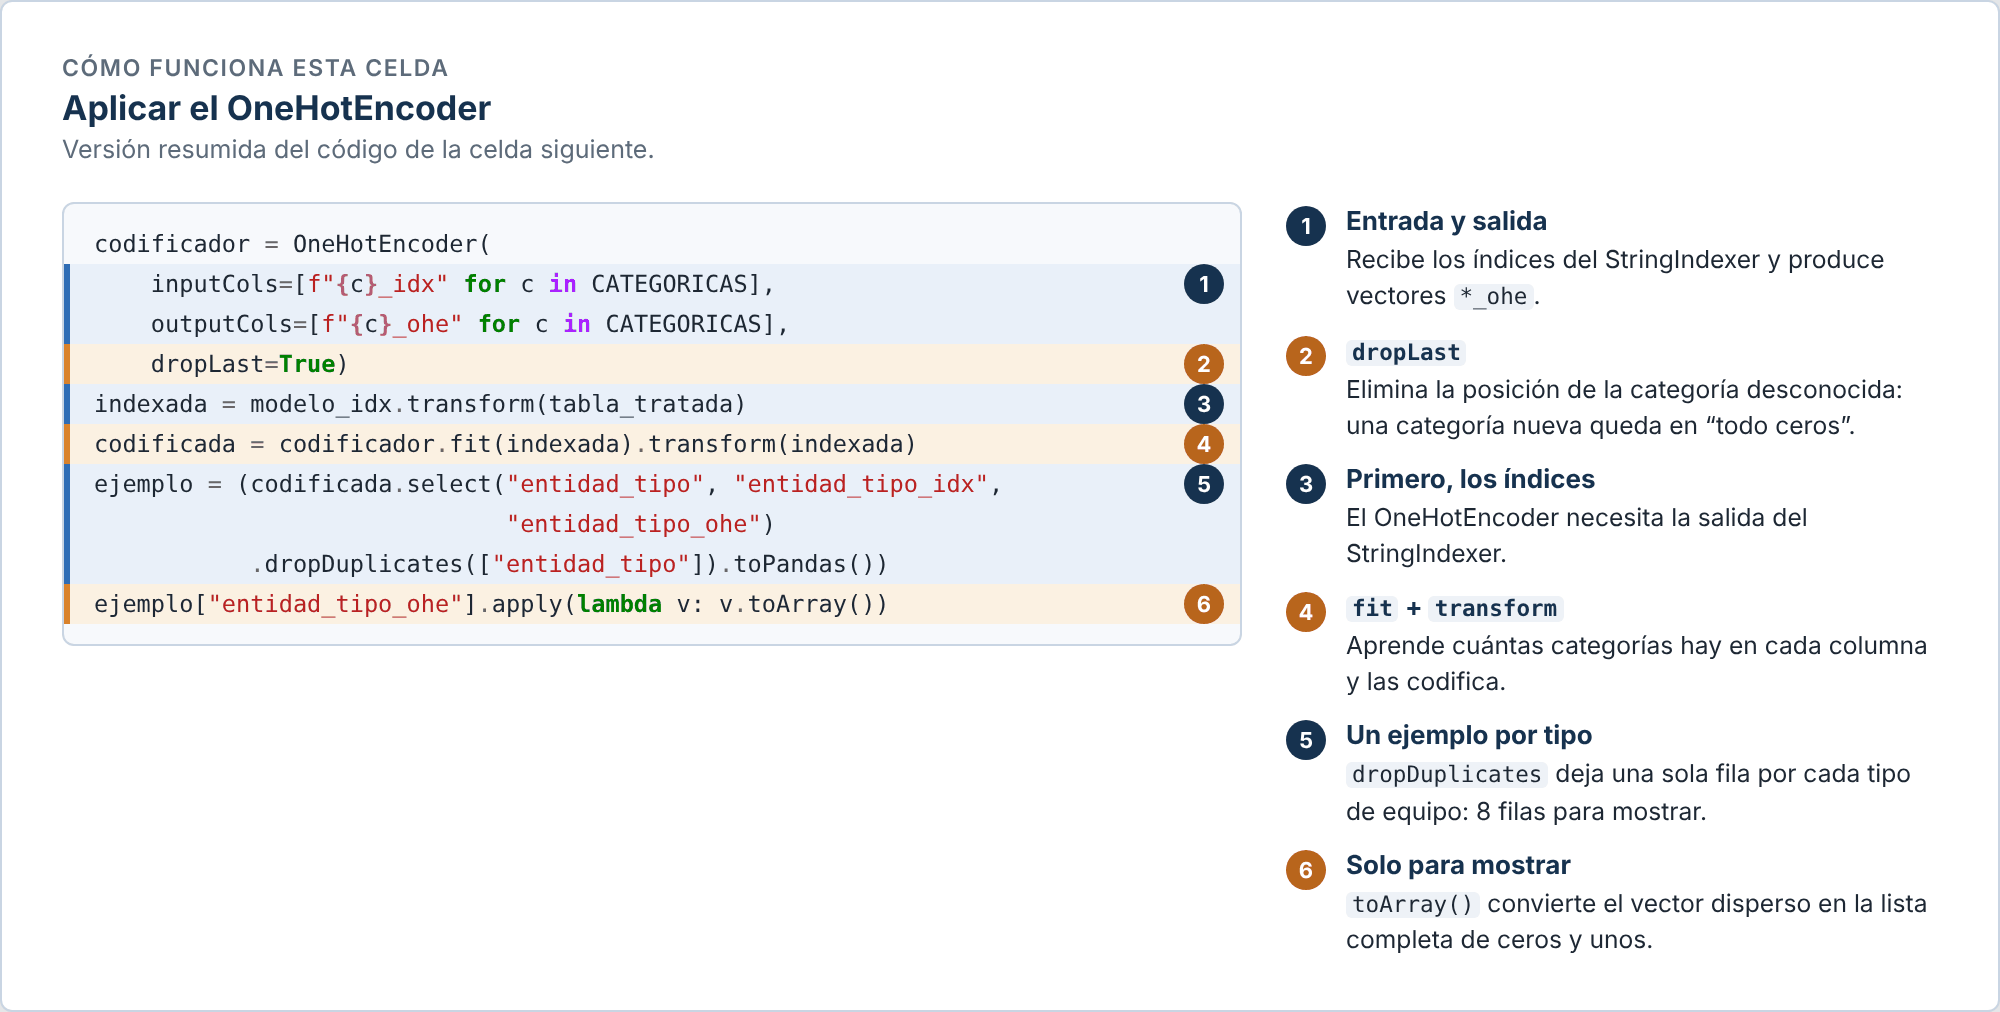

In [17]:
codificador = OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORICAS],
                            outputCols=[f"{c}_ohe" for c in CATEGORICAS],
                            dropLast=True)

indexada = modelo_idx.transform(tabla_tratada)
codificada = codificador.fit(indexada).transform(indexada)

ejemplo = (codificada.select("entidad_tipo", "entidad_tipo_idx", "entidad_tipo_ohe")
           .dropDuplicates(["entidad_tipo"]).orderBy("entidad_tipo_idx").toPandas())
ejemplo["entidad_tipo_ohe (disperso)"] = ejemplo["entidad_tipo_ohe"].astype(str)
ejemplo["entidad_tipo_ohe (completo)"] = ejemplo["entidad_tipo_ohe"].apply(
    lambda v: "[" + ", ".join(str(int(x)) for x in v.toArray()) + "]")
display(ejemplo.drop(columns="entidad_tipo_ohe").set_index("entidad_tipo"))

,entidad_tipo_idx,entidad_tipo_ohe (disperso),entidad_tipo_ohe (completo)
entidad_tipo,,,
reefer,0.0,"(8,[0],[1.0])","[1, 0, 0, 0, 0, 0, 0, 0]"
alimentador,1.0,"(8,[1],[1.0])","[0, 1, 0, 0, 0, 0, 0, 0]"
ambiente,2.0,"(8,[2],[1.0])","[0, 0, 1, 0, 0, 0, 0, 0]"
faja,3.0,"(8,[3],[1.0])","[0, 0, 0, 1, 0, 0, 0, 0]"
grua,4.0,"(8,[4],[1.0])","[0, 0, 0, 0, 1, 0, 0, 0]"
bascula,5.0,"(8,[5],[1.0])","[0, 0, 0, 0, 0, 1, 0, 0]"
buque,6.0,"(8,[6],[1.0])","[0, 0, 0, 0, 0, 0, 1, 0]"
operacion,7.0,"(8,[7],[1.0])","[0, 0, 0, 0, 0, 0, 0, 1]"


---
## Bloque 8 · Poner todo en la misma escala

> **Objetivo.** Que ninguna característica “grite más fuerte” que otra solo por tener números grandes.

> **Concepto clave (analogía de la balanza).** Si comparas dos productos por precio (en pesos, miles)
> y por peso (en kilos, decenas), el precio dominará cualquier cálculo de distancia aunque no sea más
> importante. Muchos algoritmos (regresión logística, K-means, SVM) sufren exactamente eso.

Mira la diferencia entre el promedio **crudo** (`prom`) y nuestra versión **relativa** (`z_prom`):

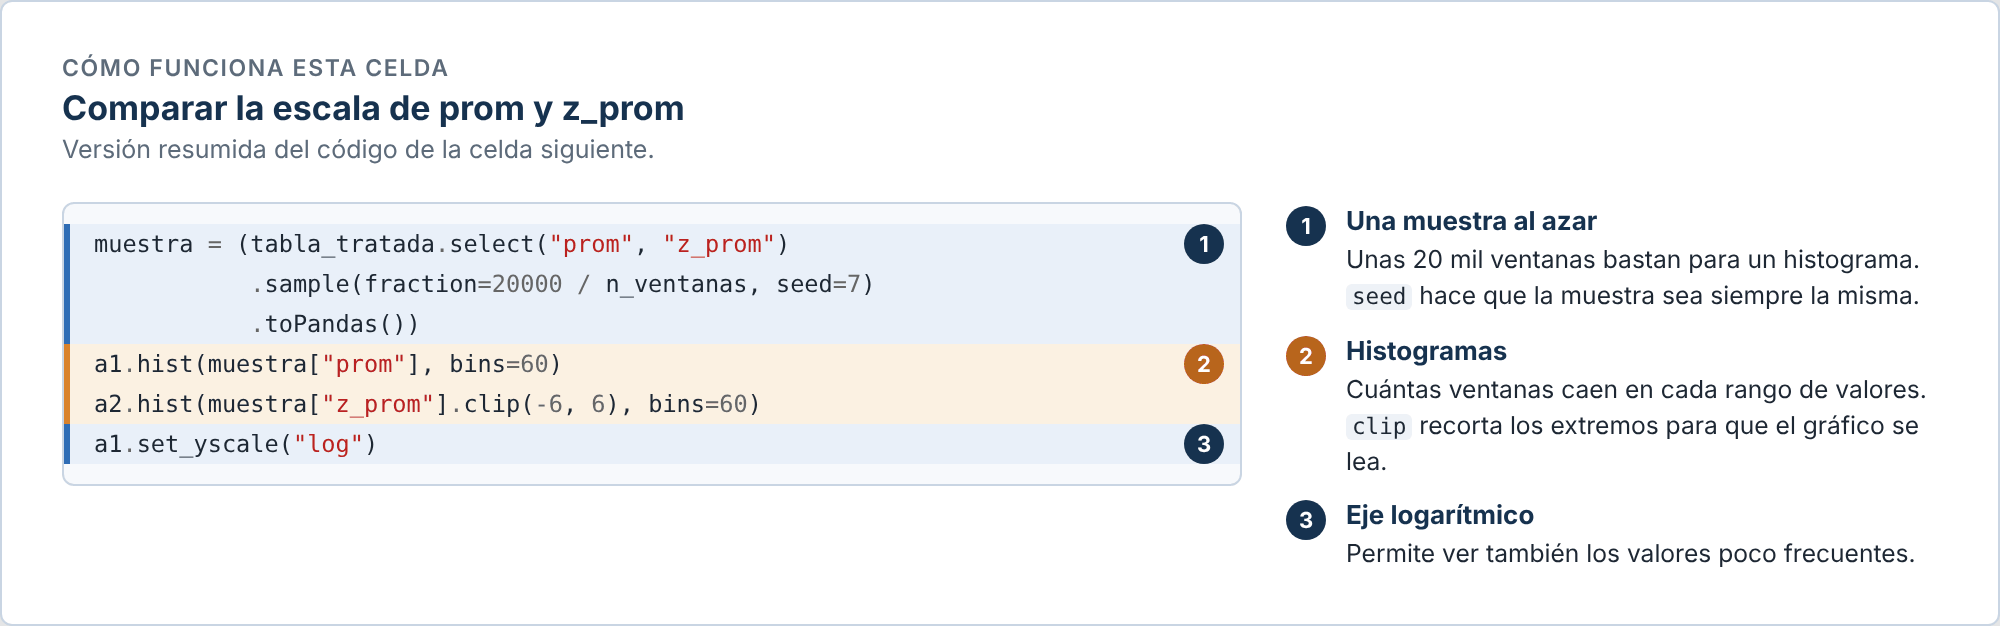

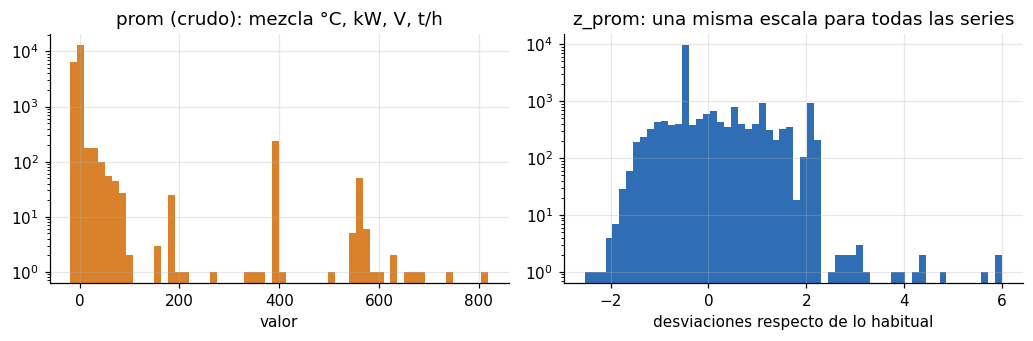

In [18]:
muestra = (tabla_tratada.select("prom", "z_prom")
           .sample(fraction=min(1.0, 20000 / n_ventanas), seed=7).toPandas().dropna())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.2))
a1.hist(muestra["prom"], bins=60, color=NARANJA)
a1.set_yscale("log"); a1.set_title("prom (crudo): mezcla °C, kW, V, t/h")
a1.set_xlabel("valor")
a2.hist(muestra["z_prom"].clip(-6, 6), bins=60, color=AZUL)
a2.set_yscale("log"); a2.set_title("z_prom: una misma escala para todas las series")
a2.set_xlabel("desviaciones respecto de lo habitual")
plt.tight_layout(); plt.show()

### ¿Qué se escala y qué no?

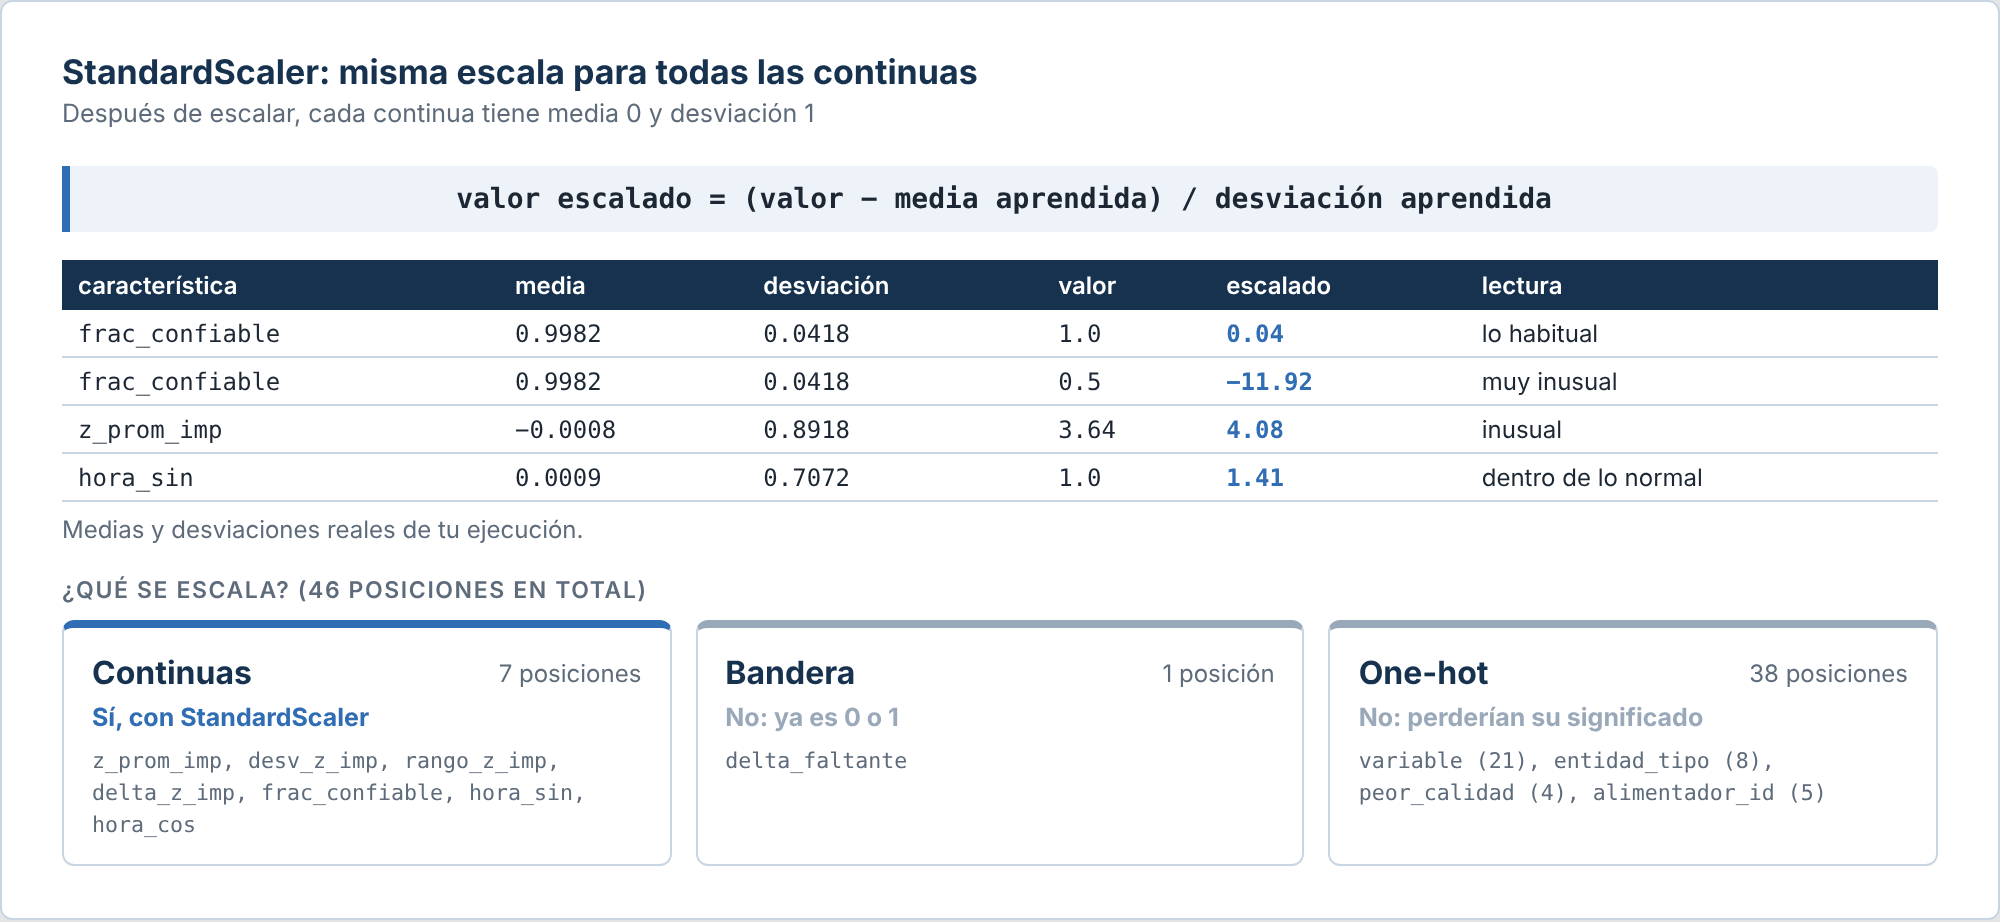

`StandardScaler` hace que cada continua quede con **promedio 0** y **desviación 1**. Para eso aprende el
promedio y la desviación de los datos: es otro **Estimator**.

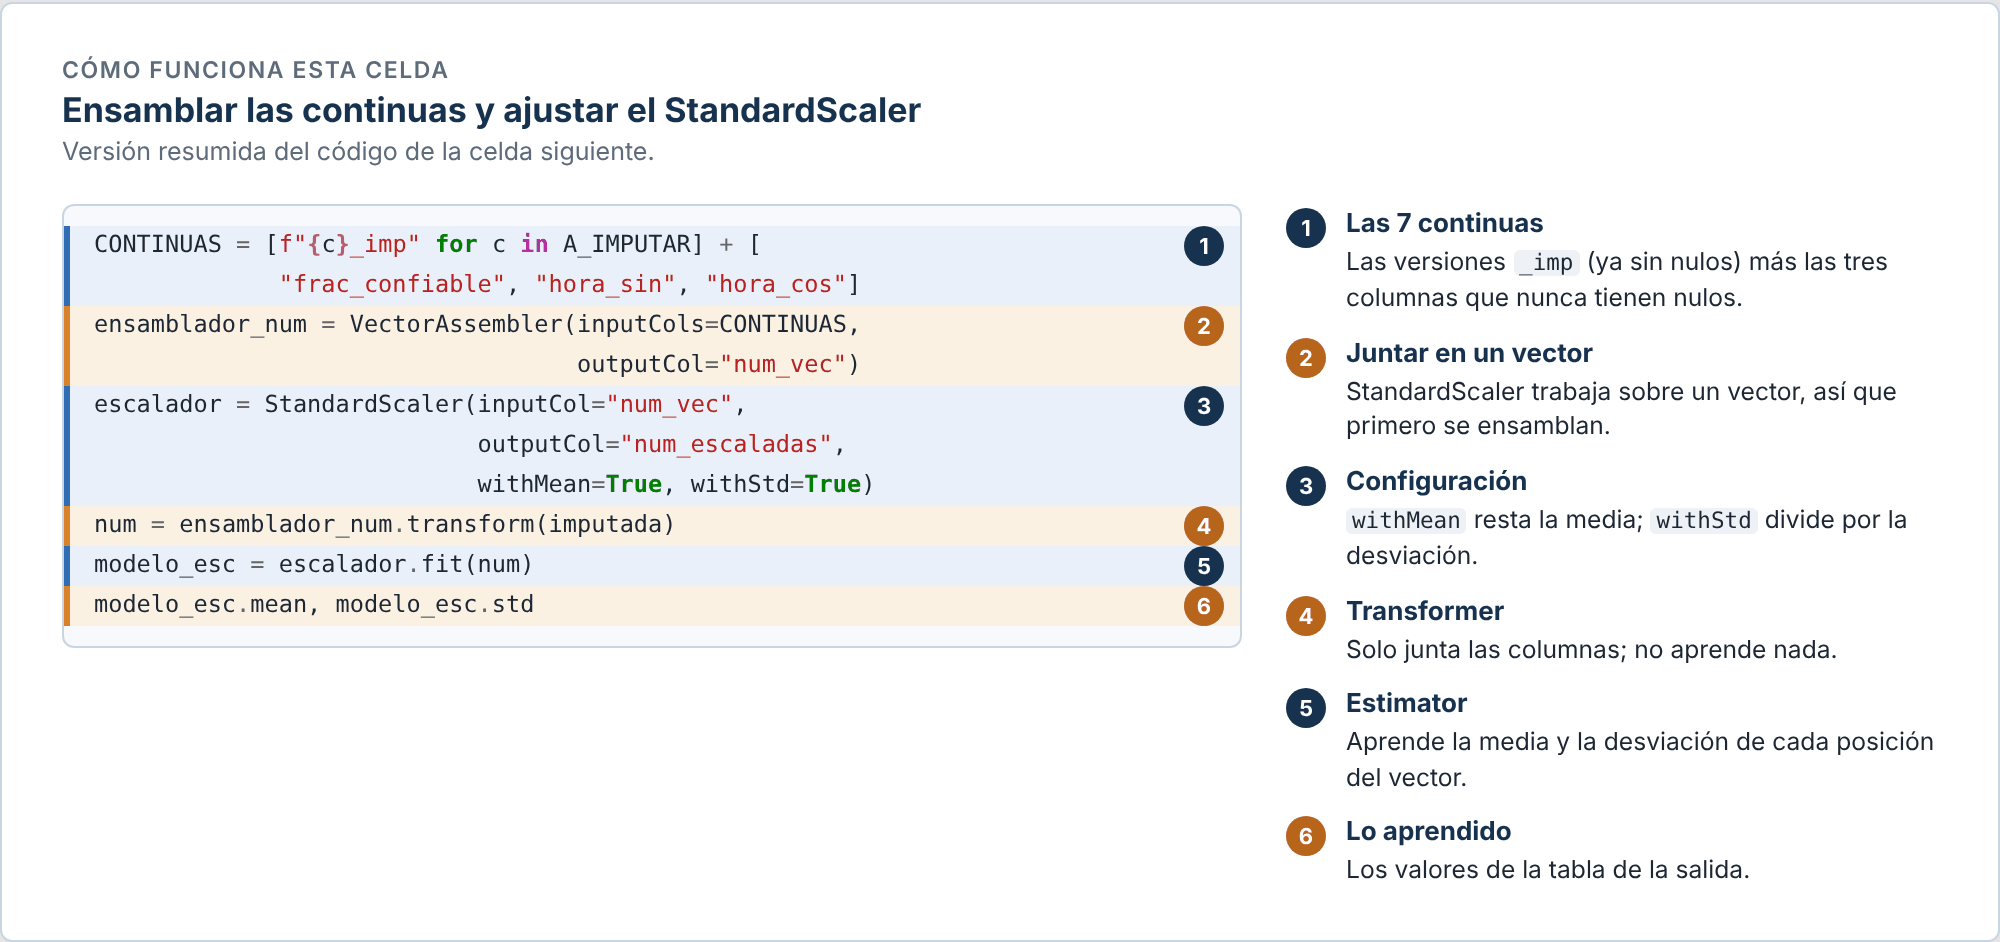

In [19]:
CONTINUAS = [f"{c}_imp" for c in A_IMPUTAR] + ["frac_confiable", "hora_sin", "hora_cos"]

ensamblador_num = VectorAssembler(inputCols=CONTINUAS, outputCol="num_vec")
escalador = StandardScaler(inputCol="num_vec", outputCol="num_escaladas",
                           withMean=True, withStd=True)

num = ensamblador_num.transform(imputada)
modelo_esc = escalador.fit(num)                    # aprende promedio y desviación

display(pd.DataFrame({"promedio aprendido": modelo_esc.mean.toArray(),
                      "desviación aprendida": modelo_esc.std.toArray()},
                     index=CONTINUAS).round(4))
caja("Después de escalar, cada una de estas 7 columnas tendrá promedio 0 y desviación 1.", "info")

,promedio aprendido,desviación aprendida
z_prom_imp,-0.0015,0.8920
desv_z_imp,0.2858,0.4128
rango_z_imp,0.6478,0.8937
delta_z_imp,-0.0002,0.8410
frac_confiable,0.9982,0.0418
hora_sin,0.0009,0.7072
hora_cos,0.0003,0.7070


---
## Bloque 9 · Unir todo en un `Pipeline`

> **Objetivo.** Encadenar todas las piezas en **una sola receta**, siempre en el mismo orden.

> **Concepto clave (analogía de la receta).** Hasta ahora cocinamos “a mano”, paso a paso.
> Funciona, pero es fácil olvidar un paso o cambiar el orden. Un **Pipeline** es la receta escrita:
> se ejecuta igual cada vez.

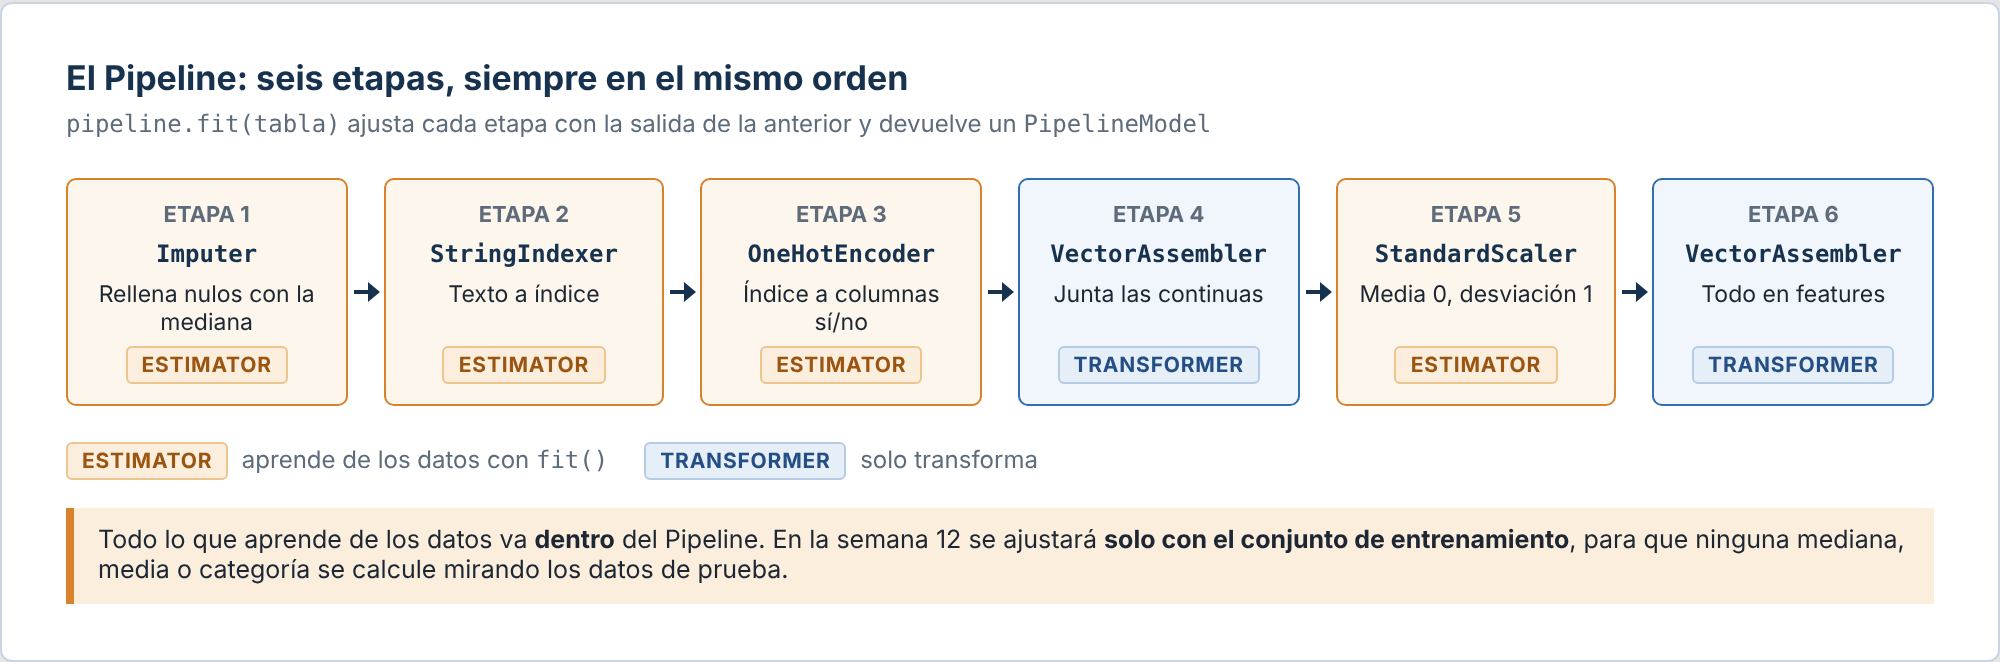

> **Atención.** Por eso dejamos el `Imputer` dentro del pipeline. Todo lo que **aprende de los datos** va
> dentro. La próxima semana separaremos datos de **entrenamiento** y de **prueba**, y el pipeline se
> ajustará **solo con entrenamiento**. Si la mediana se calculara mirando los datos de prueba,
> ¡sería fuga de información!

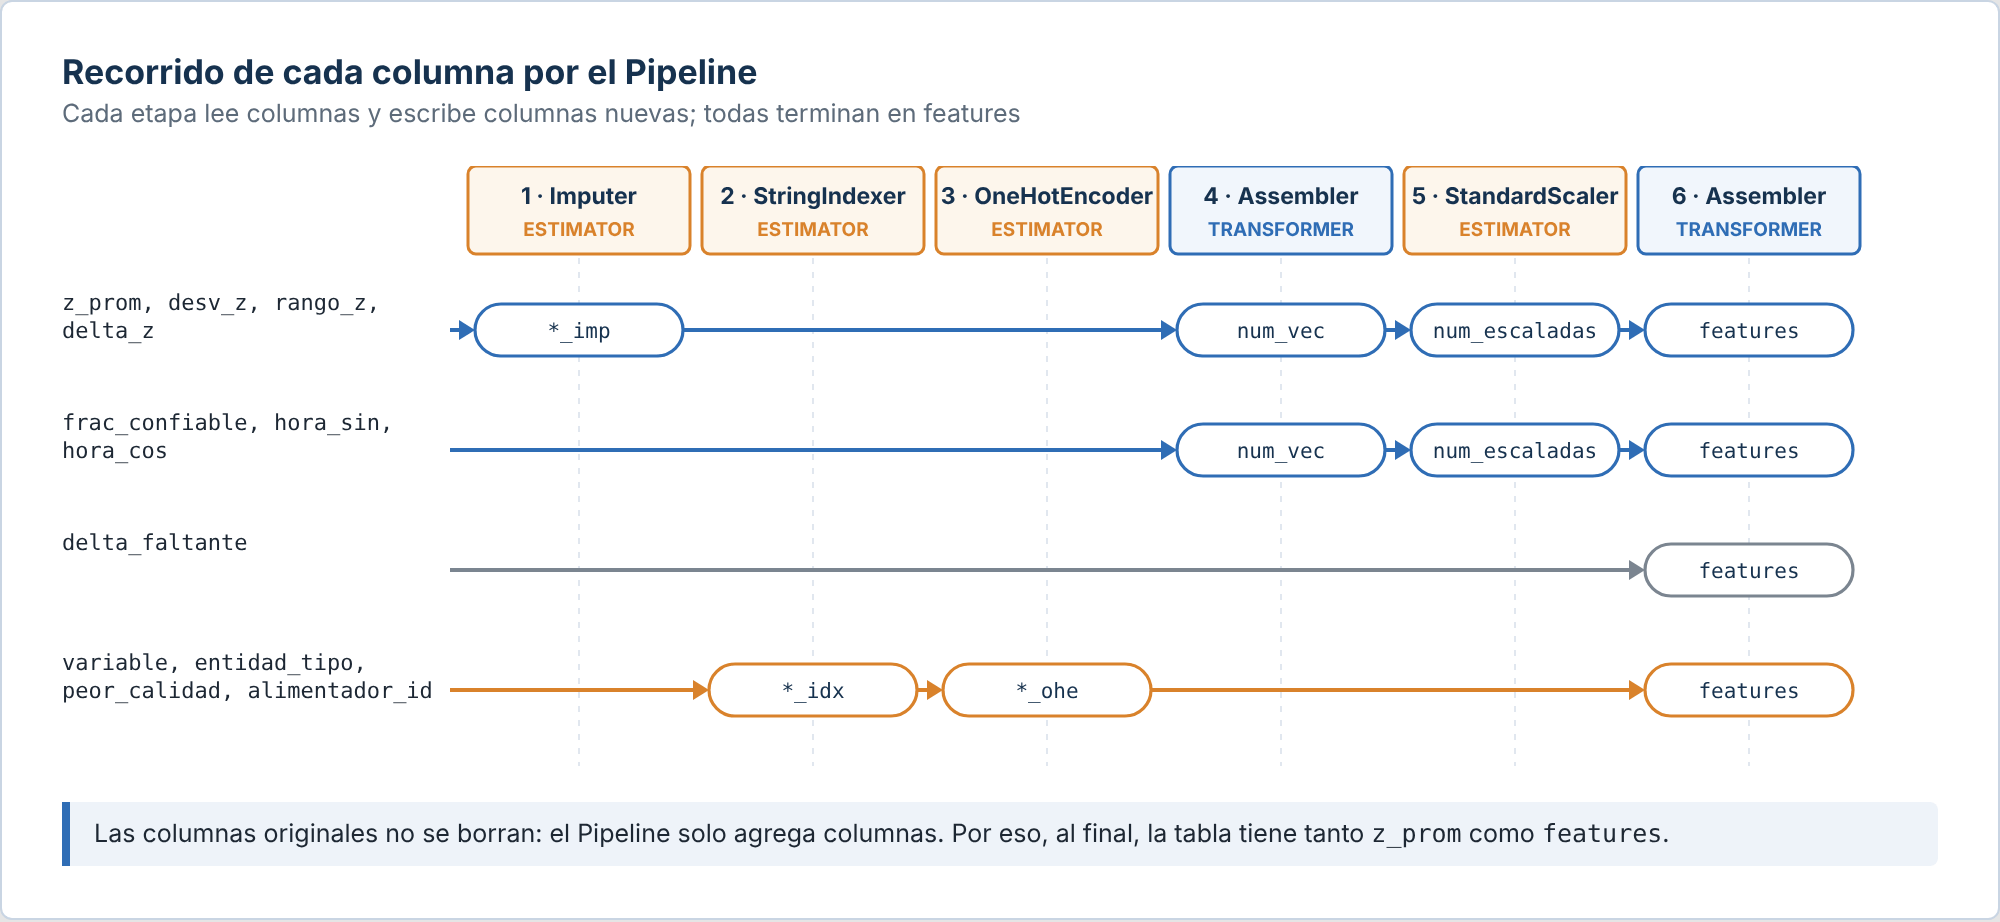

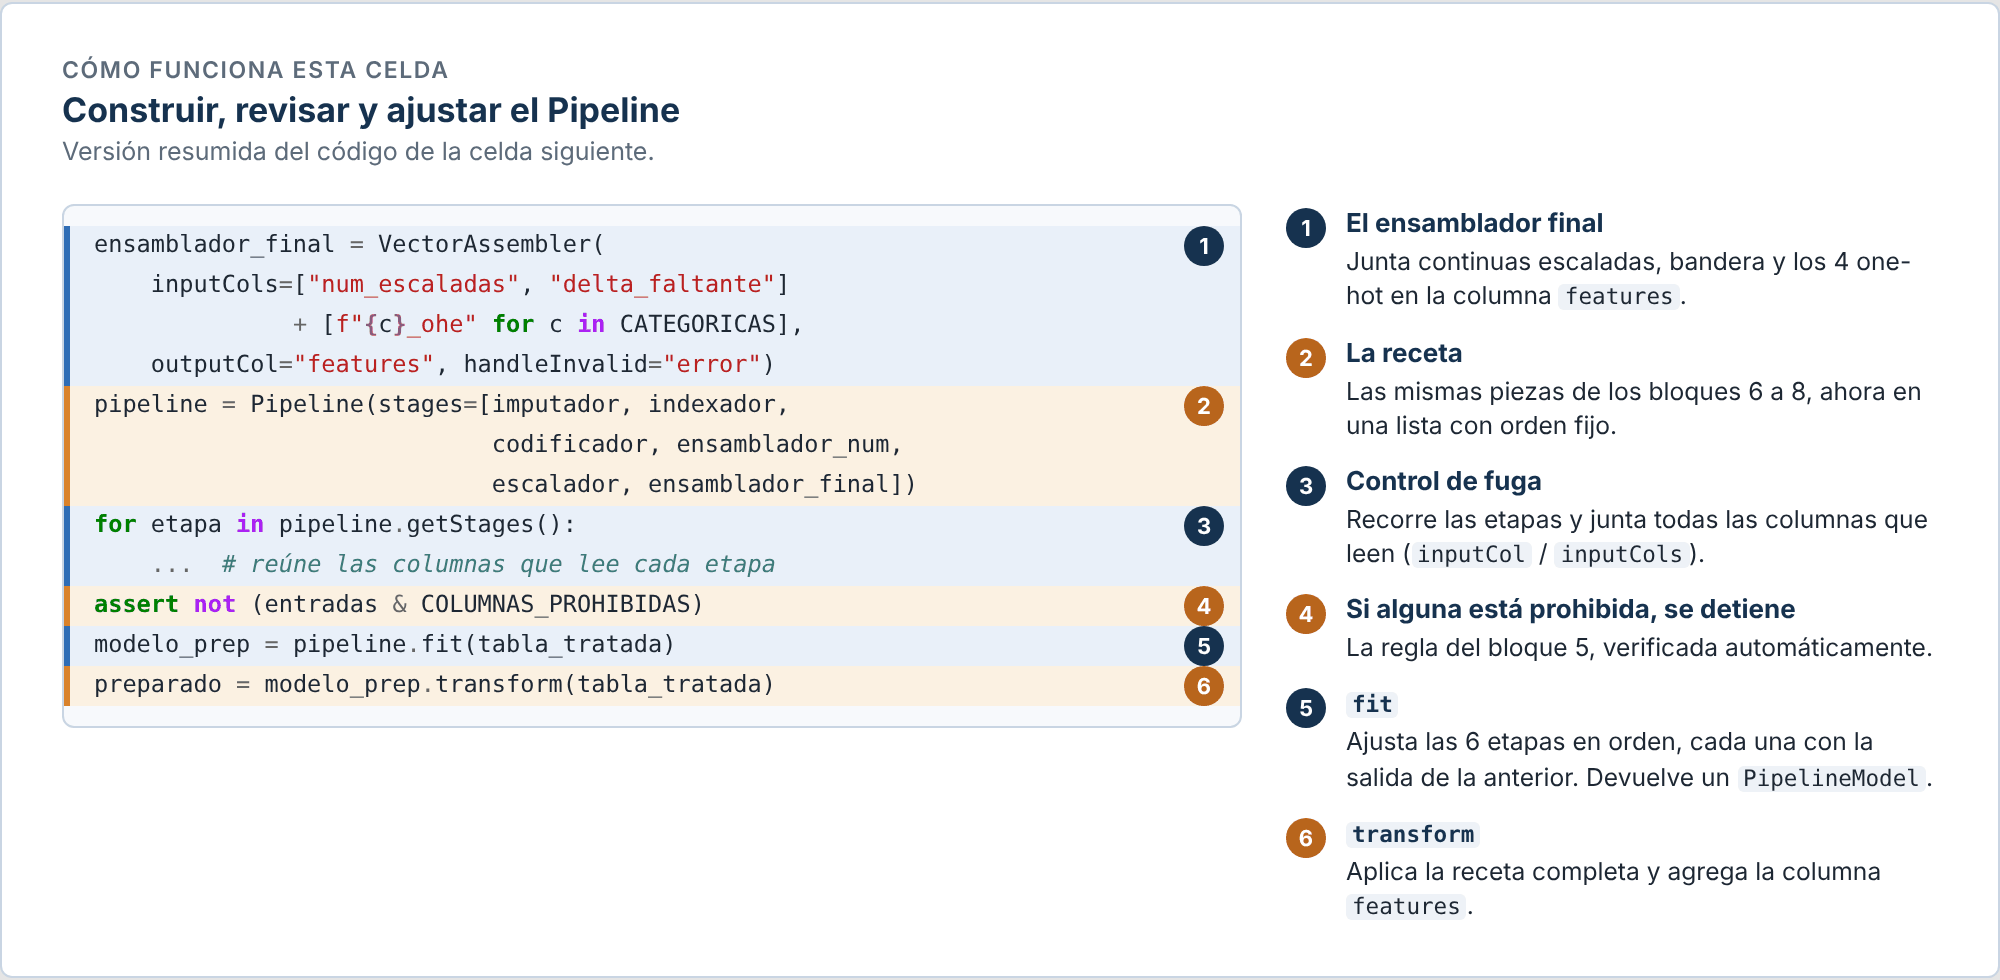

In [20]:
ensamblador_final = VectorAssembler(
    inputCols=["num_escaladas", "delta_faltante"] + [f"{c}_ohe" for c in CATEGORICAS],
    outputCol="features",
    handleInvalid="error")          # si se cuela un nulo, queremos enterarnos

pipeline = Pipeline(stages=[
    imputador,          # 1. nulos -> mediana
    indexador,          # 2. texto -> número
    codificador,        # 3. número -> sí/no
    ensamblador_num,    # 4. continuas -> un vector
    escalador,          # 5. misma escala
    ensamblador_final,  # 6. todo -> "features"
])

# --- Red de seguridad contra la fuga: ninguna etapa puede leer una columna prohibida ---
entradas = set()
for etapa in pipeline.getStages():
    for p in ("inputCol", "inputCols"):
        if etapa.hasParam(p) and etapa.isDefined(p):
            v = etapa.getOrDefault(p)
            entradas |= set(v if isinstance(v, list) else [v])
assert not (entradas & COLUMNAS_PROHIBIDAS), f"Fuga de información: {entradas & COLUMNAS_PROHIBIDAS}"
caja("Ninguna etapa del pipeline usa columnas prohibidas.", "ok", "Control de fuga superado")

ini = time.time()
modelo_prep = pipeline.fit(tabla_tratada)          # ajusta las 6 etapas en orden
preparado = modelo_prep.transform(tabla_tratada)   # aplica la receta completa
caja(f"Pipeline ajustado en <b>{time.time() - ini:.1f} s</b>: "
     + " ► ".join(type(s).__name__ for s in modelo_prep.stages), "info")

tabla(preparado, 3, ["entidad_id", "variable", "ventana_inicio", "features", "etiqueta"])

,entidad_id,variable,ventana_inicio,features,etiqueta
0,reefer_18,potencia_kw,2026-01-12 00:00:00,"(-0.5266546518896089, -0.6924236953780883, -0.7248642623...",0
1,reefer_18,potencia_kw,2026-01-12 00:05:00,"(-0.5266546518896089, -0.6924236953780883, -0.7248642623...",0
2,reefer_18,potencia_kw,2026-01-12 00:10:00,"(0.6361523508409217, 2.748417085546798, 2.17669616404099...",0


### 9.1 · ¿Qué hay dentro del vector `features`?

Un vector es solo una lista de números. Para saber **qué significa cada posición**, Spark guarda los
nombres en los **metadatos** de la columna. Este es el mapa completo, con los valores reales de una fila:

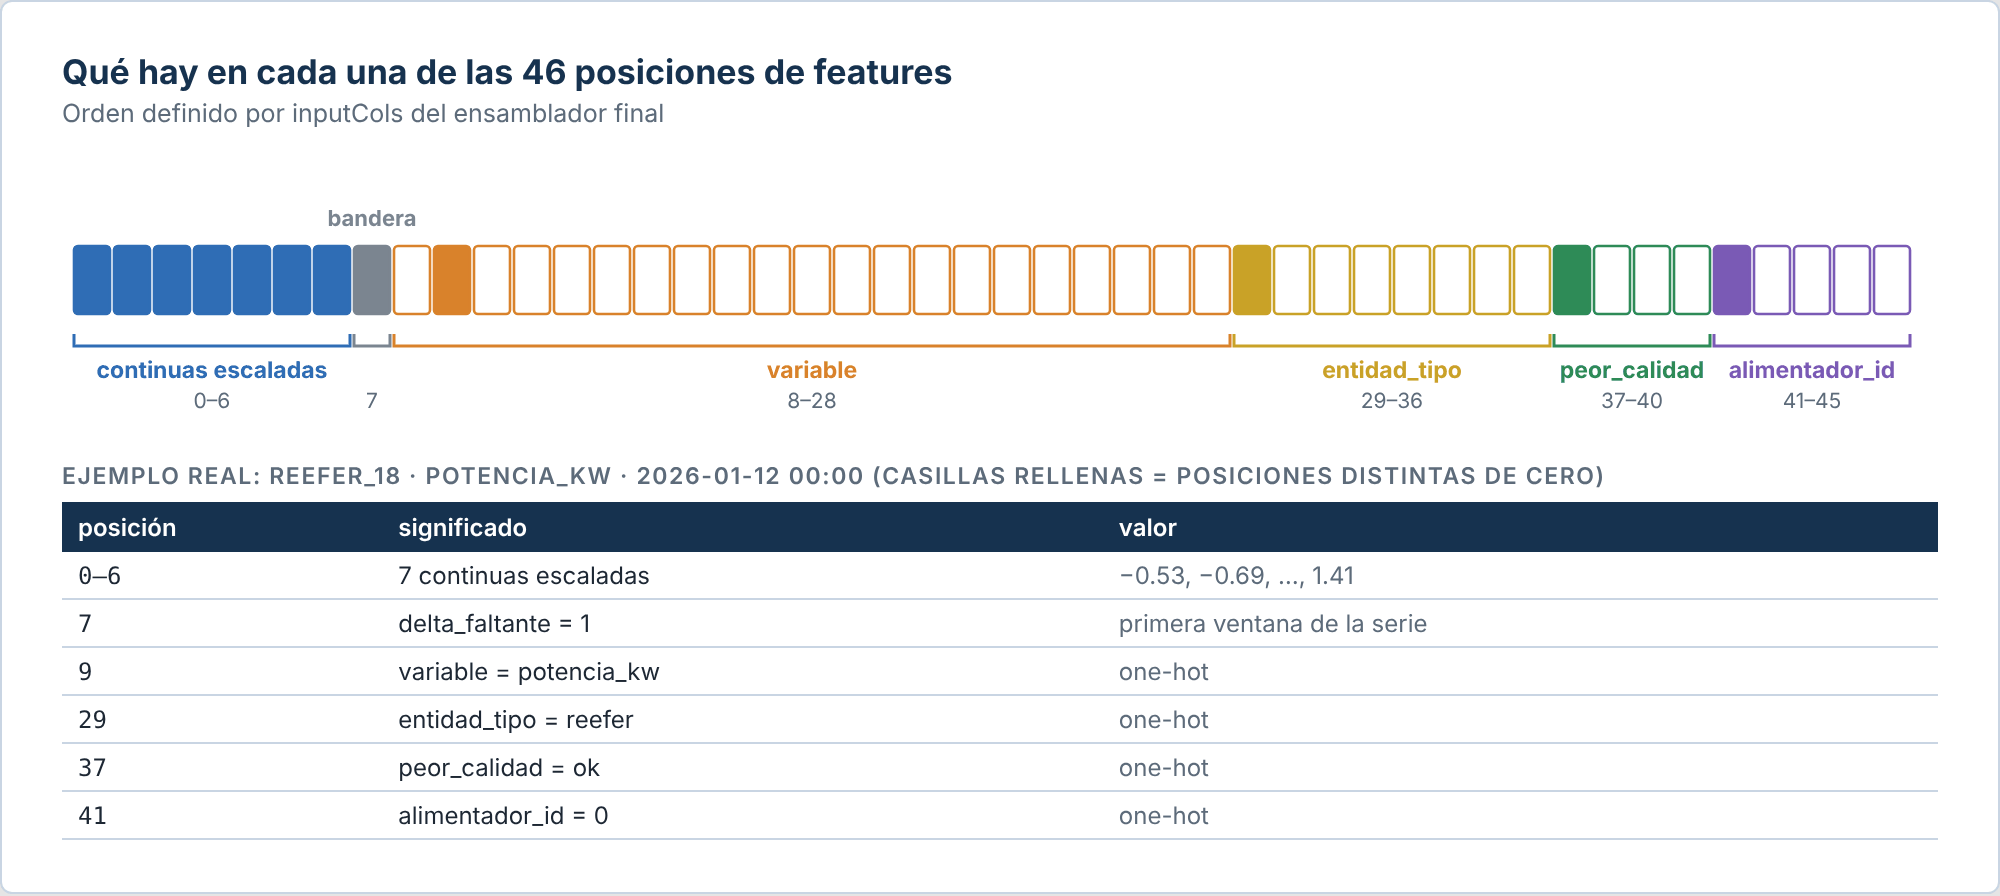

La celda siguiente lee esos nombres desde los metadatos:

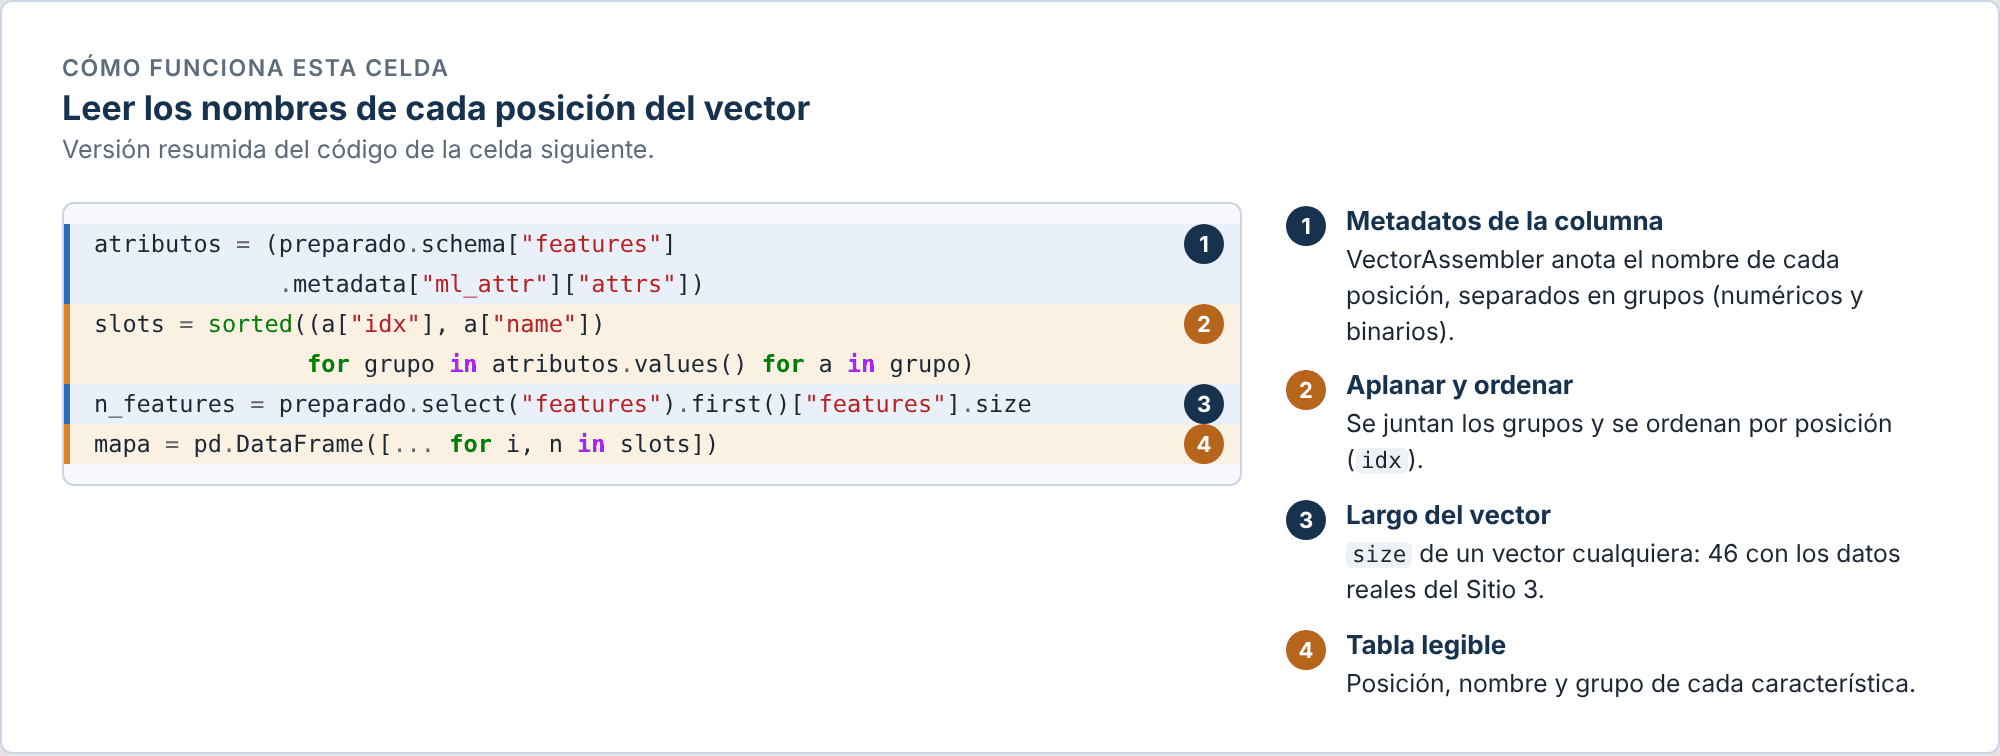

In [21]:
atributos = preparado.schema["features"].metadata["ml_attr"]["attrs"]
slots = sorted((a["idx"], a["name"]) for grupo in atributos.values() for a in grupo)
n_features = preparado.select("features").first()["features"].size

nombres_num = {f"num_escaladas_{i}": c for i, c in enumerate(CONTINUAS)}
def grupo(nombre):
    if nombre in nombres_num:     return "Continua (escalada)"
    if nombre == "delta_faltante": return "Bandera"
    return "One-hot: " + nombre.split("_ohe_")[0]

mapa = pd.DataFrame([(i, nombres_num.get(n, n), grupo(n)) for i, n in slots],
                    columns=["posición", "característica", "grupo"])
resumen = mapa.groupby("grupo", sort=False).size().rename("posiciones").to_frame()

tarjetas({"posiciones en 'features'": n_features,
          "continuas": len(CONTINUAS),
          "one-hot": int((mapa["grupo"].str.startswith("One-hot")).sum())})
display(resumen)

with pd.option_context("display.max_rows", 100):
    display(mapa.set_index("posición"))

,posiciones
grupo,
Continua (escalada),7
Bandera,1
One-hot: variable,21
One-hot: entidad_tipo,8
One-hot: peor_calidad,4
One-hot: alimentador_id,5


,característica,grupo
posición,,
0,z_prom_imp,Continua (escalada)
1,desv_z_imp,Continua (escalada)
2,rango_z_imp,Continua (escalada)
3,delta_z_imp,Continua (escalada)
4,frac_confiable,Continua (escalada)
5,hora_sin,Continua (escalada)
6,hora_cos,Continua (escalada)
7,delta_faltante,Bandera
8,variable_ohe_temperatura_c,One-hot: variable


---
## Bloque 10 · Revisión final antes de entregar

> **Objetivo.** Dos chequeos que no cambian la tabla, pero sí lo que haremos las próximas semanas.

### 10.1 · ¿Hay características que dicen lo mismo?

La **correlación** va de −1 a 1. Cerca de **1** significa que dos columnas suben y bajan juntas: aportan
casi la misma información.

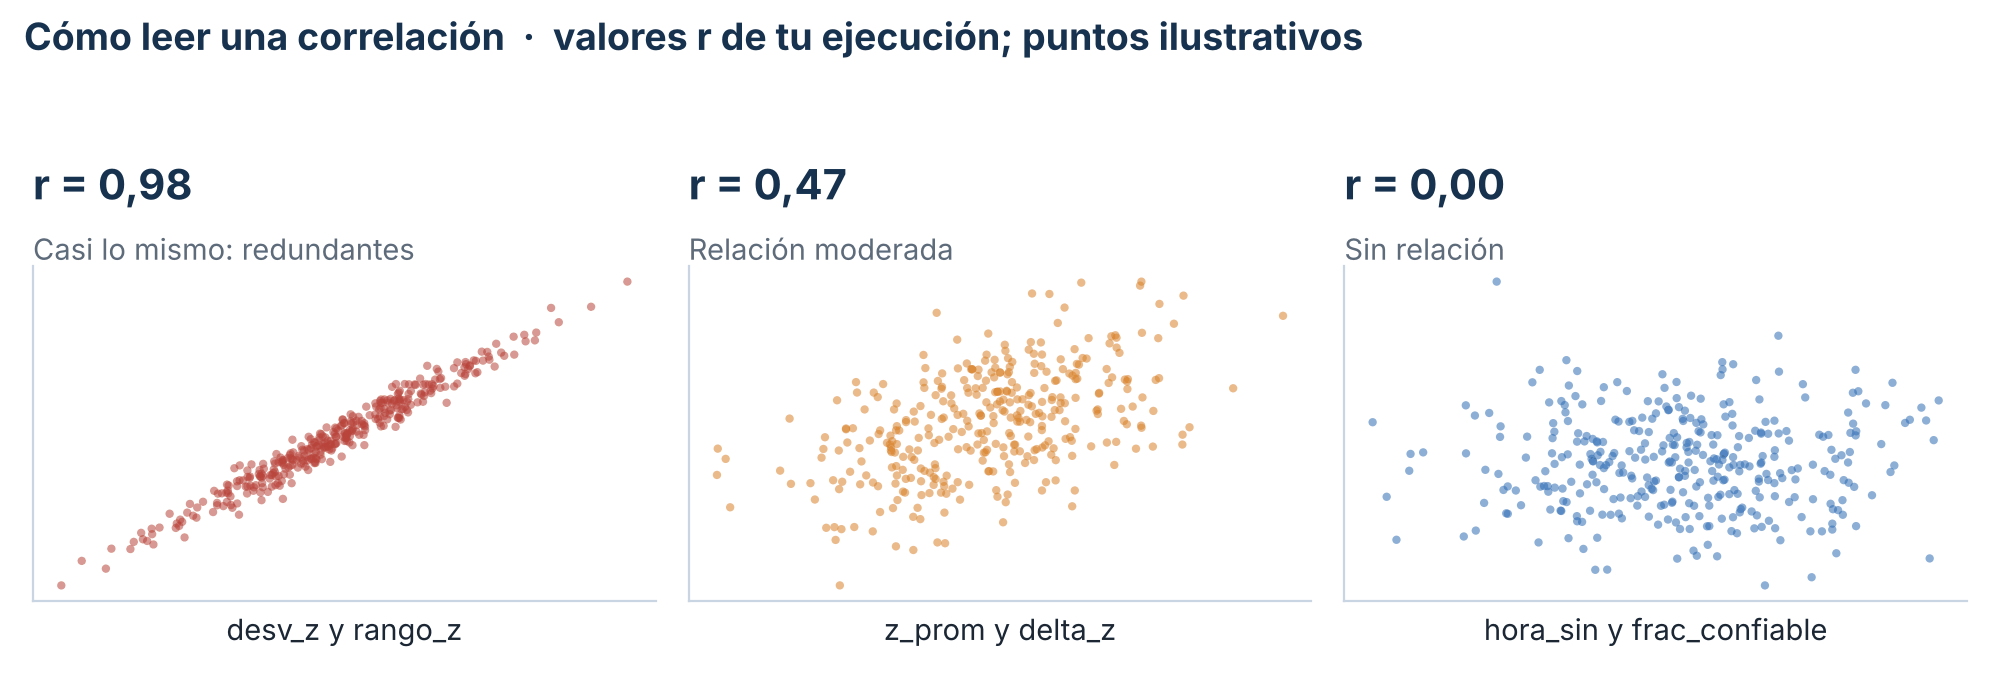

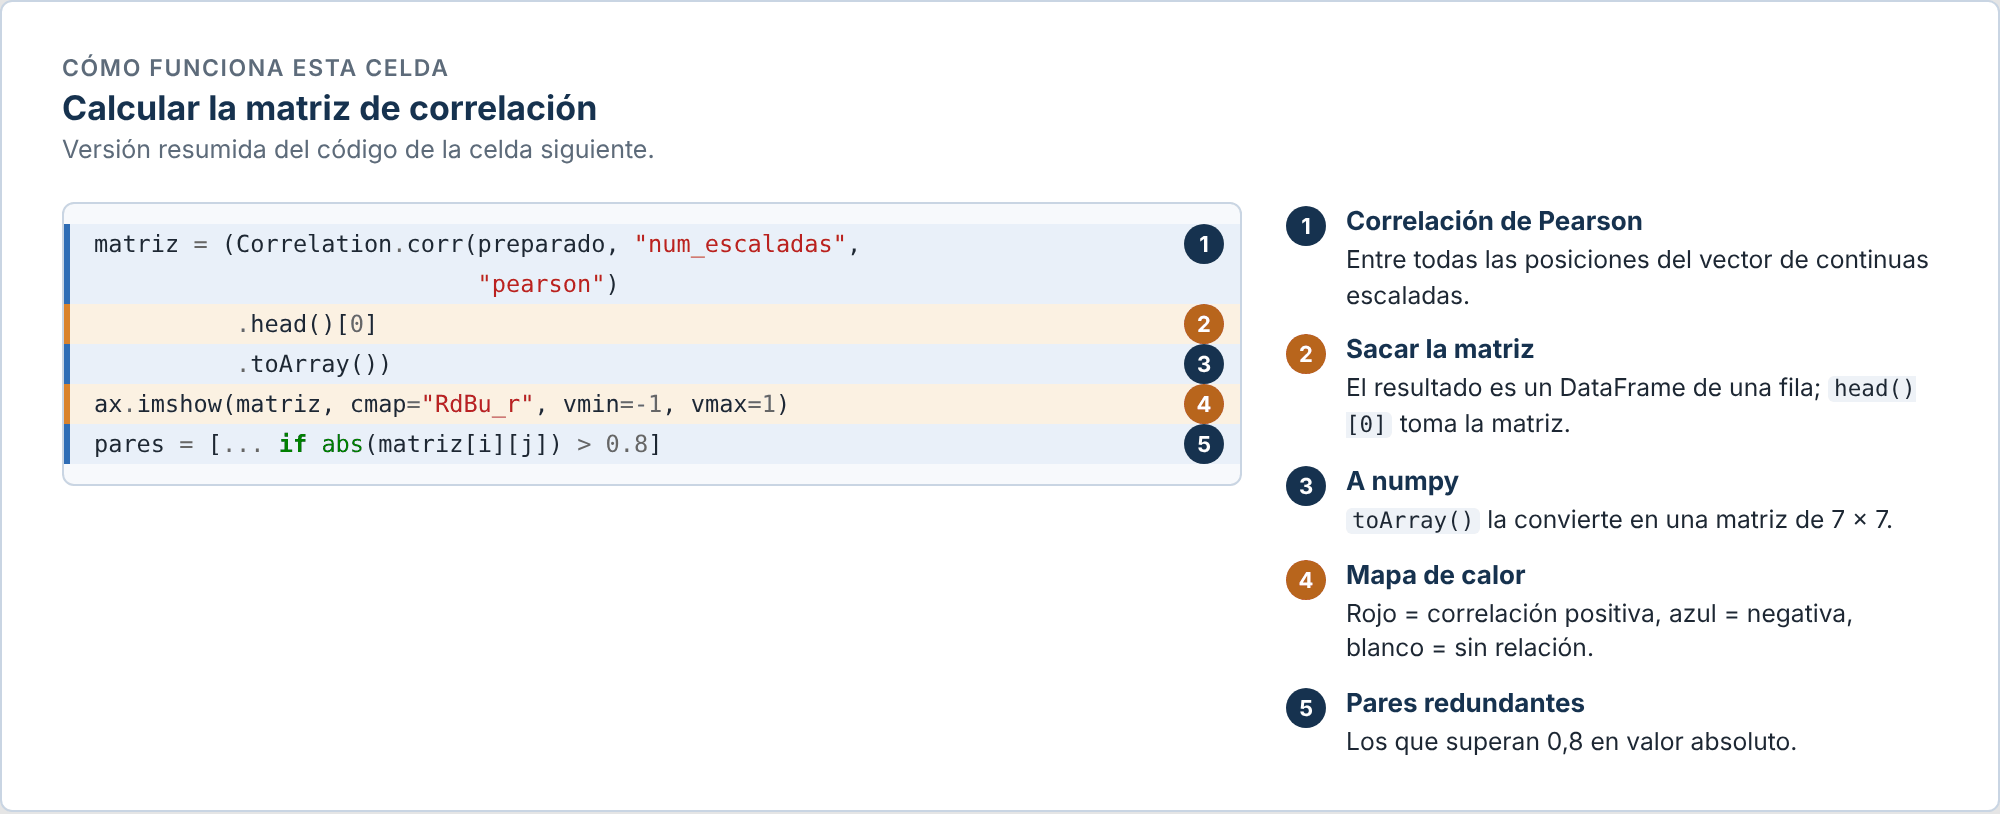

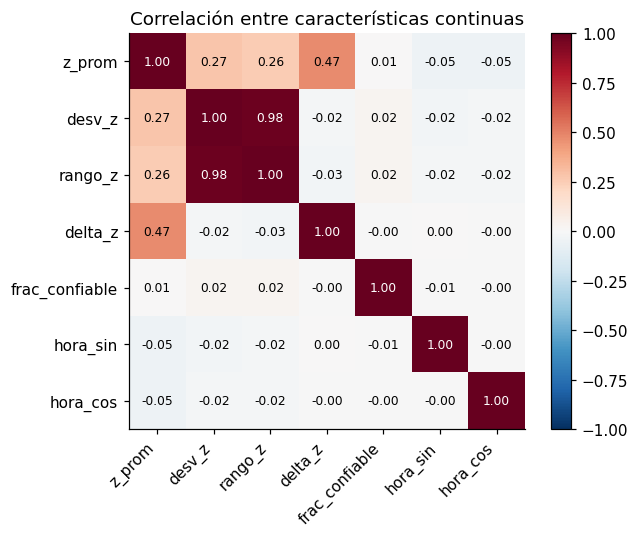

In [22]:
matriz = Correlation.corr(preparado, "num_escaladas", "pearson").head()[0].toArray()
cortos = [c.replace("_imp", "") for c in CONTINUAS]

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cortos)), cortos, rotation=45, ha="right")
ax.set_yticks(range(len(cortos)), cortos)
ax.grid(False)
for i in range(len(cortos)):
    for j in range(len(cortos)):
        ax.text(j, i, f"{matriz[i][j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(matriz[i][j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Correlación entre características continuas")
plt.tight_layout(); plt.show()

pares = [(cortos[i], cortos[j], round(float(matriz[i][j]), 2))
         for i in range(len(cortos)) for j in range(i + 1, len(cortos)) if abs(matriz[i][j]) > 0.8]
if pares:
    caja("Pares muy correlacionados (|r| &gt; 0.8): " + ", ".join(f"<b>{a}</b> y <b>{b}</b> ({r})"
         for a, b, r in pares) + ". Ambas miden cuánto oscila el sensor. Por ahora las dejamos; "
         "decidir si sobra alguna es tarea de las próximas semanas.", "warn")
else:
    caja("No hay pares con correlación mayor a 0.8.", "ok")

### 10.2 · ¿Cuántas fallas hay?

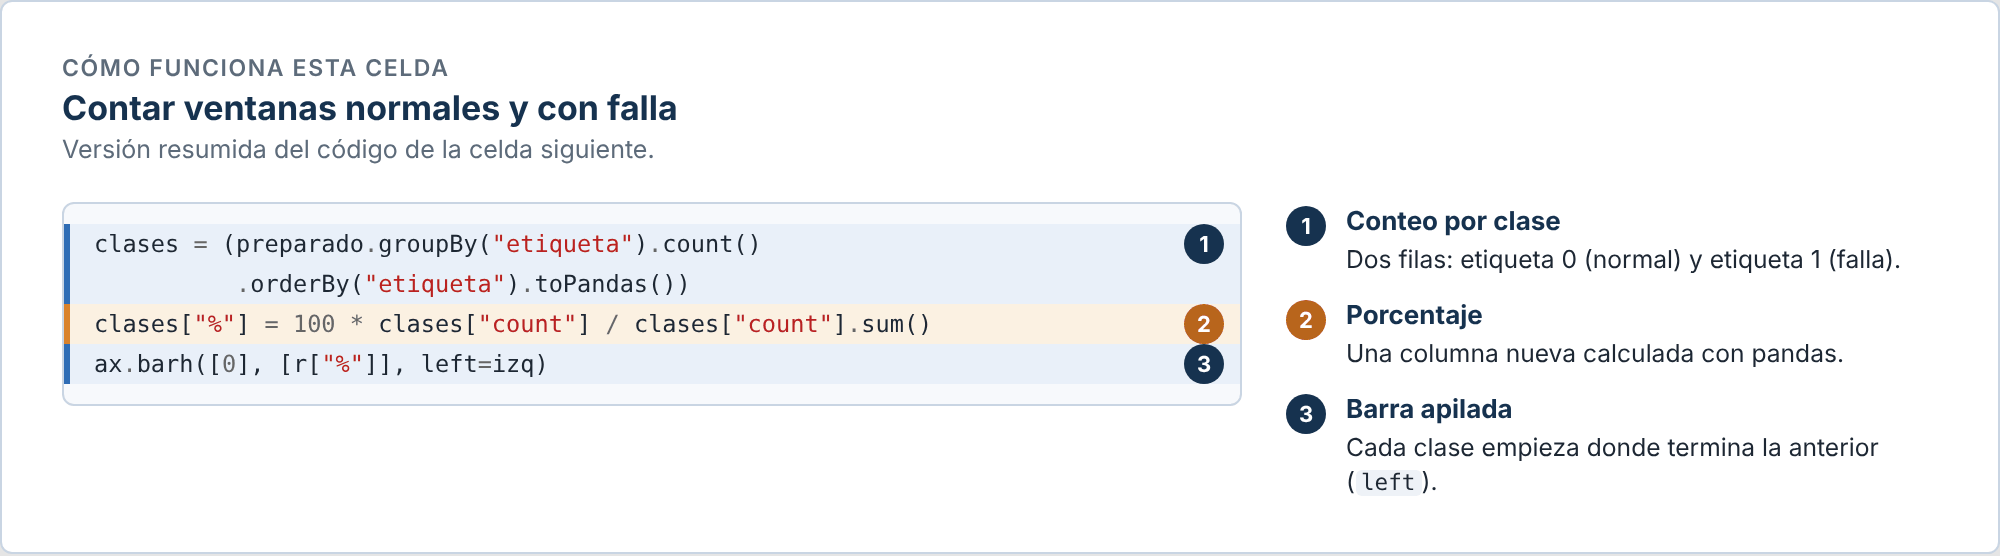

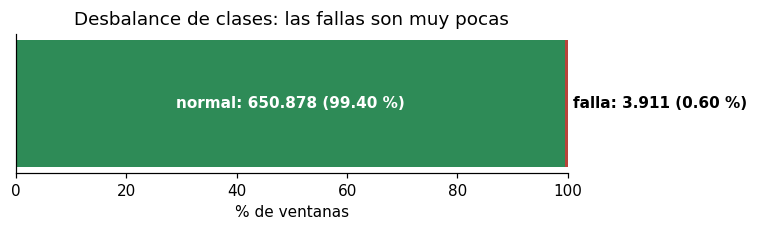

In [23]:
clases = preparado.groupBy("etiqueta").count().orderBy("etiqueta").toPandas()
clases["%"] = 100 * clases["count"] / clases["count"].sum()

fig, ax = plt.subplots(figsize=(7, 2.2))
izq = 0
for _, r in clases.iterrows():
    color = VERDE if r["etiqueta"] == 0 else ROJO
    ax.barh([0], [r["%"]], left=izq, color=color)
    ax.text(izq + r["%"] / 2 if r["%"] > 10 else izq + r["%"] + 1, 0,
            f"{'normal' if r['etiqueta'] == 0 else 'falla'}: {miles(int(r['count']))} ({r['%']:.2f} %)",
            va="center", ha="center" if r["%"] > 10 else "left",
            color="white" if r["%"] > 10 else "black", fontweight="bold")
    izq += r["%"]
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("% de ventanas")
ax.set_title("Desbalance de clases: las fallas son muy pocas")
plt.tight_layout(); plt.show()

pct_normal = float(clases.loc[clases["etiqueta"] == 0, "%"].iloc[0])
caja(f"Un “modelo” que siempre diga <i>normal</i> acertaría el <b>{pct_normal:.1f} %</b> de las veces... "
     "¡y no detectaría ni una sola falla! Por eso la próxima semana no mediremos solo el % de aciertos.",
     "warn", "Ojo con este número")

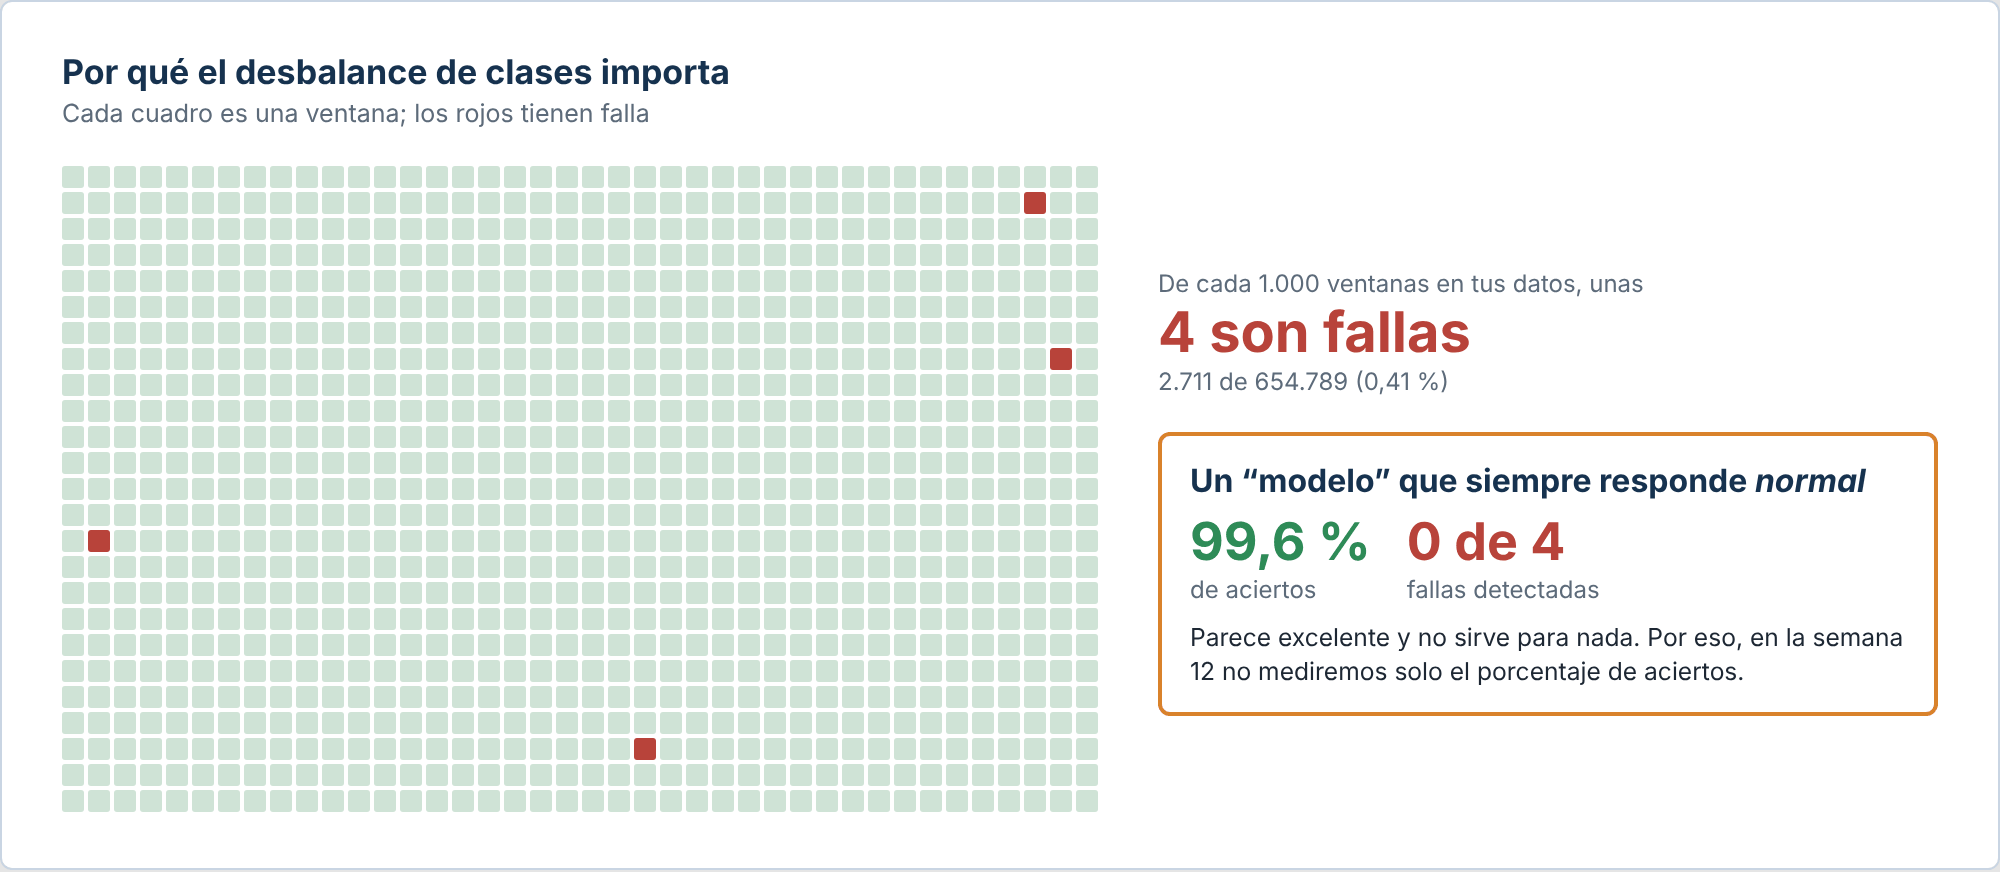

---
## Bloque 11 · Guardar para la semana 12

> **Objetivo.** Dejar todo listo para entrenar el modelo la próxima semana.

Guardamos **dos cosas** distintas, y dejamos una fuera a propósito:

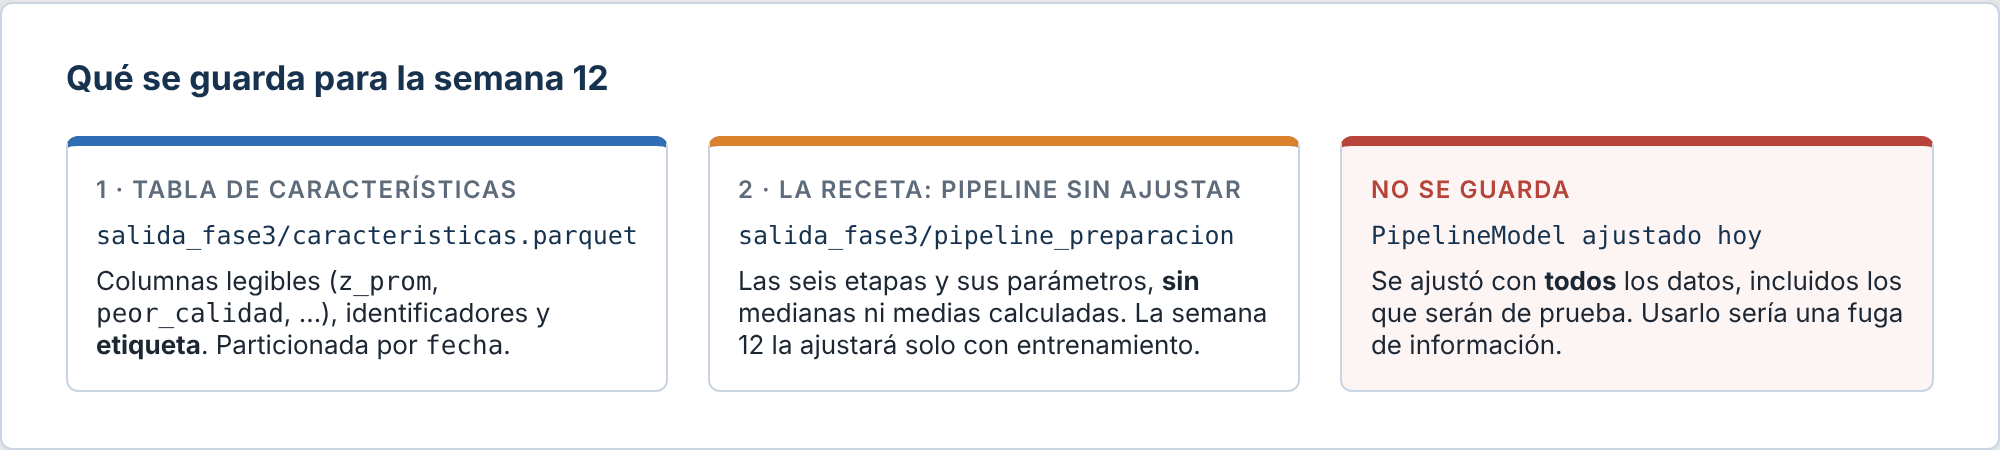

> **¿Por qué no guardamos el pipeline ya ajustado?** Porque sus medianas, promedios y categorías se
> calcularon con **todos** los datos, incluidos los que la próxima semana serán de prueba. Usarlo sería
> meter la fuga de información por la puerta de atrás.

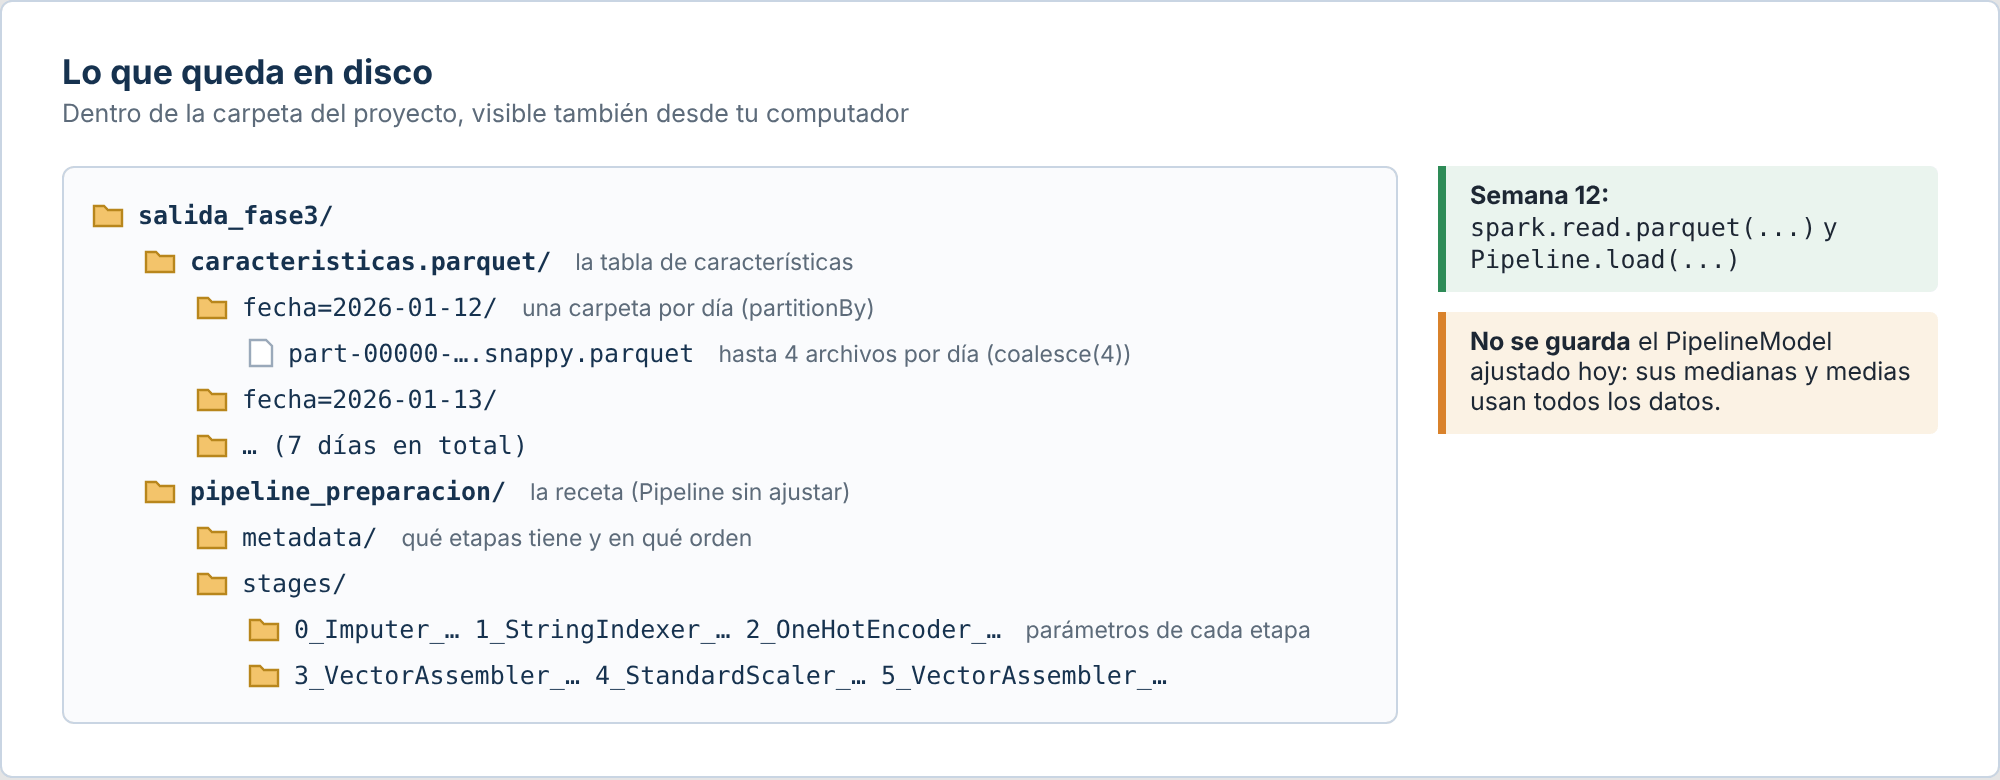

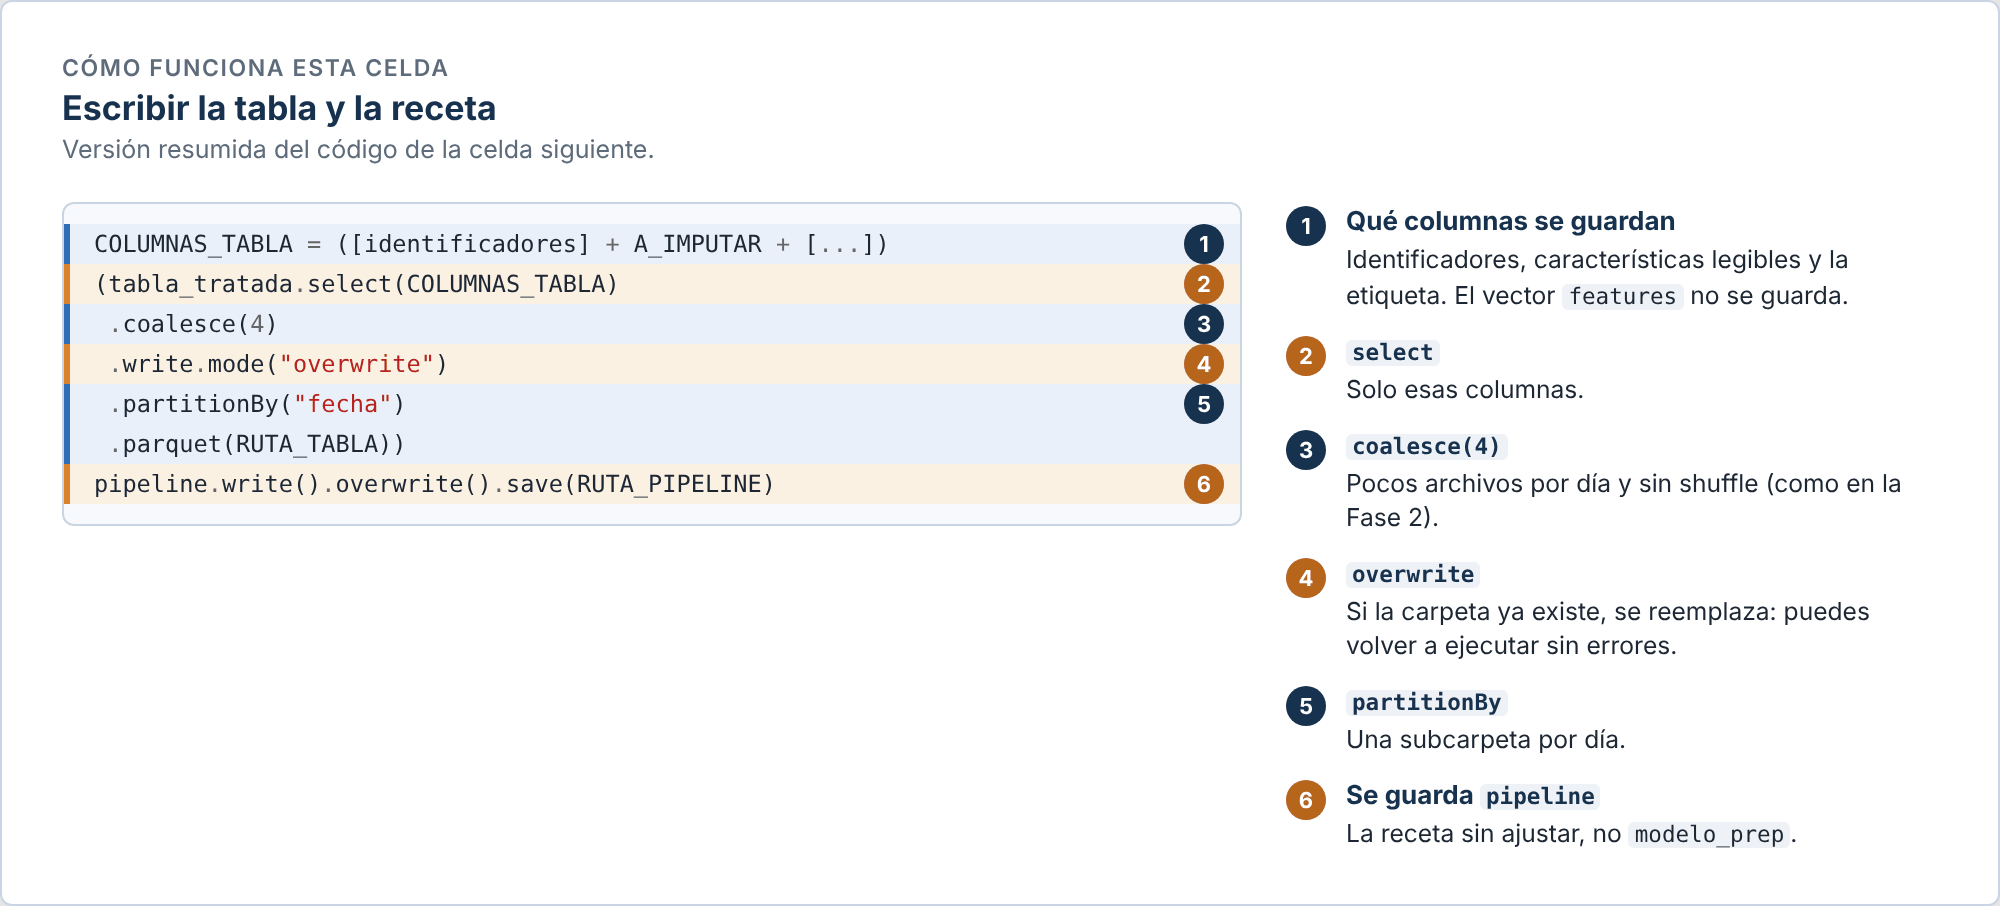

In [24]:
RUTA_TABLA    = f"{RUTA_SALIDA}/caracteristicas.parquet"
RUTA_PIPELINE = f"{RUTA_SALIDA}/pipeline_preparacion"

COLUMNAS_TABLA = (["entidad_id", "entidad_tipo", "alimentador_id", "variable",
                   "ventana_inicio", "fecha", "n_lecturas"]
                  + A_IMPUTAR + ["frac_confiable", "hora_sin", "hora_cos",
                                 "delta_faltante", "peor_calidad", "etiqueta"])

ini = time.time()
(tabla_tratada.select(COLUMNAS_TABLA)
 .coalesce(4)
 .write.mode("overwrite")
 .partitionBy("fecha")
 .parquet(RUTA_TABLA))

pipeline.write().overwrite().save(RUTA_PIPELINE)
caja(f"Escrito en {time.time() - ini:.1f} s<br> <code>{RUTA_TABLA}</code><br> <code>{RUTA_PIPELINE}</code>")

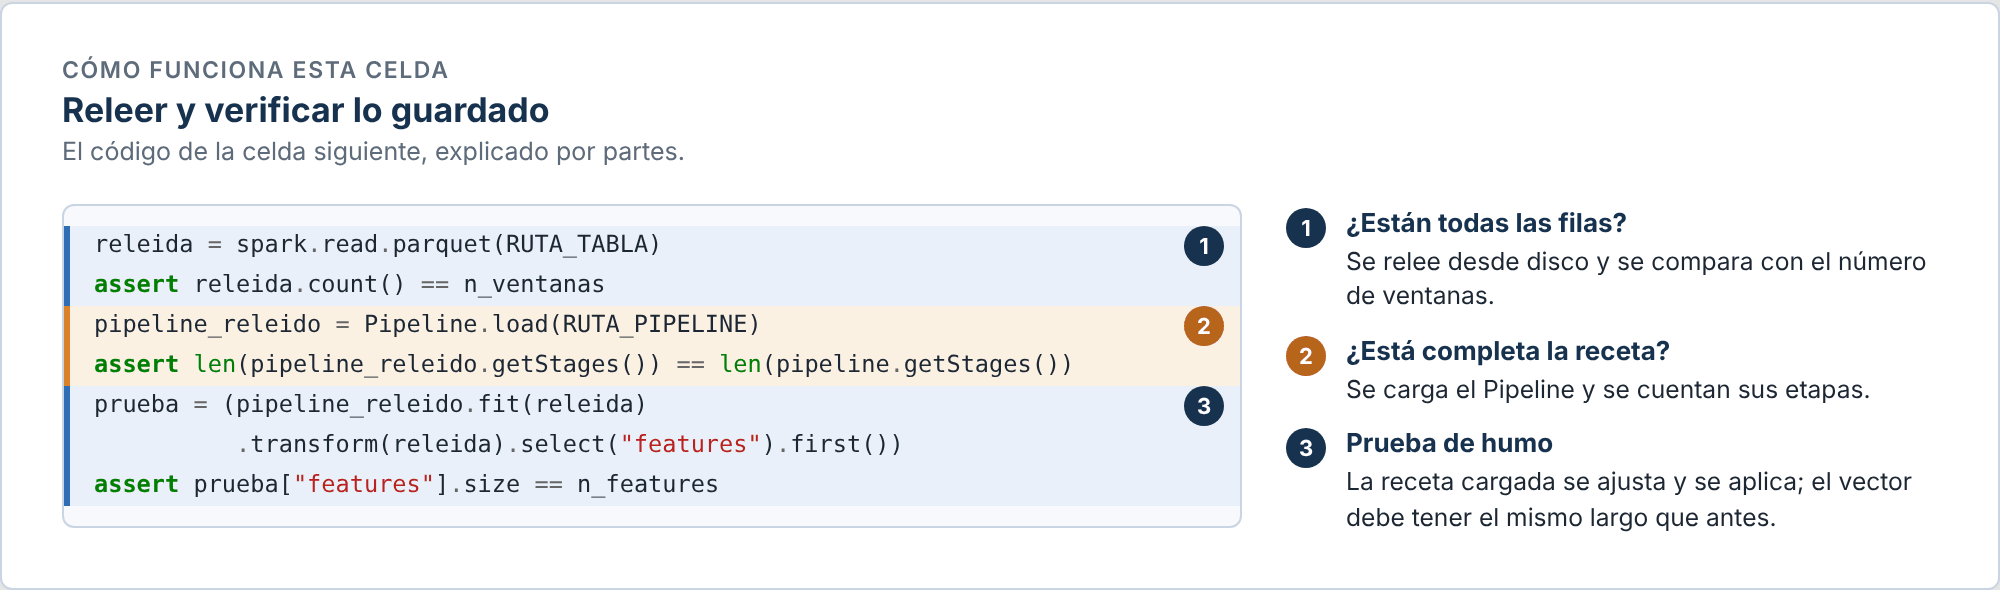

In [25]:
# --- Verificación: releer y comprobar que todo cuadra ---
releida = spark.read.parquet(RUTA_TABLA)
n_releida = releida.count()
assert n_releida == n_ventanas, f"La tabla cambió de tamaño: {n_ventanas:,} -> {n_releida:,}"

pipeline_releido = Pipeline.load(RUTA_PIPELINE)
assert len(pipeline_releido.getStages()) == len(pipeline.getStages())

# Prueba de humo: la receta cargada funciona sobre la tabla releída
prueba = pipeline_releido.fit(releida).transform(releida).select("features").first()
assert prueba["features"].size == n_features

tarjetas({"filas releídas": miles(n_releida),
          "etapas del pipeline": len(pipeline_releido.getStages()),
          "posiciones en 'features'": prueba["features"].size})
caja("La tabla y la receta se releen correctamente. <b>Todo listo para la semana 12.</b>",
     "ok", "Verificación completa")

---
## Cierre

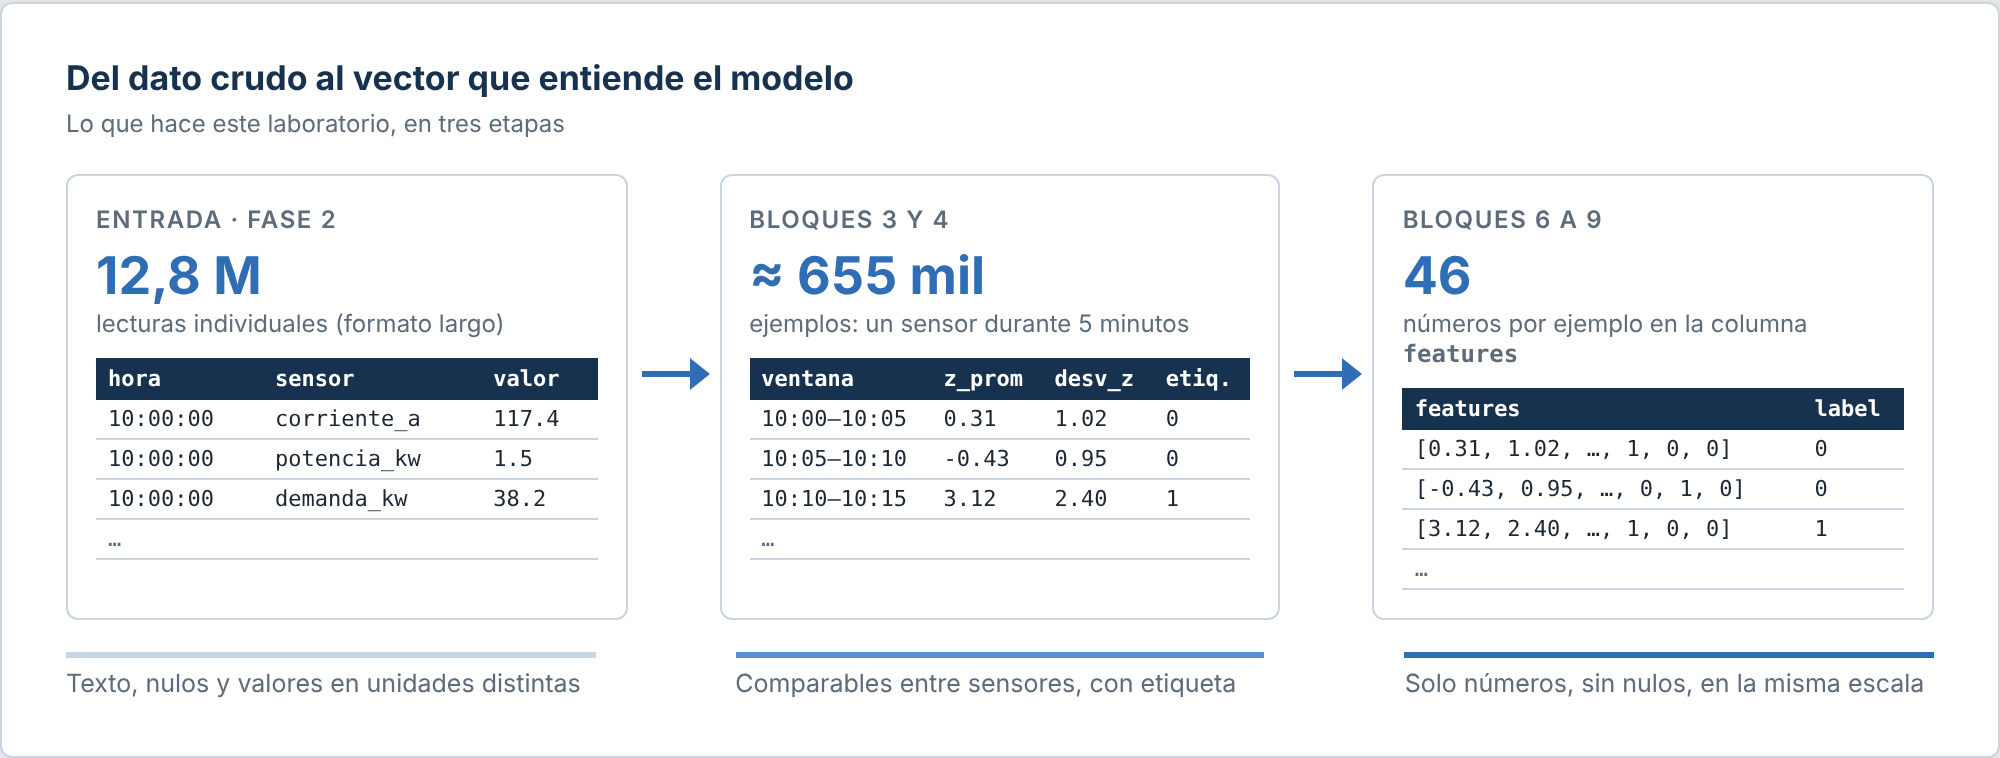

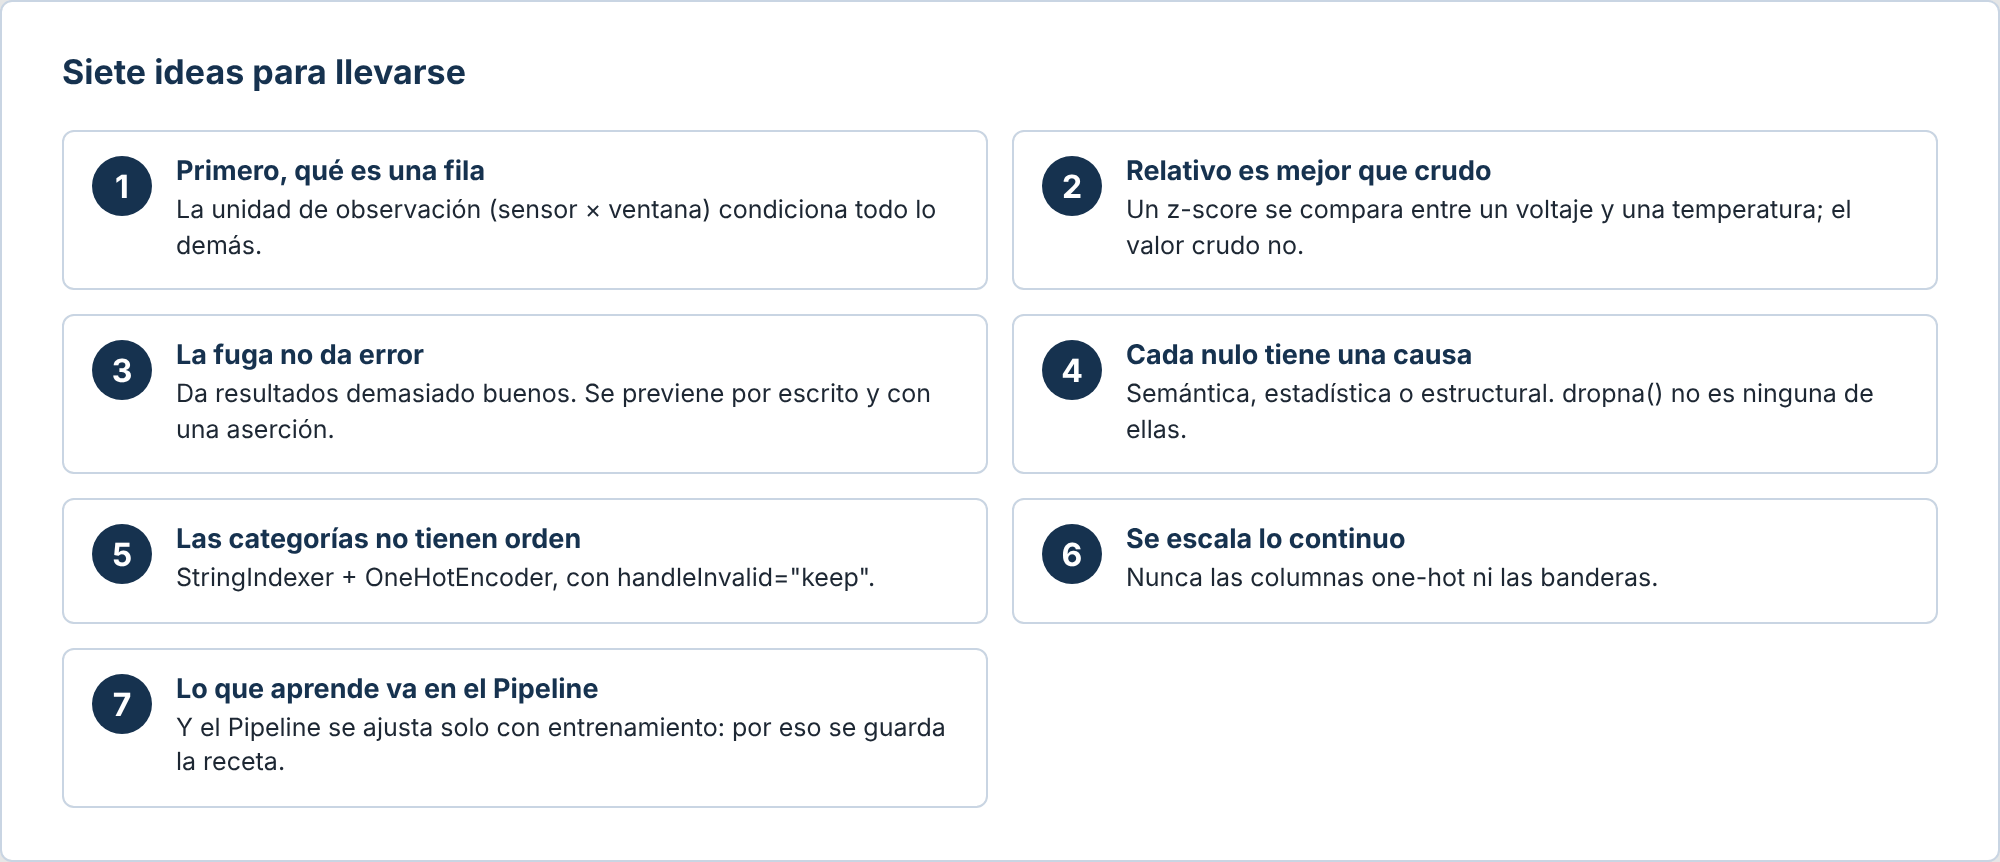

### Ejercicios

| # | Ejercicio | Pista |
|---|---|---|
| 1 | **El tamaño de la ventana.** Repite con `VENTANA = "1 minute"` y `"15 minutes"`. Anota: nº de ventanas, nulos en `desv`, % de fallas y la correlación `desv_z`–`rango_z`. ¿Cuál elegirías? | Cambia solo `VENTANA` (bloque 3.2) y ejecuta todo de nuevo |
| 2 | **Lecturas faltantes.** Crea `frac_lecturas = n_lecturas / n_esperado` según el tipo de entidad. ¿Por qué delataría un sensor desconectado? | Mira el gráfico de lecturas por ventana del bloque 3 |
| 3 | **Línea base sin fuga.** Calcula `linea_base` solo con el primer día. ¿Cuánto cambian los `z_prom` de los días siguientes? | `silver.filter(F.col("fecha") == ...)` |
| 4 | **`MinMaxScaler`.** Úsalo en vez de `StandardScaler`. ¿Qué pasa con un solo valor extremo? | Compara el rango de `z_prom` escalado |
| 5 | **Memoria del sensor.** Agrega la media móvil de `z_prom` de los últimos 30 min. ¿Por qué el límite es `-1` y no `0`? | `Window...rowsBetween(-6, -1)` |
| 6 | **Categorías nuevas.** Pon `handleInvalid="error"` en el `StringIndexer` y transforma una fila con `peor_calidad = "desconectado"`. ¿Qué pasa? | Compáralo con `"keep"` |

### La próxima semana

Cargaremos la tabla y la receta, separaremos **entrenamiento** y **prueba** respetando el orden del
tiempo, ajustaremos el pipeline **solo con entrenamiento** y entrenaremos nuestro **primer modelo**.

## Ejercicios resueltos y verificaciones de entrega

La línea base del recorrido principal usa todos los días únicamente para la demostración de preparación. Antes de evaluar un modelo temporal hay que recalcularla con entrenamiento: guardar el Pipeline sin ajustar no elimina una fuga ya introducida en las características. El ejercicio 3 mide aquí esa diferencia.

### Ejercicio 1 — Ventanas de 1, 5 y 15 minutos

Se mantiene la misma telemetría y línea base para aislar el efecto de la duración. Para cada tamaño se mide el número de ventanas, los nulos originales de `desv`, la proporción etiquetada y la correlación de `desv_z` con `rango_z` después del tratamiento semántico y la imputación de medianas del laboratorio.


In [26]:
import json
from pathlib import Path
resultados_ventana = []
for minutos in (1, 5, 15):
    v = (silver.withColumn("nivel_calidad", nivel)
         .groupBy("entidad_id", "entidad_tipo", "alimentador_id", "variable",
                  F.window("timestamp_utc", f"{minutos} minutes").alias("w"))
         .agg(F.stddev_samp("valor").alias("desv"), F.min("valor").alias("minimo"),
              F.max("valor").alias("maximo"), F.count("*").alias("n_lecturas"),
              F.max(F.col("en_falla").cast("int")).alias("etiqueta")))
    v = (v.join(F.broadcast(linea_base), ["entidad_id", "variable"], "left")
         .withColumn("desv_z", F.when(F.col("n_lecturas") < 2, F.lit(0.0))
                     .otherwise(dividir_seguro(F.col("desv"), F.col("base_desv"))))
         .withColumn("rango_z", dividir_seguro(F.col("maximo")-F.col("minimo"), F.col("base_desv")))
         .cache())
    resumen_v = v.agg(F.count("*").alias("ventanas"),
                      F.sum(F.col("desv").isNull().cast("int")).alias("nulos_desv"),
                      (100*F.avg("etiqueta")).alias("porcentaje_falla")).first().asDict()
    imp_v = Imputer(inputCols=["desv_z", "rango_z"], outputCols=["d", "r"], strategy="median")
    corr_v = imp_v.fit(v).transform(v).stat.corr("d", "r")
    resultados_ventana.append({"minutos":minutos, **resumen_v, "correlacion_desv_rango":corr_v})
    v.unpersist()
display(pd.DataFrame(resultados_ventana))
print("Elegimos 5 minutos como compromiso: 1 minuto ofrece más resolución pero más ventanas con una sola lectura; "
      "15 minutos mezcla intervalos normales y anómalos durante más tiempo. La decisión se apoya en la tabla; "
      "no demuestra que 5 minutos maximice una métrica predictiva, pues aquí no se entrenan modelos.")


,minutos,ventanas,nulos_desv,porcentaje_falla,correlacion_desv_rango
0,1,3264331,3191881,0.579230,0.992013
1,5,654789,109,0.597292,0.982568
2,15,218288,5,0.628069,0.925873


Elegimos 5 minutos como compromiso: 1 minuto ofrece más resolución pero más ventanas con una sola lectura; 15 minutos mezcla intervalos normales y anómalos durante más tiempo. La decisión se apoya en la tabla; no demuestra que 5 minutos maximice una métrica predictiva, pues aquí no se entrenan modelos.


### Ejercicio 3 — Línea base aprendida solo en el primer día

Se compara el z-score de las ventanas de los días siguientes calculado con ambas bases. No se consulta la etiqueta para estimar ninguna base. Usar el primer día evita consultar los días posteriores, pero no asegura que ese día sea libre de fallas. Las series sin variación o sin base válida conservan nulos para el tratamiento posterior.


In [27]:
primer_dia = silver.agg(F.min("fecha")).first()[0]
base_dia1 = (silver.filter((F.col("fecha") == F.lit(primer_dia)) & F.col("sensor_confiable"))
             .groupBy("entidad_id", "variable")
             .agg(F.avg("valor").alias("media_dia1"), F.stddev_samp("valor").alias("desv_dia1")))
posteriores = tabla_feat.filter(F.col("fecha") > F.lit(primer_dia))
comparacion_base = (posteriores.join(F.broadcast(base_dia1), ["entidad_id", "variable"], "left")
                   .withColumn("z_dia1", dividir_seguro(F.col("prom")-F.col("media_dia1"), F.col("desv_dia1"))))
assert comparacion_base.count() == posteriores.count()
comparacion_base = comparacion_base.withColumn("cambio_abs", F.abs(F.col("z_prom")-F.col("z_dia1")))
resultado_base = comparacion_base.agg(
    F.count("*").alias("ventanas_posteriores"),
    F.count("cambio_abs").alias("comparaciones_validas"),
    F.sum(F.col("z_dia1").isNull().cast("int")).alias("z_dia1_nulos"),
    F.avg("cambio_abs").alias("cambio_absoluto_medio"),
    F.max("cambio_abs").alias("cambio_absoluto_maximo")).first().asDict()
display(pd.DataFrame([resultado_base]))
print("Los z-scores cambian al cambiar el periodo de referencia. Para semana 12 hay que recalcular las "
      "características con una base aprendida exclusivamente en entrenamiento y aplicar esa misma base a prueba.")

# Validar TODOS los vectores, no solamente el primero.
from pyspark.ml.functions import vector_to_array
vectores = preparado.select(vector_to_array("features").alias("a"))
invalidos = vectores.filter(F.exists("a", lambda x: x.isNull() | F.isnan(x) | (F.abs(x) == F.lit(float("inf"))))).count()
assert invalidos == 0, f"Hay {invalidos} vectores con nulos, NaN o infinitos"
assert vectores.filter(F.size("a") != n_features).count() == 0
assert preparado.count() == n_ventanas
resumen_entrega = {"lecturas":n_silver, "ventanas":n_ventanas, "features":n_features,
                   "vectores_invalidos":invalidos, "primer_dia_base":str(primer_dia),
                   "clases":clases.to_dict(orient="records"), "ejercicio_1":resultados_ventana,
                   "ejercicio_3":resultado_base, "columnas_continuas":CONTINUAS,
                   "categoricas":CATEGORICAS, "etapas":len(pipeline.getStages())}
Path(RUTA_SALIDA, "resultados_lab11.json").write_text(json.dumps(resumen_entrega, indent=2, ensure_ascii=False), encoding="utf-8")
mapa.to_csv(Path(RUTA_SALIDA, "mapa_features.csv"), index=False)
print("Validación completa: todos los vectores son finitos y tienen la dimensión esperada.")
print("Contenido real de salida_fase3:")
for ruta in sorted(Path(RUTA_SALIDA).iterdir()): print(ruta.name + ("/" if ruta.is_dir() else ""))


,ventanas_posteriores,comparaciones_validas,z_dia1_nulos,cambio_absoluto_medio,cambio_absoluto_maximo
0,560732,558468,2264,0.040267,156.965752


Los z-scores cambian al cambiar el periodo de referencia. Para semana 12 hay que recalcular las características con una base aprendida exclusivamente en entrenamiento y aplicar esa misma base a prueba.


Validación completa: todos los vectores son finitos y tienen la dimensión esperada.
Contenido real de salida_fase3:
caracteristicas.parquet/
mapa_features.csv
pipeline_preparacion/
resultados_lab11.json


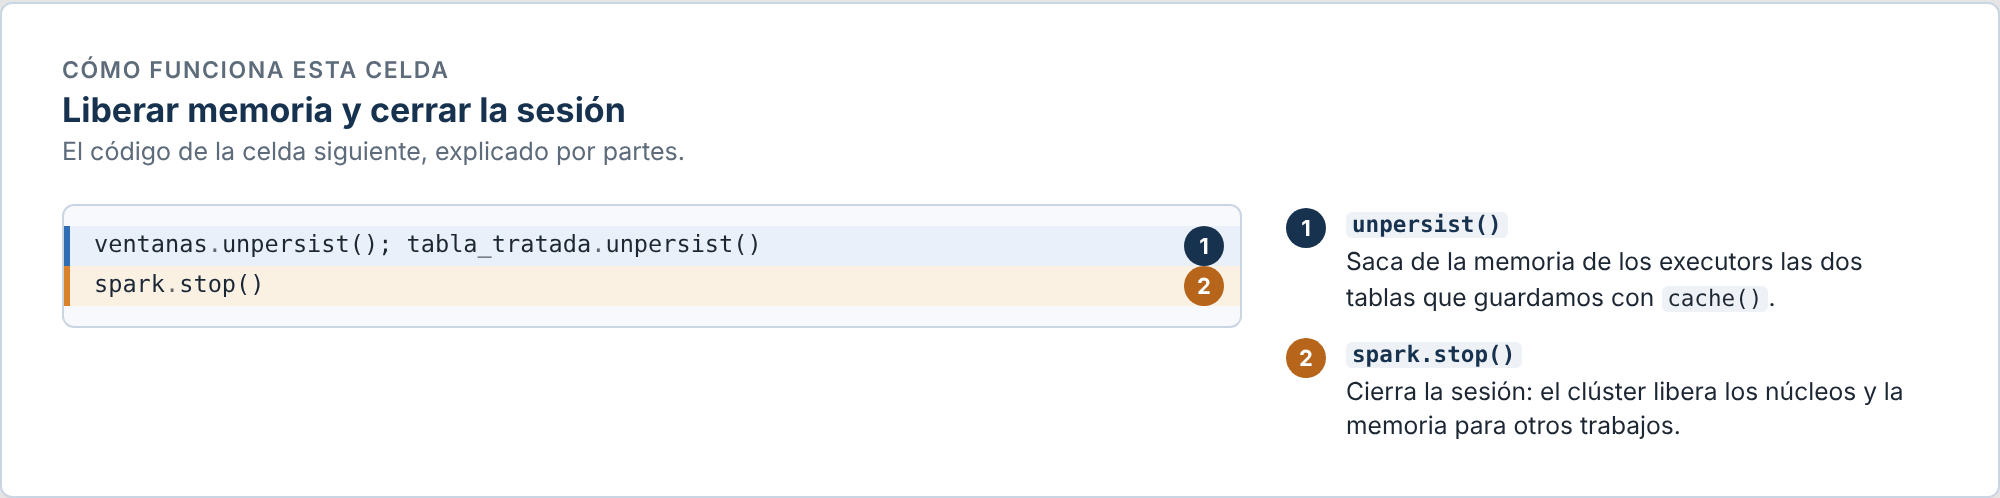

In [28]:
ventanas.unpersist(); tabla_tratada.unpersist()
spark.stop()
print("Sesión cerrada. Los workers quedan libres.")

Sesión cerrada. Los workers quedan libres.
